# Idol — DIMER Guided Notebook: one image to a 3D Gaussian splat (task inference, standalone)

[![GitHub](https://img.shields.io/badge/GitHub-181717?style=flat&logo=github&logoColor=white)](https://github.com/kurtvalcorza/idol-3d-pipeline) [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kurtvalcorza/idol-3d-pipeline/blob/main/tutorials/idol_3d_colab.ipynb) [![Hugging Face](https://img.shields.io/badge/%F0%9F%A4%97%20Hugging%20Face-speridlabs%2Fidol-ffcc4d?style=flat)](https://huggingface.co/speridlabs/idol) [![Upstream](https://img.shields.io/badge/Upstream-speridlabs%2Fidol--sdk-181717?style=flat&logo=github&logoColor=white)](https://github.com/speridlabs/idol-sdk) [![License](https://img.shields.io/badge/License-Apache--2.0-blue.svg)](https://www.apache.org/licenses/LICENSE-2.0)

**Profile:** `TASK-INFERENCE`  
**Mode:** `GUIDED`  
**Notebook specification:** DIMER Notebook Specification 3.1 — **standalone** (§4)  
**Capability:** single-image to 3D Gaussian splat generation with Idol (a 0.37 B-parameter flow-matching DiT with octree and Gaussian decoders), on Apache-2.0 FLUX.2 [klein] VAE conditioning in place of the non-commercial FLUX.2 [dev] VAE, with structural, file and input-view silhouette checks

**This notebook is standalone.** Section 2 carries the repository's package (5 modules under `src/idol_3d_pipeline/`, at revision `169da75c3001`), the Idol SDK carried verbatim (13 modules under `src/idol/`, upstream commit `8db7003`), the stage runner, the hash-locked requirements (73 packages), the 3 snapshot manifests and the licence, and verifies every carried file against its SHA-256 before use, so the notebook keeps working after export even if the repository changes or disappears. Nothing is installed into the notebook kernel: a pinned `uv` (checked by size and SHA-256) builds an isolated Python environment from the lock with `--require-hashes`, and every stage runs there in its own process, so the hosted runtime's own packages are never replaced and no restart is needed. Its only external dependencies are PyPI, the managed CPython build that `uv` downloads, the Hugging Face Hub at the immutable revision `2731c2291fc65a797c5cb627a5e5526fc1490902` (~3079 MB, digest-verified before loading), the further pinned snapshots and the sample source named in the Prerequisites. It was generated by `tools/build_notebook.py` (build_notebook.py/3.1-token); edit the repository and regenerate rather than editing cells.

**Run all:** Selecting **Run all** in a fresh Linux runtime with a CUDA GPU (a Colab T4 is the documented target) and an `HF_TOKEN` secret (see **Credential** in the Prerequisites) builds an isolated Python environment from the carried hash-locked requirements (torch, transformers, diffusers, tensordict and their dependencies) without touching the notebook kernel's own packages, then runs each stage below in its own process: it stages and digest-verifies three pinned snapshots (Idol's 3.08 GB of weights, the 0.17 GB FLUX.2 [klein] VAE and the 3.36 GB DINOv3 ViT-H+/16 encoder; 6.6 GB in all), fetches three pinned sample images (two from the Idol SDK, one CC0 photograph), validates them, turns each into a 3D Gaussian splat of 262,144 Gaussians written as a standard 3DGS `.ply`, and checks and previews every splat. The default path needs no repository clone, no DIMER worker or service, no upload dialog, no configuration edit and no runtime restart; it does need the token above. The default path has run on a fresh Colab T4, executed by the Colab CLI rather than a browser Run all (see `docs/release-verification.md`).

**Bring Your Own Data:** After the default path completes, Section 9 runs the same validation, generation and checks on your own images: set `USE_BYOD = True`, choose `BYOD_MODE` — `'real'` for photographs (a looser crop) or `'synthetic'` for renders and generated images — and either set `BYOD_PATH` to an image, folder or zip already in the runtime or leave it empty to get an upload dialog. Up to four images are used; each takes about as long as one sample in Section 5. Uploaded files stay inside this runtime. BYOD is optional and never part of the default path.

Idol [1] turns one picture of an object into a 3D Gaussian splat: up to a million small, coloured, semi-transparent 3D blobs that together form the object, including the sides the picture never showed. Six networks run in order. **BiRefNet** [5] cuts the object out and the image is framed on black at 1024 × 1024. Two image encoders read it: **DINOv3** [4] for what the object is, and the **FLUX.2 VAE** [7] for how its pixels look. A **diffusion transformer** trained with flow matching [3] turns noise into an 8,192 × 16 object latent and a predicted camera in 50 Euler steps with classifier-free guidance. An **octree decoder** places anchor points on a 256³ grid, and a **Gaussian decoder** turns each anchor into 32 Gaussians [2], written as a `.ply` any splat viewer opens.

One change sets this notebook apart from the upstream SDK. Idol's own configuration loads the VAE from `black-forest-labs/FLUX.2-dev`, which is under the FLUX Non-Commercial License. This notebook loads the same VAE architecture from `black-forest-labs/FLUX.2-klein-4B`, released under Apache-2.0; its configuration names FLUX.2-dev as its origin, and the optional Section 8 tests whether the weights are the same. Nothing is trained here: this is a pretrained model used as published, which is why the profile is task inference.

**Learning objectives:** by the end of this notebook you will be able to —

1. **Explain** the input → output contract of single-image 3D generation and what each of Idol's five networks contributes (Sections 4–5).
2. **Identify** an invalid request from a validation refusal before any model runs (Section 4).
3. **Interpret** a Gaussian splat's structure: count, bounds, opacity and scale (Section 6).
4. **Compute and interpret** the silhouette agreement between a splat rendered from the predicted camera and the object mask, and **state** what that check cannot establish about the unseen sides (Section 6).
5. **Explain** how a licence constraint was met by replacing one component, and what evidence would show the replacement changes nothing (Sections 3 and 8).
6. **Write** an evidence-based conclusion that names the checks run and their limits (Interpretation and conclusion).

**This notebook does not demonstrate:** fine-tuning or training (Idol publishes no training recipe), scene or multi-object reconstruction, text-to-3D, mesh extraction, the 3D Gaussian Splatting CUDA rasterizer (previews use an approximate NumPy renderer), any quality score for the unseen sides (there is no ground-truth 3D here), and any use of FLUX.2-dev on the default path.

## Use notice

Provided for research, training and evaluation purposes only. The model weights are fetched unmodified from their upstream locations under their own licences (Idol and the FLUX.2 [klein] VAE: Apache-2.0; DINOv3: the DINOv3 License — Built with DINOv3), which control your use; this notebook's code is Apache-2.0. Everything is supplied as is, without warranty, and has not been validated for production or safety-critical use. Running it downloads third-party weights and uses compute on your own account. The splats are predictions: the sides the picture does not show are generated, not measured.

## Problem statement

A single photograph of an object fixes only one side of it. Turning it into a 3D object a viewer can rotate means predicting the rest. This notebook asks what a learner can check about such a prediction without any 3D ground truth, and shows how a licence constraint on one component (the FLUX.2-dev VAE) was met without retraining the model.

## Data context

Three default inputs. Two are example images from the Idol SDK's own demo (`demo/examples/` in [speridlabs/idol-sdk](https://github.com/speridlabs/idol-sdk/tree/8db700349a5570aac390e4780fa32e3eed6b587a/demo/examples) at commit `8db7003`, Apache-2.0), run with the settings in its `presets.json`. The SDK does not say how they were made; their style suggests renders or generated images, the `synthetic` input kind Idol's default mode is for. The third is a CC0 photograph of one porcini mushroom from iNaturalist (observation [187524159](https://www.inaturalist.org/observations/187524159), photo 327959642, by moorebuesing), run in `real` mode, so both crop settings and a natural background are on the default path. Idol's training data is not described upstream, so the demo images may resemble, or come from the same source as, what the model was trained on: treat every result here as tutorial evidence about these three images, not as an estimate of how Idol does on new objects. Your own photographs go through Section 9 in `real` mode.

## How to use this notebook

**Running it.** In Colab choose *Runtime → Change runtime type → T4 GPU*, add the `HF_TOKEN` secret (key icon on the left; switch on notebook access), then *Runtime → Run all*. Sections 1–3 build the isolated environment and download about 5 GB of weights before any model runs; read ahead while they finish.

**Where the code runs.** The notebook kernel installs nothing and imports no model library. Each learner cell calls `run_stage('…')`, which runs one stage of the carried stage runner in its own process with the isolated environment's Python, streams what it prints, and stops the notebook with the stage's own error message if it fails.

**Two kinds of cell.** *Learner cells* (Sections 4–9) are the workflow; *Infrastructure cells* (Sections 1–3) are collapsed and titled **Infrastructure**. You may run them without studying them: they exist for reproducibility and provenance.

**Predict, then check.** Before each principal result a **Predict before running** prompt asks you to commit to an expectation; a collapsed **Check your reasoning** answer follows.

## The task: Input → Model/System → Output

| Stage | Input | Model / system | Output |
|---|---|---|---|
| **Framing** | one image of one object | BiRefNet mask (unless the image has alpha) → 1 px erosion → square crop at 1.2× (synthetic) or 1.7× (real) the object → 1024 px on black | the model input and its object mask |
| **Generation** | the model input | DINOv3 tokens + FLUX.2 VAE latents → flow-matching DiT, 50 steps, guidance 3.0 → octree decoder → Gaussian decoder | 262,144 Gaussians and a predicted camera |
| **Checks** | the Gaussians, the `.ply`, the mask, the camera | structure and bounds; `.ply` read-back; render from the predicted camera and compare silhouettes | a record per sample and preview images |

## Roadmap

| Section | Tag | What happens |
|---|---|---|
| 1–3 | [Engineering] | runtime check; carried code, token and isolated environment; three snapshots staged and verified |
| 4 | [Evaluation practice] | three sample images (two synthetic, one photograph) and refusal probes |
| 5 | [Concept] | Idol generates a splat for each sample |
| 6 | [Evaluation practice] | structure, file and silhouette checks; previews |
| 7 | [Engineering] | the files you can take away; 7b optional activity: change one thing |
| Interpretation and conclusion | [Evaluation practice] | limits and an evidence-based conclusion |
| 8 | [Evaluation practice] | optional: is the klein VAE the dev VAE? (needs FLUX.2-dev access) |
| 9 | [Evaluation practice] | optional: Bring Your Own Data |

<details>
<summary><strong>Glossary</strong> — open when a term is unfamiliar</summary>

| Term | Meaning in this notebook |
|---|---|
| **3D Gaussian splat** | A 3D object represented as many anisotropic Gaussians, each with a position, scale, rotation, opacity and colour, drawn by blending their 2D footprints. |
| **3DGS `.ply`** | The file layout of Kerbl et al. (2023): one vertex per Gaussian with fields `x … rot_3`; splat viewers read it. |
| **Flow matching** | Training a network to predict the velocity that carries noise to data; sampling integrates that velocity in steps. |
| **Classifier-free guidance** | Each step also runs with the image conditioning zeroed and moves away from that result; strength 3.0 here. |
| **VAE** | Variational autoencoder; here only its encoder is used, to turn the image into a 128-channel latent grid. |
| **Octree** | A cube split recursively into eight children; Idol's decoder decides how many points each child gets, down to a 256³ grid. |
| **Silhouette IoU** | Intersection over union of two binary shapes: the rendered splat's coverage and the object mask, 1.0 when they coincide. |
| **Gated model** | A Hub repository that serves files only to accounts that accepted its terms. |
</details>

## Prerequisites

- **Runtime:** a fresh **Linux x86_64** runtime with a **CUDA GPU**; a Colab T4 (16 GB) is the documented target. Idol's card gives a 7.2 GB VRAM peak per request. The generation stage refuses a CPU-only runtime with a message (tens of minutes per image otherwise). The kernel's own Python version does not matter: the notebook installs nothing into it and runs every stage with CPython 3.12.12 in an isolated environment built from 73 hash-locked packages. The Section 1 check asks for about 9 GB of free disk for that environment and 5.5 GB for the weights and samples.
- **Time:** not yet measured for this notebook; the figures here are estimates. Idol's card reports 54.6 s per image on an L4 with compilation on; this notebook runs eagerly by default (`OPTIMIZE = False` in Section 5), which is slower but avoids a compile step on the T4. Downloading about 6.6 GB of weights takes several minutes.
- **Precision, seeds and variation:** DINOv3 and the FLUX.2 VAE run in bf16, BiRefNet in fp16 on CUDA, the denoiser and decoders as the SDK sets them (fp16 transformer blocks with fp32 embeddings and norms). Each sample uses its preset seed (42 for the backpack, 7 for the armchair, 42 for the porcini photograph); BYOD uses seed 42. GPU kernels are not bitwise deterministic, so splats and the scores in Section 6 can differ slightly between runs and GPUs.
- **Knowledge:** you can run notebook cells and read short Python. No prior experience with 3D reconstruction is assumed; the glossary defines the terms.
- **Weights:** only `.safetensors` files are loaded, each checked by size and SHA-256 against the carried manifests before any model code runs. The Idol SDK is carried verbatim at commit `8db7003` (Apache-2.0) and verified like every carried file; no Hub-hosted code is executed. Idol's weights and the klein VAE are Apache-2.0; DINOv3 is under the DINOv3 License.
- **Pin status:** all three snapshots are pinned by commit and per-file size and SHA-256 (DINOv3's recorded with access to the gated repository on 2026-11-10); any mismatch stops Section 3 before a model loads.
- **Data contract:** one RGB or RGBA image of one object, 64..4096 px per side. Without a real alpha channel BiRefNet predicts the object mask. Output: a 3DGS `.ply` (z-up object turned y-up for viewers), the 1024 × 1024 image Idol saw, its object mask, and the predicted camera (yaw, pitch, radius, field of view).
- **Privacy:** Do not upload confidential or restricted data to a hosted runtime unless you are authorized to process it there. The default path uploads nothing, and BYOD files stay in this runtime.
- **External access (samples):** two pinned images (70 KB) from `raw.githubusercontent.com/speridlabs/idol-sdk` at commit `8db7003` (an Apache-2.0 repository; the SDK does not state how they were made) and one CC0 photograph (379 KB) from the public iNaturalist open-data bucket `inaturalist-open-data.s3.amazonaws.com`, each digest-verified before decoding.
- **External access:** the Hugging Face Hub, to fetch the `speridlabs/idol` snapshot (~3079 MB) at the revision in the carried manifest (`2731c2291fc6`); the `black-forest-labs/FLUX.2-klein-4B` VAE (`vae/` only, 168 MB) and the gated `facebook/dinov3-vith16plus-pretrain-lvd1689m` encoder (3.36 GB) at the revisions in their manifests, with the token below; `raw.githubusercontent.com` and `inaturalist-open-data.s3.amazonaws.com` for the three sample images; PyPI (`files.pythonhosted.org`), for the pinned `uv` wheel and the 73 hash-locked packages; and the managed CPython build (python-build-standalone) that `uv` downloads for the isolated environment. No repository clone is required; nothing is installed from this repository. **Credential:** a Hugging Face token, read from this runtime's secrets as `HF_TOKEN` by the Section 2 Token cell, of an account that has accepted the DINOv3 terms at https://huggingface.co/facebook/dinov3-vith16plus-pretrain-lvd1689m (approval is manual and can take a while). It is passed only to the `weights` stage (for that gated snapshot) and, if you switch it on, the optional `vae_check` stage (for FLUX.2-dev); uv, the package install and every other stage run without it, and it is never printed or written to disk. Because the default path needs it, this notebook does not meet NOTEBOOK_SPEC RUN13/MOD4 (nor RUN14 or REL6, which follow from them) and stays a Candidate (see STATUS.md).

## 1. Check the runtime [Engineering]

This cell refuses anything but Linux x86_64, reports the GPU, checks free disk, and creates this session's run directory.

In [ ]:
# @title Infrastructure: check the runtime, accelerator and disk; create or keep this session's run directory
NEW_RUN_DIRECTORY = False  # @param {type:"boolean"}
import hashlib
import json
import os
import platform
import shutil
import subprocess
import tempfile
import time
import uuid
from pathlib import Path

SESSION_START = time.perf_counter()
if platform.system() != 'Linux' or platform.machine() != 'x86_64':
    raise RuntimeError('This notebook needs a Linux x86_64 runtime (Google Colab, Kaggle, or a Linux Jupyter kernel): its locked environment is built for manylinux x86_64 wheels. Windows, macOS and ARM kernels are refused.')
try:
    probe_gpu = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'], capture_output=True, text=True)
    GPU = probe_gpu.stdout.strip() if probe_gpu.returncode == 0 and probe_gpu.stdout.strip() else None
except FileNotFoundError:
    GPU = None
STEM = 'idol_3d'
REQUIRE_GPU = "Idol's generation stage needs a CUDA GPU (on a CPU it would take an estimated tens of minutes per image), so this notebook stops here rather than after building the environment and downloading about 6.6 GB."
RUNS = Path.cwd() / 'outputs' / STEM
# Re-running this cell on its own keeps the run directory of this session, so the cells after it keep working; only a
# new kernel (or NEW_RUN_DIRECTORY) starts a fresh one, which then needs Sections 2 and 3 again.
previous_root = globals().get('ROOT')
if not NEW_RUN_DIRECTORY and isinstance(previous_root, Path) and previous_root.parent == RUNS and previous_root.is_dir():
    ROOT = previous_root
    print('Keeping the run directory of this session:', ROOT, '(tick NEW_RUN_DIRECTORY for a fresh one, then run Sections 2 and 3 again).')
else:
    ROOT = RUNS / uuid.uuid4().hex[:12]
    ROOT.mkdir(parents=True)
WEIGHTS = Path.cwd() / 'weights'
WEIGHTS.mkdir(exist_ok=True)
# The isolated environment is keyed on the lock digest, the managed Python and the uv version, not on the run: a later
# Run all in the same runtime reuses a complete environment built from the same lock instead of building another.
ENV_KEY = 'b0183e2b81dcfe2b'
ENV_ROOT = Path(tempfile.gettempdir()) / (STEM + '_env_' + ENV_KEY)
staged_gib = sum(p.stat().st_size for p in WEIGHTS.rglob('*') if p.is_file()) / 1024**3
need = {'weights': max(0.0, 7.5 - staged_gib), 'environment': 0.0 if (ENV_ROOT / 'ready.json').is_file() else 9.0}
free = {'weights': shutil.disk_usage(WEIGHTS).free / 1024**3, 'environment': shutil.disk_usage(tempfile.gettempdir()).free / 1024**3}
if os.stat(WEIGHTS).st_dev == os.stat(tempfile.gettempdir()).st_dev:
    short = free['weights'] < need['weights'] + need['environment']
else:
    short = free['weights'] < need['weights'] or free['environment'] < need['environment']
if short:
    raise RuntimeError(f'Not enough free disk: need about {need} GiB, free {free} GiB. Start a fresh runtime (see Troubleshooting).')
if REQUIRE_GPU and not GPU:
    raise RuntimeError('No GPU is attached. ' + REQUIRE_GPU + ' In Colab choose Runtime -> Change runtime type -> T4 GPU, then Run all; nothing has been downloaded yet.')
print({'gpu': GPU or 'none: the stages will run on the CPU (slower; see Prerequisites)', 'kernel_python': platform.python_version(), 'run_directory': str(ROOT), 'weights': str(WEIGHTS), 'environment': str(ENV_ROOT), 'free_gib': {k: round(v, 1) for k, v in free.items()}})

{'gpu': 'Tesla T4, 15360 MiB', 'kernel_python': '3.13.16', 'run_directory': '/content/outputs/idol_3d/b396c789b1a0', 'weights': '/content/weights', 'environment': '/tmp/idol_3d_env_b0183e2b81dcfe2b', 'free_gib': {'weights': 235.6, 'environment': 235.6}}


## 2. Carry the code, read the token, install the runtime [Engineering]

The next cell writes the repository's package, the vendored Idol SDK, the stage runner, the hash lock and the three snapshot manifests into the run directory, and verifies each against its SHA-256.

In [ ]:
# @title Infrastructure: write and verify the carried package, stage runner, lock and manifests
CARRIED_FILES = {'src/idol_3d_pipeline/__init__.py': '"""Idol single-image to 3D Gaussian splat pipeline for DIMER (task inference)."""\n\nfrom .metrics import ply_roundtrip, read_ply, silhouette_iou, splat_summary\nfrom .pipeline import (\n    DEFAULT_GAUSSIANS,\n    MODEL_ID,\n    MODEL_KEY,\n    MODEL_LICENSE,\n    MODEL_REVISION,\n    MODES,\n    SDK_COMMIT,\n    SNAPSHOTS,\n    IdolSplatPipeline,\n    InputRefused,\n    UnpinnedSnapshotError,\n    encoder_overrides,\n    gaussian_arrays,\n    prepare_with_mask,\n    read_manifest,\n    require_pinned,\n    stage_snapshot,\n    validate_request,\n    verify_snapshot,\n)\nfrom .render import CALIBRATION, CONVENTIONS, calibrated, camera_pose, orbit, render\nfrom .samples import SAMPLES, fetch_samples, open_sample\n\n__all__ = [\n    "CALIBRATION",\n    "CONVENTIONS",\n    "DEFAULT_GAUSSIANS",\n    "MODEL_ID",\n    "MODEL_KEY",\n    "MODEL_LICENSE",\n    "MODEL_REVISION",\n    "MODES",\n    "SAMPLES",\n    "SDK_COMMIT",\n    "SNAPSHOTS",\n    "IdolSplatPipeline",\n    "InputRefused",\n    "UnpinnedSnapshotError",\n    "calibrated",\n    "camera_pose",\n    "encoder_overrides",\n    "fetch_samples",\n    "gaussian_arrays",\n    "open_sample",\n    "orbit",\n    "ply_roundtrip",\n    "prepare_with_mask",\n    "read_manifest",\n    "read_ply",\n    "render",\n    "require_pinned",\n    "silhouette_iou",\n    "splat_summary",\n    "stage_snapshot",\n    "validate_request",\n    "verify_snapshot",\n]\n', 'src/idol_3d_pipeline/pipeline.py': '"""Single-image to 3D Gaussian splat with Idol (``speridlabs/idol``), on licence-clean encoders.\n\nIdol\'s published ``config.json`` loads two gated image encoders: DINOv3 ViT-H+/16 and the VAE of\n``black-forest-labs/FLUX.2-dev`` (FLUX Non-Commercial License). This package loads Idol through the upstream SDK\n(carried verbatim under ``src/idol`` at a pinned commit) with both encoders replaced by local, digest-verified\nsnapshots:\n\n* ``flux2-vae-klein`` -- the VAE of ``black-forest-labs/FLUX.2-klein-4B`` (Apache-2.0, ungated), presumed to be the\n  FLUX.2 [dev] VAE stored in bf16 (the optional ``vae_check`` stage of the tutorial tests that presumption); and\n* ``dinov3-vith16plus`` -- DINOv3 ViT-H+/16 from its gated origin, fetched with the runtime\'s ``HF_TOKEN``.\n\nFLUX.2-dev is never contacted on the default path. Every snapshot is pinned by an immutable Hub commit and per-file\ndigests recorded in ``weights/<key>/dimer-base-manifest.json``; a snapshot whose manifest lacks digests (DINOv3 until\n``tools/pin_snapshot.py`` has run with access) is refused, never trusted on first use.\n\nThis module imports only the standard library, NumPy and Pillow at import time; torch and the SDK are imported when a\nmodel is loaded, so the contract and verification code is testable without them.\n"""\n\nfrom __future__ import annotations\n\n# ruff: noqa: E501  -- refusal messages name the condition and the corrective action on one line\nimport hashlib\nimport json\nimport os\nimport time\nfrom collections.abc import Callable\nfrom dataclasses import dataclass\nfrom pathlib import Path\nfrom typing import Any\n\nimport numpy as np\nfrom PIL import Image, ImageFilter\n\nMODEL_ID = "speridlabs/idol"\nMODEL_REVISION = "2731c2291fc65a797c5cb627a5e5526fc1490902"\nMODEL_LICENSE = "apache-2.0"\nMODEL_KEY = "idol"\nSDK_REPOSITORY = "speridlabs/idol-sdk"\nSDK_COMMIT = "8db700349a5570aac390e4780fa32e3eed6b587a"\nMANIFEST_NAME = "dimer-base-manifest.json"\nPIN_COMMAND = "python tools/pin_snapshot.py"\nDEFAULT_WEIGHTS_ROOT = Path(__file__).resolve().parents[2] / "weights"\n\n# Snapshot key -> Hub id, revision, the encoder it replaces in Idol\'s config.json (None for Idol itself), gating.\nSNAPSHOTS: dict[str, dict[str, Any]] = {\n    MODEL_KEY: {"model_id": MODEL_ID, "revision": MODEL_REVISION, "encoder": None, "gated": False, "license": "apache-2.0"},\n    "flux2-vae-klein": {\n        "model_id": "black-forest-labs/FLUX.2-klein-4B",\n        "revision": "e7b7dc27f91deacad38e78976d1f2b499d76a294",\n        "encoder": "flux2_vae",\n        "gated": False,\n        "license": "apache-2.0",\n    },\n    "dinov3-vith16plus": {\n        "model_id": "facebook/dinov3-vith16plus-pretrain-lvd1689m",\n        "revision": "c807c9eeea853df70aec4069e6f56b28ddc82acc",\n        "encoder": "dinov3",\n        "gated": True,\n        "license": "dinov3-license",\n    },\n}\n# The encoders Idol\'s own config.json names; the pipeline replaces both and checks that the replacement is complete.\nUPSTREAM_ENCODERS = {"dinov3": "facebook/dinov3-vith16plus-pretrain-lvd1689m", "flux2_vae": "black-forest-labs/FLUX.2-dev"}\nNON_COMMERCIAL_ORIGIN = "black-forest-labs/FLUX.2-dev"\n\n# Input contract (Idol resizes the short side to 1024 px; the limits keep a hosted runtime\'s memory bounded).\nMODES = ("synthetic", "real")  # crop margin 1.2 (renders, generated images) or 1.7 (photographs), from the SDK\nMIN_INPUT_SIDE = 64\nMAX_INPUT_SIDE = 4096\nMIN_GAUSSIANS, MAX_GAUSSIANS, GAUSSIANS_PER_ANCHOR = 32_768, 1_048_576, 32\nDEFAULT_GAUSSIANS = 262_144\nMAX_STEPS = 100\nIMAGE_SIZE = 1024  # Idol config.json "image_size"\nSH_C0 = 0.28209479177387814  # degree-0 spherical-harmonic constant: rgb = 0.5 + SH_C0 * f_dc\n\n\nclass UnpinnedSnapshotError(RuntimeError):\n    """A manifest carries no immutable revision, or a file without a recorded digest."""\n\n\nclass InputRefused(ValueError):\n    """A user-supplied input breaks the data contract. The tutorial shows it as one message, without a traceback (DAT20)."""\n\n\nACCEPTED_PIL_MODES = ("RGB", "RGBA", "L", "LA", "P")  # anything else is refused; L/LA/P are converted to RGB(A), and the record says so\n\n\n# ---------------------------------------------------------------------------------------------------------\n# Snapshot manifests\n# ---------------------------------------------------------------------------------------------------------\n\n\ndef sha256_file(path: Path) -> str:\n    digest = hashlib.sha256()\n    with open(path, "rb") as fh:\n        for chunk in iter(lambda: fh.read(1 << 20), b""):\n            digest.update(chunk)\n    return digest.hexdigest()\n\n\ndef git_blob_sha1(data: bytes) -> str:\n    """The Hub\'s ``oid`` for a non-LFS file: SHA-1 over ``b"blob <len>\\\\0" + data``."""\n    return hashlib.sha1(b"blob %d\\0" % len(data) + data).hexdigest()\n\n\ndef read_manifest(key: str, weights_root: str | Path | None = None) -> dict[str, Any]:\n    root = Path(weights_root) if weights_root is not None else DEFAULT_WEIGHTS_ROOT\n    path = root / key / MANIFEST_NAME\n    if not path.is_file():\n        raise FileNotFoundError(f"manifest not found: {path}")\n    return json.loads(path.read_text(encoding="utf-8"))\n\n\ndef require_pinned(key: str, manifest: dict[str, Any]) -> None:\n    """Refuse a manifest that does not match the package pins or lists a file without size and SHA-256."""\n    expected = SNAPSHOTS[key]\n    if manifest.get("modelId") != expected["model_id"] or manifest.get("revision") != expected["revision"]:\n        raise ValueError(\n            f"{key}: manifest pins {manifest.get(\'modelId\')}@{manifest.get(\'revision\')}, package pins {expected[\'model_id\']}@{expected[\'revision\']}; regenerate the notebook from one repository revision"\n        )\n    unpinned = [entry["path"] for entry in manifest.get("files", []) if not entry.get("sha256") or not entry.get("bytes")]\n    if unpinned:\n        hint = " with an HF_TOKEN whose account has accepted the model\'s terms" if expected["gated"] else ""\n        raise UnpinnedSnapshotError(\n            f"{key} ({expected[\'model_id\']}) has no recorded size/SHA-256 for {unpinned}: run `{PIN_COMMAND} {key}`{hint}, commit the manifest, then regenerate the notebook. Unverified weights are never loaded."\n        )\n\n\ndef verify_snapshot(key: str, weights_root: str | Path | None = None) -> dict[str, Any]:\n    """Check every manifest-listed file of one snapshot by size and SHA-256; raise naming the first mismatch."""\n    root = Path(weights_root) if weights_root is not None else DEFAULT_WEIGHTS_ROOT\n    manifest = read_manifest(key, root)\n    require_pinned(key, manifest)\n    for entry in manifest["files"]:\n        path = root / key / entry["path"]\n        if not path.is_file():\n            raise FileNotFoundError(f"{key}: snapshot file missing: {path}")\n        size = path.stat().st_size\n        if size != entry["bytes"]:\n            raise ValueError(f"{key}/{entry[\'path\']}: size {size} != manifest {entry[\'bytes\']}")\n        digest = sha256_file(path)\n        if digest != entry["sha256"]:\n            raise ValueError(f"{key}/{entry[\'path\']}: sha256 {digest} != manifest {entry[\'sha256\']}")\n    return {\n        "key": key,\n        "model_id": manifest["modelId"],\n        "revision": manifest["revision"],\n        "license": manifest.get("license"),\n        "files": [entry["path"] for entry in manifest["files"]],\n        "total_bytes": manifest["totalBytes"],\n    }\n\n\ndef _hub_download(model_id: str, relative_path: str, revision: str, directory: Path, token: str | None) -> None:\n    from huggingface_hub import hf_hub_download\n\n    # token=False sends no credential at all; None would let huggingface_hub fall back to HF_TOKEN or a cached login.\n    hf_hub_download(model_id, relative_path, revision=revision, local_dir=str(directory), token=token if token else False)\n\n\ndef stage_snapshot(\n    key: str,\n    weights_root: str | Path | None = None,\n    *,\n    token: str | None = None,\n    downloader: Callable[[str, str, str, Path, str | None], None] | None = None,\n) -> list[str]:\n    """Fetch the manifest-listed files of one snapshot that are absent locally, at the pinned revision only.\n\n    A gated snapshot needs ``token``; an ungated one is fetched without it, so a token is never sent where it is not\n    needed. Returns the relative paths fetched; ``verify_snapshot`` must still run afterwards."""\n    root = Path(weights_root) if weights_root is not None else DEFAULT_WEIGHTS_ROOT\n    manifest = read_manifest(key, root)\n    require_pinned(key, manifest)\n    spec = SNAPSHOTS[key]\n    missing = [entry["path"] for entry in manifest["files"] if not (root / key / entry["path"]).is_file()]\n    if not missing:\n        return []\n    if spec["gated"] and not token:\n        raise PermissionError(\n            f"{key} ({spec[\'model_id\']}) is gated: set HF_TOKEN to a token of an account that has accepted its terms at https://huggingface.co/{spec[\'model_id\']} (in Colab: the key icon, a secret named HF_TOKEN, notebook access on)"\n        )\n    fetch = downloader or _hub_download\n    for relative_path in missing:\n        fetch(spec["model_id"], relative_path, spec["revision"], root / key, token if spec["gated"] else None)\n    return missing\n\n\ndef check_gated_access(key: str, token: str | None, *, api: Any = None) -> dict[str, Any]:\n    """Before any download, ask the Hub who the token belongs to and whether that account may read the gated snapshot.\n\n    Turns the Hub\'s two refusals into one actionable message: an unknown or revoked token (the Hub answers as if no one\n    were logged in, HTTP 401) versus a valid token whose account has no access yet (HTTP 403)."""\n    spec = SNAPSHOTS[key]\n    if not token:\n        raise PermissionError(f"{key} ({spec[\'model_id\']}) is gated: set HF_TOKEN to a token of an account that has accepted its terms at https://huggingface.co/{spec[\'model_id\']}")\n    if api is None:\n        from huggingface_hub import HfApi\n\n        api = HfApi()\n    try:\n        account = api.whoami(token=token).get("name")\n    except Exception as error:\n        raise PermissionError(\n            f"the Hugging Face Hub does not recognise this HF_TOKEN ({type(error).__name__}): it is mistyped, revoked or expired. Create a new token at https://huggingface.co/settings/tokens (Read, or fine-grained with \'Read access to contents of all public gated repos you can access\'), put it in the HF_TOKEN secret, and run the Token cell again."\n        ) from None\n    try:\n        api.auth_check(spec["model_id"], token=token)\n    except Exception as error:\n        raise PermissionError(\n            f"HF_TOKEN belongs to account \'{account}\', which cannot read {spec[\'model_id\']} ({type(error).__name__}): request access at https://huggingface.co/{spec[\'model_id\']} with that account (approval is manual), or, for a fine-grained token, enable \'Read access to contents of all public gated repos you can access\'."\n        ) from None\n    return {"account": account, "model_id": spec["model_id"], "access": True}\n\n\ndef encoder_overrides(weights_root: str | Path | None = None) -> dict[str, str]:\n    """``image_encoders`` for ``idol.IdolPipeline``: every encoder Idol\'s config names, replaced by a local snapshot."""\n    root = Path(weights_root) if weights_root is not None else DEFAULT_WEIGHTS_ROOT\n    overrides = {spec["encoder"]: str(root / key) for key, spec in SNAPSHOTS.items() if spec["encoder"]}\n    if set(overrides) != set(UPSTREAM_ENCODERS):\n        raise RuntimeError(f"encoder overrides {sorted(overrides)} do not cover Idol\'s encoders {sorted(UPSTREAM_ENCODERS)}")\n    return overrides\n\n\ndef check_upstream_config(weights_root: str | Path | None = None) -> dict[str, Any]:\n    """Read Idol\'s pinned config.json and confirm it names exactly the encoders this package replaces."""\n    root = Path(weights_root) if weights_root is not None else DEFAULT_WEIGHTS_ROOT\n    config = json.loads((root / MODEL_KEY / "config.json").read_text(encoding="utf-8"))\n    if config.get("image_encoders") != UPSTREAM_ENCODERS:\n        raise ValueError(f"Idol config.json image_encoders {config.get(\'image_encoders\')} != the pinned expectation {UPSTREAM_ENCODERS}")\n    if config.get("image_size") != IMAGE_SIZE:\n        raise ValueError(f"Idol config.json image_size {config.get(\'image_size\')} != {IMAGE_SIZE}")\n    return config\n\n\n# ---------------------------------------------------------------------------------------------------------\n# Input contract\n# ---------------------------------------------------------------------------------------------------------\n\n\ndef validate_request(image: Any, *, mode: str = "synthetic", steps: int = 50, num_gaussians: int = DEFAULT_GAUSSIANS, name: str = "image") -> dict[str, Any]:\n    """Check one request before any model runs; return its record. Messages name the rule and the fix."""\n    if not isinstance(image, Image.Image):\n        raise TypeError(f"{name}: expected a PIL.Image.Image, got {type(image).__name__}; open the file with PIL.Image.open first")\n    width, height = image.size\n    if image.mode not in ACCEPTED_PIL_MODES:\n        raise InputRefused(f"{name}: image mode {image.mode} is not accepted ({\', \'.join(ACCEPTED_PIL_MODES)}); save it as an 8-bit RGB or RGBA PNG or JPEG")\n    if min(width, height) < MIN_INPUT_SIDE:\n        raise InputRefused(f"{name}: shorter side {min(width, height)} px < {MIN_INPUT_SIDE} px; supply a larger image of one object")\n    if max(width, height) > MAX_INPUT_SIDE:\n        raise InputRefused(f"{name}: longer side {max(width, height)} px > {MAX_INPUT_SIDE} px; downscale it first (the pipeline never resizes silently beyond Idol\'s own 1024 px step)")\n    if mode not in MODES:\n        raise InputRefused(f"{name}: mode {mode!r} is not one of {MODES}: \'synthetic\' for renders and generated images (crop 1.2), \'real\' for photographs (crop 1.7)")\n    if not 1 <= int(steps) <= MAX_STEPS:\n        raise InputRefused(f"{name}: steps {steps} outside 1..{MAX_STEPS}")\n    if not MIN_GAUSSIANS <= int(num_gaussians) <= MAX_GAUSSIANS or int(num_gaussians) % GAUSSIANS_PER_ANCHOR:\n        raise InputRefused(f"{name}: num_gaussians {num_gaussians} must be a multiple of {GAUSSIANS_PER_ANCHOR} within {MIN_GAUSSIANS}..{MAX_GAUSSIANS}")\n    alpha = image.mode in ("RGBA", "LA") and np.asarray(image.getchannel(image.getbands()[-1])).min() < 255\n    return {\n        "id": name,\n        "size": [width, height],\n        "mode_pil": image.mode,\n        "converted": None if image.mode in ("RGB", "RGBA") else f"{image.mode} -> {\'RGBA\' if \'A\' in image.getbands() or image.mode == \'P\' else \'RGB\'} by the SDK\'s own conversion",\n        "has_alpha": bool(alpha),\n        "background_removal": "skipped: the image\'s own alpha is used" if alpha else "BiRefNet predicts the object mask",\n        "request": {"mode": mode, "steps": int(steps), "num_gaussians": int(num_gaussians)},\n        "verdict": "accepted",\n    }\n\n\ndef prepare_with_mask(image: Image.Image, remove_background: Callable[[Image.Image], Image.Image], *, crop_margin: float, image_size: int = IMAGE_SIZE) -> tuple[Image.Image, np.ndarray]:\n    """``idol.preprocess.preprocess_image`` step for step, also returning the cropped object mask (float in [0, 1]).\n\n    Idol\'s own function returns only the RGB composite; the mask is needed for the input-view silhouette check. The\n    tutorial compares this composite with the SDK\'s byte for byte, so a drift in either is reported, not hidden."""\n    width, height = image.size\n    scale = image_size / min(width, height)\n    image = image.resize((max(1, int(round(width * scale))), max(1, int(round(height * scale)))), Image.LANCZOS)\n    if not (image.mode == "RGBA" and np.array(image.getchannel(3), dtype=np.int32).min() < 255):\n        image = remove_background(image.convert("RGB"))\n    image.putalpha(image.getchannel(3).filter(ImageFilter.MinFilter(3)))\n    alpha = np.array(image.getchannel(3))\n    ys, xs = np.nonzero(alpha)\n    if len(xs) == 0:\n        raise ValueError("no object found in the image (the alpha channel is empty)")\n    left, top, right, bottom = xs.min(), ys.min(), xs.max(), ys.max()\n    center_x, center_y = (left + right) / 2, (top + bottom) / 2\n    half = max(right - left, bottom - top) / 2 * crop_margin\n    image = image.crop([int(center_x - half), int(center_y - half), int(center_x + half), int(center_y + half)])\n    image = image.resize((image_size, image_size), Image.LANCZOS)\n    composite = Image.new("RGB", (image_size, image_size), (0, 0, 0))\n    composite.paste(image, mask=image.split()[3])\n    return composite, np.asarray(image.getchannel(3), dtype=np.float32) / 255.0\n\n\n# ---------------------------------------------------------------------------------------------------------\n# Model\n# ---------------------------------------------------------------------------------------------------------\n\n\ndef gaussian_arrays(gaussian: Any) -> dict[str, np.ndarray]:\n    """Activated Gaussian parameters as float32 NumPy arrays (z-up object frame inside [-0.5, 0.5]^3)."""\n\n    def arr(t: Any) -> np.ndarray:\n        return t.detach().float().cpu().numpy().astype(np.float32)\n\n    features_dc = arr(gaussian.features_dc).reshape(-1, 3)\n    return {\n        "xyz": arr(gaussian.xyz),\n        "scaling": arr(gaussian.scaling),\n        "rotation": arr(gaussian.rotation),  # unit quaternions (w, x, y, z)\n        "opacity": arr(gaussian.opacity).reshape(-1),\n        "rgb": np.clip(0.5 + SH_C0 * features_dc, 0.0, 1.0).astype(np.float32),\n    }\n\n\n@dataclass\nclass IdolSplatPipeline:\n    """The upstream ``idol.IdolPipeline`` built from verified local snapshots, with both encoders replaced."""\n\n    idol: Any\n    device: str\n    snapshots: dict[str, dict[str, Any]]\n\n    @classmethod\n    def from_snapshots(cls, weights_root: str | Path | None = None, *, device: str | None = None, optimize: bool = False, dinov3_dtype: str = "bf16") -> IdolSplatPipeline:\n        root = Path(weights_root) if weights_root is not None else DEFAULT_WEIGHTS_ROOT\n        snapshots = {key: verify_snapshot(key, root) for key in SNAPSHOTS}  # refuse before importing model code\n        check_upstream_config(root)\n        os.environ.setdefault("ATTN_BACKEND", "sdpa")  # flash-attn is not in the lock; make the SDK\'s choice explicit\n        from idol import IdolPipeline\n\n        idol = IdolPipeline(str(root / MODEL_KEY), device=device, dinov3_dtype=dinov3_dtype, optimize=optimize, image_encoders=encoder_overrides(root))\n        return cls(idol, str(idol.device), snapshots)\n\n    def remove_background(self, image: Image.Image) -> Image.Image:\n        return self.idol.background_remover.remove_background(image)\n\n    def generate(self, image: Image.Image, *, name: str = "image", mode: str = "synthetic", seed: int = 42, steps: int = 50, cfg_strength: float = 3.0, rescale_t: float = 3.0, num_gaussians: int = DEFAULT_GAUSSIANS) -> dict[str, Any]:\n        """Run Idol on one image; return the Gaussians, the predicted camera, the model input and its mask."""\n        from idol.preprocess import CROP_MARGIN\n\n        record = validate_request(image, mode=mode, steps=steps, num_gaussians=num_gaussians, name=name)\n        started = time.perf_counter()\n        output = self.idol(image, mode=mode, seed=seed, steps=steps, cfg_strength=cfg_strength, rescale_t=rescale_t, num_gaussians=num_gaussians)\n        seconds = time.perf_counter() - started\n        composite, mask = prepare_with_mask(image, self.remove_background, crop_margin=CROP_MARGIN[mode])\n        replica_matches = bool(np.array_equal(np.asarray(composite), np.asarray(output.preprocessed_image)))\n        return {\n            "record": record,\n            "gaussian": output.gaussian,\n            "arrays": gaussian_arrays(output.gaussian),\n            "camera": dict(output.camera),\n            "model_input": output.preprocessed_image,\n            "mask": mask,\n            "mask_replica_matches_sdk": replica_matches,\n            "settings": {"mode": mode, "seed": seed, "steps": steps, "cfg_strength": cfg_strength, "rescale_t": rescale_t, "num_gaussians": num_gaussians},\n            "seconds": round(seconds, 2),\n            "device": self.device,\n        }\n', 'src/idol_3d_pipeline/render.py': '"""A small NumPy splat renderer for previews and the input-view silhouette check.\n\nIt is **not** the 3D Gaussian Splatting rasterizer: it projects each Gaussian with the EWA approximation (Zwicker et\nal., 2002; Kerbl et al., 2023), adds a 0.3 px^2 low-pass, cuts each footprint at 3 sigma and at ``MAX_RADIUS`` pixels,\nand composites front to back per pixel by exact depth sort, with colour from the degree-0 spherical harmonic only\n(the only degree Idol predicts). It exists so the tutorial can show and check a splat without a CUDA extension; for a\nfaithful view, open the ``.ply`` in a Gaussian-splat viewer.\n\nCamera convention (Idol\'s ``decode_camera``): the predicted camera latent is a direction ``d`` and a distance; the\nSDK reports ``yaw = atan2(d_x, d_y)``, ``pitch = asin(d_z)`` in the z-up object frame, a radius and a field of view. The\nSDK documents neither the reference direction of yaw nor how its field of view maps to the 1024 px input, so the\nrenderer applies a fixed **calibration** (``CALIBRATION``): field of view × 0.725, yaw − 5°, pitch unchanged, camera\non the ``d`` side looking at the origin. It was fitted on 2026-11-12 by ``tools/fit_camera_calibration.py`` to the\nthree default-path splats generated on a Colab T4 (backpack, armchair, porcini; 50 steps, 262,144 Gaussians), by\nleave-one-out: fitted on two splats and scored on the third, it gives held-out IoUs of 0.776, 0.681 and 0.868\n(uncalibrated 0.520, 0.450, 0.512); fitted on all three, 0.776, 0.759 and 0.957 in-sample. The field-of-view scale\nis consistent across folds; the best yaw offset is not (about −30° to +10° per object), so the yaw is a compromise.\nIt replaces the 2026-11-10 fit (× 0.6, + 25°) on two 12-step CPU splats, which scored 0.88 there but 0.48–0.73 on\nthese. It is applied unchanged to every splat, never re-fitted per image. ``CONVENTIONS`` keeps four uncalibrated\nreadings for diagnostics.\n"""\n\nfrom __future__ import annotations\n\n# ruff: noqa: E501  -- messages and records are kept on one line each\nimport math\nfrom typing import Any\n\nimport numpy as np\n\nMAX_RADIUS = 24  # px; larger footprints are cut (documented approximation)\nALPHA_MIN = 1.0 / 255.0\nALPHA_MAX = 0.99\nLOW_PASS = 0.3\nNEAR = 1e-3\nCONVENTIONS = ("toward_camera", "toward_camera_mirrored", "view_direction", "view_direction_mirrored")\nDEFAULT_CONVENTION = "toward_camera"\nCALIBRATION = {"fov_scale": 0.725, "yaw_offset_deg": -5.0, "pitch_offset_deg": 0.0, "convention": DEFAULT_CONVENTION, "fitted": "2026-11-12, leave-one-out on three Colab T4 splats (backpack, armchair, porcini), tools/fit_camera_calibration.py; see the module docstring"}\n\n\ndef calibrated(camera: dict[str, float]) -> dict[str, float]:\n    """Idol\'s predicted camera, read with the fixed ``CALIBRATION`` (field of view x 0.725, yaw - 5 degrees)."""\n    return {\n        **camera,\n        "fov": float(camera["fov"]) * CALIBRATION["fov_scale"],\n        "yaw": float(camera["yaw"]) + math.radians(CALIBRATION["yaw_offset_deg"]),\n        "pitch": float(camera["pitch"]) + math.radians(CALIBRATION["pitch_offset_deg"]),\n    }\n\n\ndef quaternion_to_matrix(q: np.ndarray) -> np.ndarray:\n    """(N, 4) unit quaternions (w, x, y, z) -> (N, 3, 3) rotation matrices."""\n    q = q / np.linalg.norm(q, axis=1, keepdims=True).clip(1e-12)\n    w, x, y, z = q[:, 0], q[:, 1], q[:, 2], q[:, 3]\n    return np.stack(\n        [\n            np.stack([1 - 2 * (y * y + z * z), 2 * (x * y - w * z), 2 * (x * z + w * y)], axis=1),\n            np.stack([2 * (x * y + w * z), 1 - 2 * (x * x + z * z), 2 * (y * z - w * x)], axis=1),\n            np.stack([2 * (x * z - w * y), 2 * (y * z + w * x), 1 - 2 * (x * x + y * y)], axis=1),\n        ],\n        axis=1,\n    )\n\n\ndef camera_pose(camera: dict[str, float], convention: str = DEFAULT_CONVENTION) -> dict[str, Any]:\n    """Camera centre and the right/up/forward axes (rows) for one reading of Idol\'s camera, looking at the origin."""\n    if convention not in CONVENTIONS:\n        raise ValueError(f"convention {convention!r} is not one of {CONVENTIONS}")\n    yaw, pitch, radius = float(camera["yaw"]), float(camera["pitch"]), float(camera["radius"])\n    d = np.array([math.sin(yaw) * math.cos(pitch), math.cos(yaw) * math.cos(pitch), math.sin(pitch)])\n    centre = radius * (d if convention.startswith("toward_camera") else -d)\n    forward = -centre / np.linalg.norm(centre)\n    world_up = np.array([0.0, 0.0, 1.0])\n    right = np.cross(forward, world_up)\n    if np.linalg.norm(right) < 1e-6:  # looking straight up or down\n        right = np.array([1.0, 0.0, 0.0])\n    right /= np.linalg.norm(right)\n    if convention.endswith("mirrored"):\n        right = -right\n    up = np.cross(right, forward)\n    return {"centre": centre, "axes": np.stack([right, up, forward]), "fov": float(camera["fov"]), "convention": convention}\n\n\ndef orbit(camera: dict[str, float], yaw_offset: float) -> dict[str, float]:\n    """The same camera turned about the object\'s vertical (z) axis by ``yaw_offset`` radians."""\n    return {**camera, "yaw": float(camera["yaw"]) + yaw_offset}\n\n\ndef render(arrays: dict[str, np.ndarray], camera: dict[str, float], *, size: int = 384, convention: str = DEFAULT_CONVENTION, background: float = 1.0, max_pairs: int = 12_000_000) -> dict[str, Any]:\n    """Render Gaussians to an RGB image and an accumulated-opacity map.\n\n    ``arrays``: ``xyz`` (N, 3), ``scaling`` (N, 3), ``rotation`` (N, 4, w first), ``opacity`` (N,), ``rgb`` (N, 3) in\n    [0, 1]. Returns ``image`` (size, size, 3) uint8, ``alpha`` (size, size) float32, and counts for the record."""\n    pose = camera_pose(camera, convention)\n    xyz = np.asarray(arrays["xyz"], dtype=np.float64)\n    axes = pose["axes"]\n    cam = (xyz - pose["centre"]) @ axes.T  # x right, y up, z forward (depth)\n    focal = (size / 2.0) / math.tan(math.radians(pose["fov"]) / 2.0)\n    keep = cam[:, 2] > NEAR\n    cam = cam[keep]\n    scales = np.asarray(arrays["scaling"], dtype=np.float64)[keep]\n    rot = quaternion_to_matrix(np.asarray(arrays["rotation"], dtype=np.float64)[keep])\n    opacity = np.asarray(arrays["opacity"], dtype=np.float64).reshape(-1)[keep]\n    rgb = np.asarray(arrays["rgb"], dtype=np.float64)[keep]\n    accumulated = np.zeros(size * size)\n    colour = np.zeros((size * size, 3))\n    record = {"gaussians": int(len(xyz)), "in_front": int(keep.sum()), "pairs": 0, "cut_at_max_radius": 0, "size": size, "convention": convention}\n    if len(cam):\n        # 3D covariance in camera axes, then the EWA Jacobian of the perspective projection (v grows downwards)\n        rs = rot * scales[:, None, :]\n        cov_world = rs @ rs.transpose(0, 2, 1)\n        cov_cam = axes @ cov_world @ axes.T\n        x, y, z = cam[:, 0], cam[:, 1], cam[:, 2]\n        jac = np.zeros((len(cam), 2, 3))\n        jac[:, 0, 0] = focal / z\n        jac[:, 0, 2] = -focal * x / z**2\n        jac[:, 1, 1] = -focal / z\n        jac[:, 1, 2] = focal * y / z**2\n        cov2 = jac @ cov_cam @ jac.transpose(0, 2, 1)\n        a, b, c = cov2[:, 0, 0] + LOW_PASS, cov2[:, 0, 1], cov2[:, 1, 1] + LOW_PASS\n        det = a * c - b * b\n        valid = det > 1e-12\n        u = size / 2.0 + focal * x / z\n        v = size / 2.0 - focal * y / z\n        half_trace = (a + c) / 2.0\n        lam = half_trace + np.sqrt(np.maximum(half_trace**2 - det, 0.0))\n        radius = np.ceil(3.0 * np.sqrt(lam)).astype(np.int64)\n        record["cut_at_max_radius"] = int(((radius > MAX_RADIUS) & valid).sum())\n        radius = np.clip(radius, 0, MAX_RADIUS)\n        on_screen = valid & (u + radius >= 0) & (u - radius < size) & (v + radius >= 0) & (v - radius < size)\n        inv_a, inv_b, inv_c = c / np.where(valid, det, 1.0), -b / np.where(valid, det, 1.0), a / np.where(valid, det, 1.0)\n        pix_parts, depth_parts, alpha_parts, index_parts = [], [], [], []\n        for r in np.unique(radius[on_screen]):\n            members = np.flatnonzero(on_screen & (radius == r))\n            offsets = np.arange(-r, r + 1)\n            ox, oy = np.meshgrid(offsets, offsets)\n            ox, oy = ox.ravel(), oy.ravel()\n            chunk = max(1, max_pairs // max(1, len(ox)))\n            for start in range(0, len(members), chunk):\n                g = members[start : start + chunk]\n                px = np.floor(u[g])[:, None].astype(np.int64) + ox[None, :]\n                py = np.floor(v[g])[:, None].astype(np.int64) + oy[None, :]\n                dx = px + 0.5 - u[g][:, None]\n                dy = py + 0.5 - v[g][:, None]\n                power = -0.5 * (inv_a[g][:, None] * dx * dx + 2 * inv_b[g][:, None] * dx * dy + inv_c[g][:, None] * dy * dy)\n                alpha = np.minimum(ALPHA_MAX, opacity[g][:, None] * np.exp(np.minimum(power, 0.0)))\n                ok = (alpha >= ALPHA_MIN) & (px >= 0) & (px < size) & (py >= 0) & (py < size)\n                pix_parts.append((py * size + px)[ok])\n                alpha_parts.append(alpha[ok])\n                depth_parts.append(np.broadcast_to(z[g][:, None], px.shape)[ok])\n                index_parts.append(np.broadcast_to(g[:, None], px.shape)[ok])\n        if pix_parts:\n            pix = np.concatenate(pix_parts)\n            alpha = np.concatenate(alpha_parts)\n            depth = np.concatenate(depth_parts)\n            index = np.concatenate(index_parts)\n            order = np.lexsort((depth, pix))  # per pixel, nearest first\n            pix, alpha, index = pix[order], alpha[order], index[order]\n            log_t = np.log1p(-alpha)\n            inclusive = np.cumsum(log_t)\n            starts = np.flatnonzero(np.r_[True, pix[1:] != pix[:-1]])\n            base = np.where(starts > 0, inclusive[np.maximum(starts - 1, 0)], 0.0)\n            seg = np.repeat(np.arange(len(starts)), np.diff(np.r_[starts, len(pix)]))\n            transmittance = np.exp(inclusive - log_t - base[seg])  # light that reaches this Gaussian\n            weight = alpha * transmittance\n            accumulated = np.bincount(pix, weight, minlength=size * size)\n            for ch in range(3):\n                colour[:, ch] = np.bincount(pix, weight * rgb[index, ch], minlength=size * size)\n            record["pairs"] = int(len(pix))\n    accumulated = np.clip(accumulated, 0.0, 1.0)\n    image = colour + (1.0 - accumulated)[:, None] * background\n    image = (np.clip(image, 0.0, 1.0) * 255.0 + 0.5).astype(np.uint8).reshape(size, size, 3)\n    return {"image": image, "alpha": accumulated.reshape(size, size).astype(np.float32), **record}\n', 'src/idol_3d_pipeline/metrics.py': '"""Checks a generated splat can be held to without ground-truth 3D: structure, file integrity, and input-view agreement.\n\nIdol predicts the sides the picture never showed, so there is no reference to score them against here. What can be\nchecked is (1) that the Gaussians are well formed and inside Idol\'s documented bounds, (2) that the exported ``.ply``\nreads back to the same Gaussians, and (3) how well the splat\'s silhouette, rendered from the camera Idol predicts,\ncovers the object mask of the image Idol saw (intersection over union). (3) measures the visible side only and uses\nthe approximate renderer in ``render.py``; it is a consistency check, not a quality score for the unseen sides.\n"""\n\nfrom __future__ import annotations\n\n# ruff: noqa: E501  -- messages and records are kept on one line each\nfrom pathlib import Path\nfrom typing import Any\n\nimport numpy as np\n\nBOUND = 0.5  # Idol: the object is inside [-0.5, 0.5]^3 (z-up)\nBOUND_TOLERANCE = 0.05  # Gaussian centres may sit slightly outside after the decoder\'s offsets\n\n\ndef silhouette_iou(rendered_alpha: np.ndarray, mask: np.ndarray, *, threshold: float = 0.5) -> float:\n    """IoU of two binary silhouettes after thresholding; the mask is resized to the render\'s size first."""\n    rendered = np.asarray(rendered_alpha) >= threshold\n    reference = np.asarray(mask, dtype=np.float32)\n    if reference.shape != rendered.shape:\n        from PIL import Image\n\n        reference = np.asarray(Image.fromarray((reference * 255).astype(np.uint8)).resize(rendered.shape[::-1], Image.BILINEAR), dtype=np.float32) / 255.0\n    reference = reference >= threshold\n    union = np.logical_or(rendered, reference).sum()\n    if union == 0:\n        return float("nan")\n    return float(np.logical_and(rendered, reference).sum() / union)\n\n\ndef splat_summary(arrays: dict[str, np.ndarray]) -> dict[str, Any]:\n    """Count, finiteness, bounds and the spread of opacity and scale; ``problems`` lists anything out of contract."""\n    xyz, scaling, opacity, rotation = (np.asarray(arrays[k]) for k in ("xyz", "scaling", "opacity", "rotation"))\n    problems = []\n    finite = all(np.isfinite(np.asarray(arrays[k])).all() for k in ("xyz", "scaling", "opacity", "rotation", "rgb"))\n    if not finite:\n        problems.append("non-finite values")\n    outside = int((np.abs(xyz) > BOUND + BOUND_TOLERANCE).any(axis=1).sum())\n    if outside:\n        problems.append(f"{outside} centres outside [-0.55, 0.55]^3")\n    norms = np.linalg.norm(rotation, axis=1)\n    if np.abs(norms - 1).max(initial=0.0) > 1e-3:\n        problems.append("rotations are not unit quaternions")\n    if (opacity < 0).any() or (opacity > 1).any():\n        problems.append("opacity outside [0, 1]")\n\n    def quantiles(values: np.ndarray) -> dict[str, float]:\n        q = np.quantile(values, [0.05, 0.5, 0.95]) if values.size else [float("nan")] * 3\n        return {"p05": round(float(q[0]), 5), "median": round(float(q[1]), 5), "p95": round(float(q[2]), 5)}\n\n    return {\n        "gaussians": int(len(xyz)),\n        "finite": bool(finite),\n        "extent": [[round(float(v), 4) for v in xyz.min(axis=0)], [round(float(v), 4) for v in xyz.max(axis=0)]] if len(xyz) else None,\n        "outside_bounds": outside,\n        "opacity": quantiles(opacity.reshape(-1)),\n        "largest_scale": quantiles(scaling.max(axis=1)),\n        "problems": problems,\n        "verdict": "well-formed" if not problems else "out of contract",\n    }\n\n\nPLY_FIELDS = ("x", "y", "z", "nx", "ny", "nz", "f_dc_0", "f_dc_1", "f_dc_2", "opacity", "scale_0", "scale_1", "scale_2", "rot_0", "rot_1", "rot_2", "rot_3")\n\n\ndef read_ply(path: str | Path) -> dict[str, Any]:\n    """Read a 3DGS ``.ply`` written by ``idol.Gaussian.save_ply``: vertex count, field names, finiteness."""\n    from plyfile import PlyData\n\n    data = PlyData.read(str(path))\n    vertex = data["vertex"].data\n    names = tuple(vertex.dtype.names)\n    values = np.stack([np.asarray(vertex[name], dtype=np.float64) for name in names], axis=1) if len(vertex) else np.zeros((0, len(names)))\n    return {"vertices": int(len(vertex)), "fields": list(names), "standard_fields": names == PLY_FIELDS, "finite": bool(np.isfinite(values).all()), "values": values}\n\n\ndef ply_roundtrip(path: str | Path, arrays: dict[str, np.ndarray]) -> dict[str, Any]:\n    """The exported file holds the same Gaussians: count, standard 3DGS fields, finite values, and the y-up positions.\n\n    ``save_ply`` turns the z-up object to the y-up convention viewers use: (x, y, z) -> (x, -z, y)."""\n    ply = read_ply(path)\n    xyz = np.asarray(arrays["xyz"], dtype=np.float64)\n    expected = np.stack([xyz[:, 0], -xyz[:, 2], xyz[:, 1]], axis=1)\n    positions = ply["values"][:, :3] if ply["vertices"] else np.zeros((0, 3))\n    same_count = ply["vertices"] == len(xyz)\n    max_error = float(np.abs(positions - expected).max(initial=0.0)) if same_count else float("inf")\n    ok = same_count and ply["standard_fields"] and ply["finite"] and max_error < 1e-5\n    return {"vertices": ply["vertices"], "standard_fields": ply["standard_fields"], "finite": ply["finite"], "position_max_abs_error": max_error, "verified": bool(ok)}\n', 'src/idol_3d_pipeline/samples.py': '"""Pinned sample inputs, fetched by immutable URL and digest-verified before decoding.\n\nTwo kinds, so both of Idol\'s input modes run on the default path:\n\n* ``synthetic`` -- two ``demo/examples/*.webp`` images of ``speridlabs/idol-sdk`` at the pinned commit (an Apache-2.0\n  repository), with the settings the upstream demo runs them with (``demo/examples/presets.json``). The SDK does not say\n  how they were made; their style suggests renders or generated images.\n* ``real`` -- one CC0 photograph from iNaturalist\'s open-data bucket (the fleet\'s precedent for CC0 photos), a single\n  porcini mushroom, run with the SDK\'s default seed.\n"""\n\nfrom __future__ import annotations\n\n# ruff: noqa: E501\nimport hashlib\nimport io\nimport time\nimport urllib.error\nimport urllib.request\nfrom pathlib import Path\nfrom typing import Any\n\nfrom .pipeline import SDK_COMMIT, SDK_REPOSITORY\n\nRAW_BASE = f"https://raw.githubusercontent.com/{SDK_REPOSITORY}/{SDK_COMMIT}/demo/"\nSDK_SAMPLE_LICENSE = "apache-2.0 (the idol-sdk repository\'s LICENSE; how the images were made is not stated upstream)"\n\n# id, upstream path, bytes, SHA-256 (of the file at SDK_COMMIT), and the upstream demo preset\nSAMPLES: list[dict[str, Any]] = [\n    {\n        "id": "backpack",\n        "path": "examples/obj-backpack.webp",\n        "bytes": 40590,\n        "sha256": "a059c2d72c6420be3471edfc1588f211b1789477c0d5a8776a1f0698c76fdaf9",\n        "preset": {"mode": "synthetic", "seed": 42, "steps": 50, "cfg_strength": 3.0, "rescale_t": 3.0, "num_gaussians": 262144},\n        "note": "the upstream demo\'s default example",\n    },\n    {\n        "id": "armchair",\n        "path": "examples/nb-armchair.webp",\n        "bytes": 29064,\n        "sha256": "78e92542fe244d0e174802102446addfab7eef9b14e652d97ec1151deb24ff09",\n        "preset": {"mode": "synthetic", "seed": 7, "steps": 50, "cfg_strength": 3.0, "rescale_t": 3.0, "num_gaussians": 262144},\n        "note": "first entry of the upstream demo\'s presets.json",\n    },\n    {\n        "id": "porcini",\n        "path": "inaturalist-327959642.jpg",\n        "url": "https://inaturalist-open-data.s3.amazonaws.com/photos/327959642/large.jpg",\n        "bytes": 379349,\n        "sha256": "c3b19af53eec0254f1d2868eb1438aa00c5d7405209d6fc370c16564f0c54fdd",\n        "preset": {"mode": "real", "seed": 42, "steps": 50, "cfg_strength": 3.0, "rescale_t": 3.0, "num_gaussians": 262144},\n        "license": "CC0 1.0 (no rights reserved), photo 327959642 of iNaturalist observation 187524159 by moorebuesing, 2023-10-13: https://www.inaturalist.org/observations/187524159",\n        "note": "a real photograph, so the \'real\' crop (1.7) and a natural background run on the default path",\n    },\n]\nfor _sample in SAMPLES:\n    _sample.setdefault("license", SDK_SAMPLE_LICENSE)\n\n\ndef sample_url(sample: dict[str, Any]) -> str:\n    return sample.get("url") or RAW_BASE + sample["path"]\n\n\ndef verify_bytes(sample: dict[str, Any], data: bytes) -> None:\n    if len(data) != sample["bytes"] or hashlib.sha256(data).hexdigest() != sample["sha256"]:\n        raise ValueError(f"sample {sample[\'id\']}: {len(data)} bytes, sha256 {hashlib.sha256(data).hexdigest()} != pinned {sample[\'bytes\']} bytes, {sample[\'sha256\']}; refusing to decode it")\n\n\ndef _download(url: str, limit: int) -> bytes:\n    for attempt in range(3):\n        try:\n            with urllib.request.urlopen(url, timeout=60) as response:\n                return response.read(limit + 1)\n        except (urllib.error.URLError, TimeoutError, ConnectionError):\n            if attempt == 2:\n                raise\n            time.sleep(2**attempt)\n    raise AssertionError("unreachable")\n\n\ndef fetch_samples(cache: str | Path, *, downloader: Any = None) -> dict[str, bytes]:\n    """``{id: bytes}`` of every pinned sample, from ``cache`` when present and verified, else downloaded and cached."""\n    cache = Path(cache)\n    cache.mkdir(parents=True, exist_ok=True)\n    fetch = downloader or _download\n    out: dict[str, bytes] = {}\n    for sample in SAMPLES:\n        path = cache / Path(sample["path"]).name\n        data = path.read_bytes() if path.is_file() else b""\n        try:\n            verify_bytes(sample, data)\n        except ValueError:\n            data = fetch(sample_url(sample), sample["bytes"])\n            verify_bytes(sample, data)\n            path.write_bytes(data)\n        out[sample["id"]] = data\n    return out\n\n\ndef open_sample(data: bytes) -> Any:\n    from PIL import Image\n\n    image = Image.open(io.BytesIO(data))\n    image.load()\n    return image\n', 'src/idol/__init__.py': "from .gaussian import Gaussian\nfrom .pipeline import IdolOutput, IdolPipeline\n\n__version__ = '0.1.0'\n", 'src/idol/camera.py': 'import math\n\nimport numpy as np\nimport torch\n\n\ndef decode_camera(camera_latent: torch.Tensor) -> dict:\n    """camera_latent [5] -> yaw and pitch (radians), radius and vertical field of view (degrees)."""\n    direction, inverse_distance, half_width = camera_latent[:3].float(), float(camera_latent[3]), float(camera_latent[4])\n    norm = float(torch.norm(direction))\n    dx, dy, dz = (direction / norm).tolist() if norm > 1e-6 else (0.0, 0.0, 1.0)\n    if inverse_distance < 1e-3:   # orthographic\n        radius = 1000.0\n        fov = math.degrees(2 * math.atan(half_width / radius))\n    else:\n        radius = 1.0 / inverse_distance\n        fov = math.degrees(2 * math.atan(half_width * inverse_distance))\n    return {\'yaw\': math.atan2(dx, dy), \'pitch\': math.asin(float(np.clip(dz, -1.0, 1.0))), \'radius\': radius, \'fov\': fov}\n', 'src/idol/conditioning.py': 'import logging\nimport warnings\n\nimport torch\nimport torch.nn.functional as F\nfrom tensordict import TensorDict\n\nIMAGENET_MEAN = (0.485, 0.456, 0.406)\nIMAGENET_STD = (0.229, 0.224, 0.225)\nDTYPES = {\'fp32\': torch.float32, \'bf16\': torch.bfloat16, \'fp16\': torch.float16}\n_ACCESSIBLE_REPOS = set()\n\n\nclass EncoderAccessError(RuntimeError):\n    """The Hugging Face account in use cannot download one of the gated image encoders."""\n\n\ndef require_encoder_access(repos):\n    """Stop with an explanation, before anything large is downloaded, when the gated encoder repos are not readable.\n\n    Network problems are not treated as missing access: the encoders may already be in the local cache."""\n    import os\n\n    from huggingface_hub import auth_check, get_token\n    from huggingface_hub.errors import GatedRepoError, RepositoryNotFoundError\n\n    if os.environ.get(\'HF_HUB_OFFLINE\', \'0\').lower() in (\'1\', \'true\', \'yes\'):\n        return\n    denied = []\n    for repo in repos:\n        if repo in _ACCESSIBLE_REPOS:\n            continue\n        try:\n            auth_check(repo)\n            _ACCESSIBLE_REPOS.add(repo)\n        except (GatedRepoError, RepositoryNotFoundError):\n            denied.append(repo)\n        except Exception:\n            pass\n    if not denied:\n        return\n    pages = \'\\n\'.join(f\'  https://huggingface.co/{repo}\' for repo in denied)\n    if get_token() is None:\n        reason = \'You are not logged in to Hugging Face, and these image encoders are gated:\'\n        steps = (\'1. Accept the terms on each page above with your Hugging Face account.\\n\'\n                 \'2. Log in: run `hf auth login`, or set the HF_TOKEN environment variable to a token of that account.\')\n    else:\n        reason = \'Your Hugging Face account does not have access yet to these gated image encoders:\'\n        steps = (\'1. Accept the terms on each page above (approval can take a while).\\n\'\n                 \'2. Make sure the token in use (`hf auth whoami`) belongs to the account that accepted them.\')\n    raise EncoderAccessError(f\'Idol needs two image encoders that are downloaded from Hugging Face.\\n{reason}\\n\'\n                             f\'{pages}\\n{steps}\')\n\n\ndef hub_repos(sources):\n    """The sources that are Hub repo ids (not local folders)."""\n    import os\n\n    return [s for s in sources if isinstance(s, str) and not os.path.isdir(s)]\n\n\nclass ImageEncoder:\n    """Each encoder is a repo id, a local folder or a loaded model (kept in its own dtype)."""\n    def __init__(self, dinov3, flux2_vae, dinov3_dtype: str = \'bf16\', device: str = \'cuda\'):\n        from diffusers.models import AutoencoderKLFlux2\n        from transformers import AutoModel\n\n        warnings.filterwarnings(\'ignore\', message=r\'.*local_dir_use_symlinks.*\', category=UserWarning)\n        logging.getLogger(\'diffusers.configuration_utils\').setLevel(logging.ERROR)\n\n        self.device = torch.device(device)\n        if isinstance(dinov3, str):\n            dinov3 = AutoModel.from_pretrained(dinov3, dtype=DTYPES[dinov3_dtype])\n        self.dinov3 = dinov3.eval().requires_grad_(False).to(self.device)\n        if isinstance(flux2_vae, str):\n            flux2_vae = AutoencoderKLFlux2.from_pretrained(flux2_vae, subfolder=\'vae\', dtype=torch.bfloat16)\n        self.flux2_vae = flux2_vae.eval().requires_grad_(False).to(self.device)\n\n    def _dinov3_tokens(self, images):\n        mean = torch.tensor(IMAGENET_MEAN, device=images.device).view(1, 3, 1, 1)\n        std = torch.tensor(IMAGENET_STD, device=images.device).view(1, 3, 1, 1)\n        images = (images.float() - mean) / std\n        dtype = next(self.dinov3.parameters()).dtype\n        tokens = self.dinov3(pixel_values=images.to(dtype)).last_hidden_state.float()\n        return F.layer_norm(tokens, tokens.shape[-1:])\n\n    def _flux2_tokens(self, images):\n        vae = self.flux2_vae\n        latents = vae.encode(images.to(torch.bfloat16) * 2 - 1).latent_dist.sample()\n        batch, channels, height, width = latents.shape\n        latents = latents.view(batch, channels, height // 2, 2, width // 2, 2).permute(0, 1, 3, 5, 2, 4)\n        latents = latents.reshape(batch, channels * 4, height // 2, width // 2)\n        mean = vae.bn.running_mean.view(1, -1, 1, 1).to(latents.device, latents.dtype)\n        std = torch.sqrt(vae.bn.running_var.view(1, -1, 1, 1) + vae.config.batch_norm_eps).to(latents.device, latents.dtype)\n        tokens = ((latents - mean) / std).float().flatten(2).transpose(1, 2).contiguous()\n        padding = torch.zeros(batch, 5, tokens.shape[2], dtype=tokens.dtype, device=tokens.device)\n        return torch.cat([padding, tokens], dim=1)\n\n    @torch.no_grad()\n    def __call__(self, images: torch.Tensor) -> TensorDict:\n        """images: [B, 3, 1024, 1024] in [0, 1] -> TensorDict(feature1=DINOv3 tokens, feature2=FLUX.2 VAE tokens)."""\n        images = images.to(self.device)\n        feature1 = self._dinov3_tokens(images)\n        feature2 = self._flux2_tokens(images)\n        return TensorDict({\'feature1\': feature1, \'feature2\': feature2}, batch_size=feature1.shape[0])\n', 'src/idol/device.py': 'import os\n\nimport torch\n\n\ndef resolve_device(device=None) -> torch.device:\n    """The given device, else IDOL_DEVICE, else CUDA, then MPS, then CPU."""\n    if device is not None:\n        return torch.device(device)\n    requested = os.environ.get(\'IDOL_DEVICE\')\n    if requested:\n        return torch.device(requested)\n    if torch.cuda.is_available():\n        return torch.device(\'cuda\')\n    if torch.backends.mps.is_available():\n        return torch.device(\'mps\')\n    return torch.device(\'cpu\')\n', 'src/idol/gaussian.py': 'import numpy as np\nimport torch\nimport torch.nn.functional as F\nfrom plyfile import PlyData, PlyElement\n\n\ndef inverse_sigmoid(x):\n    return torch.log(x / (1 - x))\n\n\ndef inverse_softplus(x):\n    return x + torch.log(-torch.expm1(-x))\n\n\nclass Gaussian:\n    """Built from the Gaussian decoder\'s raw outputs; the activated values are what renderers and PLY files use.\n\n    xyz [N, 3] positions, features_dc [N, 1, 3] colour (degree-0 spherical harmonics), scaling [N, 3],\n    rotation [N, 4] unit quaternions (w, x, y, z), opacity [N, 1]. The object is z-up, inside [-0.5, 0.5]^3."""\n\n    def __init__(self, raw_xyz, features_dc, raw_scaling, raw_rotation, raw_opacity,\n                 scaling_bias: float, opacity_bias: float, minimum_kernel_size: float):\n        device = raw_xyz.device\n        aabb = torch.tensor([-0.5, -0.5, -0.5, 1.0, 1.0, 1.0], dtype=torch.float32, device=device)\n        scaling_offset = inverse_softplus(torch.tensor(scaling_bias)).to(device)\n        opacity_offset = inverse_sigmoid(torch.tensor(opacity_bias)).to(device)\n        rotation_offset = torch.tensor([1.0, 0.0, 0.0, 0.0], device=device)\n\n        self.xyz = raw_xyz * aabb[None, 3:] + aabb[None, :3]\n        self.features_dc = features_dc\n        scaling = F.softplus(raw_scaling + scaling_offset)\n        self.scaling = torch.sqrt(torch.square(scaling) + minimum_kernel_size ** 2)\n        self.rotation = F.normalize(raw_rotation + rotation_offset[None, :])\n        self.opacity = torch.sigmoid(raw_opacity + opacity_offset)\n\n    def save_ply(self, path):\n        """Write the standard 3D Gaussian Splatting PLY (z-up object turned to the y-up convention viewers use)."""\n        xyz = self.xyz.detach().cpu().numpy()\n        normals = np.zeros_like(xyz)\n        f_dc = self.features_dc.detach().transpose(1, 2).flatten(start_dim=1).contiguous().cpu().numpy()\n        # Clamp before the inverse activations: a saturated opacity (exactly 1.0 after the sigmoid) or a zero\n        # scale would otherwise be written as +/-inf, which some PLY viewers reject.\n        eps = 1e-6\n        opacities = inverse_sigmoid(self.opacity.clamp(eps, 1 - eps)).detach().cpu().numpy()\n        scale = torch.log(self.scaling.clamp_min(eps)).detach().cpu().numpy()\n        rotation = self.rotation.detach().cpu().numpy()\n\n        # z-up -> y-up: rotate +90 degrees about x, i.e. (x, y, z) -> (x, -z, y)\n        xyz = np.stack([xyz[:, 0], -xyz[:, 2], xyz[:, 1]], axis=1)\n        rotation = quaternion_multiply(np.array([np.sqrt(0.5), np.sqrt(0.5), 0.0, 0.0]), rotation)\n\n        attributes = np.concatenate((xyz, normals, f_dc, opacities, scale, rotation), axis=1).astype(np.float32)\n        names = [\'x\', \'y\', \'z\', \'nx\', \'ny\', \'nz\', \'f_dc_0\', \'f_dc_1\', \'f_dc_2\', \'opacity\',\n                 \'scale_0\', \'scale_1\', \'scale_2\', \'rot_0\', \'rot_1\', \'rot_2\', \'rot_3\']\n        elements = np.empty(attributes.shape[0], dtype=[(name, \'f4\') for name in names])\n        for column, name in enumerate(names):\n            elements[name] = attributes[:, column]\n        PlyData([PlyElement.describe(elements, \'vertex\')]).write(path)\n\n\ndef quaternion_multiply(a, b):\n    """Hamilton product a * b of (w, x, y, z) quaternions; a is one quaternion, b is (N, 4)."""\n    aw, ax, ay, az = a\n    bw, bx, by, bz = b[:, 0], b[:, 1], b[:, 2], b[:, 3]\n    return np.stack([\n        aw * bw - ax * bx - ay * by - az * bz,\n        aw * bx + ax * bw + ay * bz - az * by,\n        aw * by - ax * bz + ay * bw + az * bx,\n        aw * bz + ax * by - ay * bx + az * bw,\n    ], axis=1)\n', 'src/idol/pipeline.py': 'import json\nimport os\nimport types\nfrom contextlib import contextmanager\nfrom dataclasses import dataclass\nfrom typing import Optional, Union\n\nimport numpy as np\nimport torch\nfrom PIL import Image\nfrom safetensors.torch import load_file\nfrom tensordict import TensorDict\n\nfrom .camera import decode_camera\nfrom .conditioning import ImageEncoder, hub_repos, require_encoder_access\nfrom .device import resolve_device\nfrom .gaussian import Gaussian\nfrom .models import BiRefNet, GaussianFixedlenDecoder, LatentSeqMMFlowModel, OctreeProbabilityFixedlenDecoder\nfrom .models import layers\nfrom .models.layers import RePo3DRotaryEmbedding, UnifiedTransformerBlock\nfrom .preprocess import CROP_MARGIN, preprocess_image\nfrom .sampler import sample_flow\n\nDEFAULT_REPO = \'speridlabs/idol\'\nWEIGHT_FILES = [\'config.json\', \'denoiser.safetensors\', \'decoder.safetensors\', \'decoder_gs.safetensors\',\n                \'birefnet.safetensors\']\n\n\n@dataclass\nclass IdolOutput:\n    gaussian: Gaussian               # the object; .save_ply(path) writes a standard 3DGS PLY\n    preprocessed_image: Image.Image  # the 1024 x 1024 image the model saw (background removed, cropped)\n    camera: dict                     # predicted input camera: yaw, pitch (radians), radius, fov (degrees)\n\n\ndef compile_for_sampling(denoiser):\n    """torch.compile the denoiser\'s transformer blocks and RePo layers, once per class and bound to this model\'s\n    instances only (the decoders stay eager), and switch the RePo layers to real-valued RoPE."""\n    compiled = {}\n    for module in denoiser.modules():\n        if isinstance(module, RePo3DRotaryEmbedding):\n            module.real_valued = True\n        if isinstance(module, (UnifiedTransformerBlock, RePo3DRotaryEmbedding)):\n            if type(module) not in compiled:\n                compiled[type(module)] = torch.compile(type(module).forward, dynamic=False)\n            module.forward = types.MethodType(compiled[type(module)], module)\n\n\ndef encoder_sources(config: dict, overrides: Optional[dict]) -> dict:\n    """config.json\'s image encoders with `overrides` (by name) in their place."""\n    unknown = set(overrides or {}) - set(config[\'image_encoders\'])\n    if unknown:\n        raise ValueError(f\'image_encoders: unknown encoder {sorted(unknown)}; \'\n                         f\'expected {sorted(config["image_encoders"])}\')\n    return {**config[\'image_encoders\'], **(overrides or {})}\n\n\nclass IdolPipeline:\n    """optimize (CUDA, default on): torch.compile, batched CFG, TF32 and cuDNN attention (sm80+) while sampling.\n    image_encoders: replace an encoder by name (\'dinov3\', \'flux2_vae\') with a repo id, local folder or loaded model."""\n    def __init__(self, weights_dir: str, device: Optional[str] = None, dinov3_dtype: str = \'bf16\',\n                 optimize: bool = True, image_encoders: Optional[dict] = None):\n        self.device = resolve_device(device)\n        with open(os.path.join(weights_dir, \'config.json\')) as f:\n            self.config = json.load(f)\n        encoders = encoder_sources(self.config, image_encoders)\n        require_encoder_access(hub_repos([encoders[\'dinov3\'], encoders[\'flux2_vae\']]))\n\n        def load(model, name):\n            model.load_state_dict(load_file(os.path.join(weights_dir, f\'{name}.safetensors\')), strict=True)\n            return model.eval().requires_grad_(False).to(self.device)\n\n        self.denoiser = load(LatentSeqMMFlowModel(**self.config[\'denoiser\'][\'args\']), \'denoiser\')\n        self.decoder = load(OctreeProbabilityFixedlenDecoder(**self.config[\'decoder\'][\'args\']), \'decoder\')\n        self.decoder_gs = load(GaussianFixedlenDecoder(**self.config[\'decoder_gs\'][\'args\']), \'decoder_gs\')\n        self.background_remover = load(BiRefNet(), \'birefnet\')\n        if self.device.type in (\'cuda\', \'mps\'):\n            self.background_remover.half()\n        self.image_encoder = ImageEncoder(encoders[\'dinov3\'], encoders[\'flux2_vae\'], dinov3_dtype=dinov3_dtype,\n                                          device=self.device)\n        self.optimize = optimize and self.device.type == \'cuda\'\n        # PyTorch\'s cuDNN attention kernel needs compute capability 8.0+ (Ampere and newer); on older GPUs such as\n        # the T4 (sm_75), restricting SDPA to it fails, so sampling keeps the default attention backend there.\n        self.cudnn_attention = self.optimize and torch.cuda.get_device_capability(self.device)[0] >= 8\n        if self.optimize:\n            compile_for_sampling(self.denoiser)\n\n    @classmethod\n    def from_pretrained(cls, repo_or_dir: str = DEFAULT_REPO, **kwargs) -> \'IdolPipeline\':\n        if os.path.isdir(repo_or_dir):\n            return cls(repo_or_dir, **kwargs)\n        from huggingface_hub import hf_hub_download, snapshot_download\n        # check the gated image encoders before downloading the ~3 GB of weights\n        with open(hf_hub_download(repo_or_dir, \'config.json\')) as f:\n            encoders = encoder_sources(json.load(f), kwargs.get(\'image_encoders\'))\n        require_encoder_access(hub_repos([encoders[\'dinov3\'], encoders[\'flux2_vae\']]))\n        return cls(snapshot_download(repo_or_dir, allow_patterns=WEIGHT_FILES), **kwargs)\n\n    def preprocess(self, image: Union[str, Image.Image], mode: str = \'synthetic\',\n                   crop_margin: Optional[float] = None) -> Image.Image:\n        """mode \'synthetic\' (renders, generated images of one object: crop 1.2) or \'real\' (photos: crop 1.7);\n        crop_margin overrides the mode\'s value."""\n        if isinstance(image, str):\n            image = Image.open(image)\n        margin = crop_margin if crop_margin is not None else CROP_MARGIN[mode]\n        return preprocess_image(image, background_remover=self.background_remover,\n                                image_size=self.config[\'image_size\'], crop_margin=margin)\n\n    @torch.no_grad()\n    def __call__(\n        self,\n        image: Union[str, Image.Image],\n        mode: str = \'synthetic\',\n        seed: int = 42,\n        steps: int = 50,\n        cfg_strength: float = 3.0,\n        rescale_t: float = 3.0,\n        num_gaussians: int = 262144,\n        crop_margin: Optional[float] = None,\n        verbose: bool = False,\n    ) -> IdolOutput:\n        """Generate the 3D Gaussians of the object in ``image``.\n\n        mode / crop_margin: see ``preprocess``.\n        num_gaussians: 32,768 to 1,048,576, rounded down to a multiple of 32."""\n        prepared = self.preprocess(image, mode=mode, crop_margin=crop_margin)\n        pixels = torch.from_numpy(np.array(prepared)).permute(2, 0, 1).float().div(255.0)[None].to(self.device)\n\n        torch.manual_seed(seed)\n        cond = self.image_encoder(pixels)\n        noise = TensorDict({\n            \'latent\': torch.randn(1, self.denoiser.q_token_length, self.denoiser.in_channels, device=self.device),\n            \'camera\': torch.randn(1, 1, self.denoiser.cam_channels, device=self.device),\n        }, batch_size=1, device=self.device)\n        with self._sampling_settings():\n            sample = sample_flow(self.denoiser, noise, cond=cond, neg_cond=cond.apply(torch.zeros_like),\n                                 steps=steps, rescale_t=rescale_t, cfg_strength=cfg_strength, verbose=verbose,\n                                 batch_cfg=self.optimize)\n        gaussian = self.decode(sample[\'latent\'], num_gaussians)\n        return IdolOutput(gaussian=gaussian, preprocessed_image=prepared, camera=decode_camera(sample[\'camera\'][0, 0]))\n\n    @contextmanager\n    def _sampling_settings(self):\n        """optimize=True: cuDNN attention (where supported) and TF32 matmuls for the denoiser only (cuDNN is slower in\n        the decoders)."""\n        if not self.optimize:\n            yield\n            return\n        backend, tf32 = layers.ATTN_BACKEND, torch.backends.cuda.matmul.allow_tf32\n        if self.cudnn_attention:\n            layers.ATTN_BACKEND = \'sdpa_cudnn\'\n        torch.backends.cuda.matmul.allow_tf32 = True\n        try:\n            yield\n        finally:\n            layers.ATTN_BACKEND = backend\n            torch.backends.cuda.matmul.allow_tf32 = tf32\n\n    @torch.no_grad()\n    def decode(self, latent: torch.Tensor, num_gaussians: int = 262144) -> Gaussian:\n        """Latent [1, 8192, 16] -> Gaussians: the octree decoder places num_gaussians / 32 anchor points, the\n        Gaussian decoder turns each anchor into 32 Gaussians."""\n        per_anchor = self.decoder_gs.rep_config[\'num_gaussians\']\n        anchors = OctreeProbabilityFixedlenDecoder.sample(self.decoder, latent,\n                                                          num_points=max(1, int(num_gaussians) // per_anchor),\n                                                          level=self.config[\'max_voxel_level\'])\n        return self.decoder_gs.to_representation(anchors, self.decoder_gs(anchors, latent))[0]\n', 'src/idol/preprocess.py': 'import numpy as np\nfrom PIL import Image, ImageFilter\n\n# How much room the square crop leaves around the object: crop side = object bounding box x margin, so the\n# object spans 1 / margin of the image. Renders of single objects work best tight; photos with a looser crop.\nCROP_MARGIN = {\'synthetic\': 1.2, \'real\': 1.7}\n\n\ndef has_real_alpha(image: Image.Image) -> bool:\n    return image.mode == \'RGBA\' and np.array(image.getchannel(3), dtype=np.int32).min() < 255\n\n\ndef preprocess_image(image: Image.Image, background_remover, image_size: int = 1024,\n                     crop_margin: float = 1.2) -> Image.Image:\n    """Return the RGB image the encoders see.\n\n    Resize so the short side is ``image_size``; if the image has no real alpha, ``background_remover`` (BiRefNet)\n    predicts one; erode the alpha by 1 px so no background-coloured fringe survives; crop a square of\n    side ``crop_margin`` x the object\'s bounding box; resize to ``image_size``; composite on black."""\n    width, height = image.size\n    scale = image_size / min(width, height)\n    image = image.resize((max(1, int(round(width * scale))), max(1, int(round(height * scale)))), Image.LANCZOS)\n    if not has_real_alpha(image):\n        image = background_remover.remove_background(image.convert(\'RGB\'))\n    image.putalpha(image.getchannel(3).filter(ImageFilter.MinFilter(3)))\n    alpha = np.array(image.getchannel(3))\n    ys, xs = np.nonzero(alpha)\n    if len(xs) == 0:\n        raise ValueError(\'no object found in the image (the alpha channel is empty)\')\n    left, top, right, bottom = xs.min(), ys.min(), xs.max(), ys.max()\n    center_x, center_y = (left + right) / 2, (top + bottom) / 2\n    half = max(right - left, bottom - top) / 2 * crop_margin\n    image = image.crop([int(center_x - half), int(center_y - half), int(center_x + half), int(center_y + half)])\n    image = image.resize((image_size, image_size), Image.LANCZOS)\n    composite = Image.new(\'RGB\', (image_size, image_size), (0, 0, 0))\n    composite.paste(image, mask=image.split()[3])\n    return composite\n', 'src/idol/sampler.py': 'import numpy as np\nimport torch\nfrom tqdm import tqdm\n\n\n@torch.no_grad()\ndef sample_flow(model, noise, cond, neg_cond, steps: int = 50, rescale_t: float = 3.0, cfg_strength: float = 3.0,\n                verbose: bool = True, batch_cfg: bool = False):\n    """Integrate from noise (t = 1) to data (t = 0) in ``steps`` Euler steps.\n\n    rescale_t shifts the time grid towards t = 1 (more steps at high noise).\n    cfg_strength: guided velocity = (1 + w) * v(cond) - w * v(neg_cond).\n    batch_cfg: run cond and neg_cond as one batch-2 forward instead of two passes (same formula, faster on GPU)."""\n\n    def velocity(sample, t, condition):\n        return model(sample, torch.tensor([1000 * t] * sample.shape[0], device=sample.device, dtype=torch.float32),\n                     condition)\n\n    sample = noise\n    t_seq = np.linspace(1, 0, steps + 1)\n    t_seq = rescale_t * t_seq / (1 + (rescale_t - 1) * t_seq)\n    for i in tqdm(range(steps), desc=\'Sampling\', disable=not verbose):\n        t, t_prev = t_seq[i], t_seq[i + 1]\n        if cfg_strength > 0 and batch_cfg:\n            n = sample.shape[0]\n            both = velocity(torch.cat([sample, sample]), t, torch.cat([cond, neg_cond]))\n            v = (1 + cfg_strength) * both[:n] - cfg_strength * both[n:]\n        else:\n            v = velocity(sample, t, cond)\n            if cfg_strength > 0:\n                v = (1 + cfg_strength) * v - cfg_strength * velocity(sample, t, neg_cond)\n        sample = sample - v * (t - t_prev)\n    return sample\n', 'src/idol/models/__init__.py': 'from .birefnet import BiRefNet\nfrom .decoder import GaussianFixedlenDecoder, OctreeProbabilityFixedlenDecoder\nfrom .dit import LatentSeqMMFlowModel\n', 'src/idol/models/birefnet.py': 'import math\n\nimport numpy as np\nimport torch\nimport torch.nn as nn\nimport torch.nn.functional as F\nfrom torchvision.ops import deform_conv2d\n\n\n# -- Swin Transformer (Swin-Large preset) -------------------------------------\n\nclass _SwinMlp(nn.Module):\n    def __init__(self, in_features, hidden_features=None, out_features=None):\n        super().__init__()\n        hidden_features = hidden_features or in_features\n        out_features = out_features or in_features\n        self.fc1 = nn.Linear(in_features, hidden_features)\n        self.act = nn.GELU()\n        self.fc2 = nn.Linear(hidden_features, out_features)\n\n    def forward(self, x):\n        return self.fc2(self.act(self.fc1(x)))\n\n\ndef _window_partition(x, window_size):\n    B, H, W, C = x.shape\n    x = x.view(B, H // window_size, window_size, W // window_size, window_size, C)\n    return x.permute(0, 1, 3, 2, 4, 5).contiguous().view(-1, window_size, window_size, C)\n\n\ndef _window_reverse(windows, window_size, H, W):\n    B = int(windows.shape[0] / (H * W / window_size / window_size))\n    x = windows.view(B, H // window_size, W // window_size, window_size, window_size, -1)\n    return x.permute(0, 1, 3, 2, 4, 5).contiguous().view(B, H, W, -1)\n\n\nclass _WindowAttention(nn.Module):\n    def __init__(self, dim, window_size, num_heads):\n        super().__init__()\n        self.dim = dim\n        self.window_size = window_size\n        self.num_heads = num_heads\n        head_dim = dim // num_heads\n        self.scale = head_dim ** -0.5\n\n        self.relative_position_bias_table = nn.Parameter(\n            torch.zeros((2 * window_size[0] - 1) * (2 * window_size[1] - 1), num_heads))\n        coords_h = torch.arange(window_size[0])\n        coords_w = torch.arange(window_size[1])\n        coords = torch.stack(torch.meshgrid([coords_h, coords_w], indexing="ij"))\n        coords_flatten = torch.flatten(coords, 1)\n        relative_coords = coords_flatten[:, :, None] - coords_flatten[:, None, :]\n        relative_coords = relative_coords.permute(1, 2, 0).contiguous()\n        relative_coords[:, :, 0] += window_size[0] - 1\n        relative_coords[:, :, 1] += window_size[1] - 1\n        relative_coords[:, :, 0] *= 2 * window_size[1] - 1\n        self.register_buffer("relative_position_index", relative_coords.sum(-1))\n\n        self.qkv = nn.Linear(dim, dim * 3, bias=True)\n        self.proj = nn.Linear(dim, dim)\n\n    def forward(self, x, mask=None):\n        B_, N, C = x.shape\n        qkv = self.qkv(x).reshape(B_, N, 3, self.num_heads, C // self.num_heads).permute(2, 0, 3, 1, 4)\n        q, k, v = qkv[0], qkv[1], qkv[2]\n        q = q * self.scale\n        attn = q @ k.transpose(-2, -1)\n        bias = self.relative_position_bias_table[self.relative_position_index.view(-1)].view(\n            self.window_size[0] * self.window_size[1],\n            self.window_size[0] * self.window_size[1], -1)\n        attn = attn + bias.permute(2, 0, 1).contiguous().unsqueeze(0)\n        if mask is not None:\n            nW = mask.shape[0]\n            attn = attn.view(B_ // nW, nW, self.num_heads, N, N) + mask.unsqueeze(1).unsqueeze(0)\n            attn = attn.view(-1, self.num_heads, N, N)\n        attn = attn.softmax(dim=-1)\n        x = (attn @ v).transpose(1, 2).reshape(B_, N, C)\n        return self.proj(x)\n\n\nclass _SwinBlock(nn.Module):\n    def __init__(self, dim, num_heads, window_size, shift_size, mlp_ratio=4.0):\n        super().__init__()\n        self.dim = dim\n        self.window_size = window_size\n        self.shift_size = shift_size\n        self.norm1 = nn.LayerNorm(dim)\n        self.attn = _WindowAttention(dim, (window_size, window_size), num_heads)\n        self.norm2 = nn.LayerNorm(dim)\n        self.mlp = _SwinMlp(dim, int(dim * mlp_ratio))\n        self.H = None\n        self.W = None\n\n    def forward(self, x, mask_matrix):\n        B, L, C = x.shape\n        H, W = self.H, self.W\n        shortcut = x\n        x = self.norm1(x).view(B, H, W, C)\n        pad_r = (self.window_size - W % self.window_size) % self.window_size\n        pad_b = (self.window_size - H % self.window_size) % self.window_size\n        x = F.pad(x, (0, 0, 0, pad_r, 0, pad_b))\n        _, Hp, Wp, _ = x.shape\n        if self.shift_size > 0:\n            shifted_x = torch.roll(x, shifts=(-self.shift_size, -self.shift_size), dims=(1, 2))\n            attn_mask = mask_matrix\n        else:\n            shifted_x = x\n            attn_mask = None\n        x_windows = _window_partition(shifted_x, self.window_size).view(\n            -1, self.window_size * self.window_size, C)\n        attn_windows = self.attn(x_windows, mask=attn_mask).view(\n            -1, self.window_size, self.window_size, C)\n        shifted_x = _window_reverse(attn_windows, self.window_size, Hp, Wp)\n        if self.shift_size > 0:\n            x = torch.roll(shifted_x, shifts=(self.shift_size, self.shift_size), dims=(1, 2))\n        else:\n            x = shifted_x\n        if pad_r > 0 or pad_b > 0:\n            x = x[:, :H, :W, :].contiguous()\n        x = x.view(B, H * W, C)\n        x = shortcut + x\n        x = x + self.mlp(self.norm2(x))\n        return x\n\n\nclass _PatchMerging(nn.Module):\n    def __init__(self, dim):\n        super().__init__()\n        self.dim = dim\n        self.reduction = nn.Linear(4 * dim, 2 * dim, bias=False)\n        self.norm = nn.LayerNorm(4 * dim)\n\n    def forward(self, x, H, W):\n        B, L, C = x.shape\n        x = x.view(B, H, W, C)\n        x0 = x[:, 0::2, 0::2, :]\n        x1 = x[:, 1::2, 0::2, :]\n        x2 = x[:, 0::2, 1::2, :]\n        x3 = x[:, 1::2, 1::2, :]\n        x = torch.cat([x0, x1, x2, x3], -1).view(B, -1, 4 * C)\n        return self.reduction(self.norm(x))\n\n\nclass _SwinBasicLayer(nn.Module):\n    def __init__(self, dim, depth, num_heads, window_size, mlp_ratio=4.0, downsample=True):\n        super().__init__()\n        self.window_size = window_size\n        self.shift_size = window_size // 2\n        self.depth = depth\n        self.blocks = nn.ModuleList([\n            _SwinBlock(dim=dim, num_heads=num_heads, window_size=window_size,\n                       shift_size=0 if (i % 2 == 0) else window_size // 2,\n                       mlp_ratio=mlp_ratio)\n            for i in range(depth)\n        ])\n        self.downsample = _PatchMerging(dim) if downsample else None\n\n    def forward(self, x, H, W):\n        Hp = int(math.ceil(H / self.window_size)) * self.window_size\n        Wp = int(math.ceil(W / self.window_size)) * self.window_size\n        img_mask = torch.zeros((1, Hp, Wp, 1), device=x.device)\n        h_slices = (slice(0, -self.window_size),\n                    slice(-self.window_size, -self.shift_size),\n                    slice(-self.shift_size, None))\n        w_slices = (slice(0, -self.window_size),\n                    slice(-self.window_size, -self.shift_size),\n                    slice(-self.shift_size, None))\n        cnt = 0\n        for h in h_slices:\n            for w in w_slices:\n                img_mask[:, h, w, :] = cnt\n                cnt += 1\n        mask_windows = _window_partition(img_mask, self.window_size).view(-1, self.window_size ** 2)\n        attn_mask = mask_windows.unsqueeze(1) - mask_windows.unsqueeze(2)\n        attn_mask = attn_mask.masked_fill(attn_mask != 0, float(-100.0)) \\\n                             .masked_fill(attn_mask == 0, float(0.0)).to(x.dtype)\n        for blk in self.blocks:\n            blk.H, blk.W = H, W\n            x = blk(x, attn_mask)\n        if self.downsample is not None:\n            x_down = self.downsample(x, H, W)\n            Wh, Ww = (H + 1) // 2, (W + 1) // 2\n            return x, H, W, x_down, Wh, Ww\n        return x, H, W, x, H, W\n\n\nclass _SwinPatchEmbed(nn.Module):\n    def __init__(self, patch_size=4, in_channels=3, embed_dim=192):\n        super().__init__()\n        self.patch_size = (patch_size, patch_size)\n        self.proj = nn.Conv2d(in_channels, embed_dim, kernel_size=patch_size, stride=patch_size)\n        self.norm = nn.LayerNorm(embed_dim)\n        self.embed_dim = embed_dim\n\n    def forward(self, x):\n        x = self.proj(x)\n        Wh, Ww = x.size(2), x.size(3)\n        x = x.flatten(2).transpose(1, 2)\n        x = self.norm(x)\n        return x.transpose(1, 2).view(-1, self.embed_dim, Wh, Ww)\n\n\nclass _SwinLarge(nn.Module):\n    def __init__(self):\n        super().__init__()\n        embed_dim = 192\n        depths = [2, 2, 18, 2]\n        num_heads = [6, 12, 24, 48]\n        window_size = 12\n        self.num_layers = len(depths)\n        self.embed_dim = embed_dim\n        self.patch_embed = _SwinPatchEmbed(patch_size=4, in_channels=3, embed_dim=embed_dim)\n        self.layers = nn.ModuleList([\n            _SwinBasicLayer(\n                dim=int(embed_dim * 2 ** i),\n                depth=depths[i],\n                num_heads=num_heads[i],\n                window_size=window_size,\n                downsample=(i < self.num_layers - 1),\n            ) for i in range(self.num_layers)\n        ])\n        num_features = [int(embed_dim * 2 ** i) for i in range(self.num_layers)]\n        self.num_features = num_features\n        for i in range(self.num_layers):\n            self.add_module(f"norm{i}", nn.LayerNorm(num_features[i]))\n\n    def forward(self, x):\n        x = self.patch_embed(x)\n        Wh, Ww = x.size(2), x.size(3)\n        x = x.flatten(2).transpose(1, 2)\n        outs = []\n        for i in range(self.num_layers):\n            x_out, H, W, x, Wh, Ww = self.layers[i](x, Wh, Ww)\n            norm_layer = getattr(self, f"norm{i}")\n            x_out = norm_layer(x_out)\n            out = x_out.view(-1, H, W, self.num_features[i]).permute(0, 3, 1, 2).contiguous()\n            outs.append(out)\n        return tuple(outs)\n\n\n# -- ASPP-Deformable -----------------------------------------------------------\n\nclass _DeformableConv2d(nn.Module):\n    def __init__(self, in_channels, out_channels, kernel_size=3, stride=1, padding=1, bias=False):\n        super().__init__()\n        if isinstance(kernel_size, int):\n            kernel_size = (kernel_size, kernel_size)\n        self.stride = (stride, stride) if isinstance(stride, int) else stride\n        self.padding = padding\n        self.offset_conv = nn.Conv2d(in_channels, 2 * kernel_size[0] * kernel_size[1],\n                                     kernel_size=kernel_size, stride=stride, padding=padding, bias=True)\n        self.modulator_conv = nn.Conv2d(in_channels, 1 * kernel_size[0] * kernel_size[1],\n                                        kernel_size=kernel_size, stride=stride, padding=padding, bias=True)\n        self.regular_conv = nn.Conv2d(in_channels, out_channels,\n                                      kernel_size=kernel_size, stride=stride, padding=padding, bias=bias)\n\n    def forward(self, x):\n        offset = self.offset_conv(x)\n        modulator = 2.0 * torch.sigmoid(self.modulator_conv(x))\n        return deform_conv2d(\n            input=x, offset=offset,\n            weight=self.regular_conv.weight, bias=self.regular_conv.bias,\n            padding=self.padding, mask=modulator, stride=self.stride,\n        )\n\n\nclass _ASPPModuleDeformable(nn.Module):\n    def __init__(self, in_channels, planes, kernel_size, padding):\n        super().__init__()\n        self.atrous_conv = _DeformableConv2d(in_channels, planes, kernel_size=kernel_size,\n                                             stride=1, padding=padding, bias=False)\n        self.bn = nn.BatchNorm2d(planes)\n        self.relu = nn.ReLU(inplace=True)\n\n    def forward(self, x):\n        return self.relu(self.bn(self.atrous_conv(x)))\n\n\nclass _ASPPDeformable(nn.Module):\n    def __init__(self, in_channels, out_channels=None, parallel_block_sizes=(1, 3, 7)):\n        super().__init__()\n        if out_channels is None:\n            out_channels = in_channels\n        inter = 256\n        self.aspp1 = _ASPPModuleDeformable(in_channels, inter, 1, padding=0)\n        self.aspp_deforms = nn.ModuleList([\n            _ASPPModuleDeformable(in_channels, inter, k, padding=k // 2)\n            for k in parallel_block_sizes\n        ])\n        self.global_avg_pool = nn.Sequential(\n            nn.AdaptiveAvgPool2d((1, 1)),\n            nn.Conv2d(in_channels, inter, 1, stride=1, bias=False),\n            nn.BatchNorm2d(inter),\n            nn.ReLU(inplace=True),\n        )\n        self.conv1 = nn.Conv2d(inter * (2 + len(self.aspp_deforms)), out_channels, 1, bias=False)\n        self.bn1 = nn.BatchNorm2d(out_channels)\n        self.relu = nn.ReLU(inplace=True)\n\n    def forward(self, x):\n        x1 = self.aspp1(x)\n        x_aspp_deforms = [m(x) for m in self.aspp_deforms]\n        x5 = self.global_avg_pool(x)\n        x5 = F.interpolate(x5, size=x1.size()[2:], mode=\'bilinear\', align_corners=True)\n        y = torch.cat((x1, *x_aspp_deforms, x5), dim=1)\n        return self.relu(self.bn1(self.conv1(y)))\n\n\n# -- Decoder blocks ------------------------------------------------------------\n\nclass _BasicDecBlk(nn.Module):\n    def __init__(self, in_channels, out_channels, inter_channels=64):\n        super().__init__()\n        self.conv_in = nn.Conv2d(in_channels, inter_channels, 3, 1, padding=1)\n        self.bn_in = nn.BatchNorm2d(inter_channels)\n        self.relu_in = nn.ReLU(inplace=True)\n        self.dec_att = _ASPPDeformable(in_channels=inter_channels)\n        self.conv_out = nn.Conv2d(inter_channels, out_channels, 3, 1, padding=1)\n        self.bn_out = nn.BatchNorm2d(out_channels)\n\n    def forward(self, x):\n        x = self.relu_in(self.bn_in(self.conv_in(x)))\n        x = self.dec_att(x)\n        x = self.bn_out(self.conv_out(x))\n        return x\n\n\nclass _BasicLatBlk(nn.Module):\n    def __init__(self, in_channels, out_channels):\n        super().__init__()\n        self.conv = nn.Conv2d(in_channels, out_channels, 1, 1, 0)\n\n    def forward(self, x):\n        return self.conv(x)\n\n\nclass _SimpleConvs(nn.Module):\n    def __init__(self, in_channels, out_channels, inter_channels=64):\n        super().__init__()\n        self.conv1 = nn.Conv2d(in_channels, inter_channels, 3, 1, 1)\n        self.conv_out = nn.Conv2d(inter_channels, out_channels, 3, 1, 1)\n\n    def forward(self, x):\n        return self.conv_out(self.conv1(x))\n\n\n# -- Image → patch-stack helper -----------------------------------------------\n\ndef _image2patches(image, patch_ref):\n    """einops \'b c (hg h) (wg w) -> b (c hg wg) h w\' without einops."""\n    b, c, h_full, w_full = image.shape\n    hg, wg = h_full // patch_ref.shape[-2], w_full // patch_ref.shape[-1]\n    h, w = h_full // hg, w_full // wg\n    # (b, c, hg*h, wg*w) -> (b, c, hg, h, wg, w) -> (b, c, hg, wg, h, w) -> (b, c*hg*wg, h, w)\n    return image.view(b, c, hg, h, wg, w).permute(0, 1, 2, 4, 3, 5).reshape(b, c * hg * wg, h, w)\n\n\n# -- Decoder + top-level BiRefNet ---------------------------------------------\n\nclass _BiRefNetDecoder(nn.Module):\n    def __init__(self, channels=(3072, 1536, 768, 384)):\n        super().__init__()\n        c = channels\n        self.ipt_blk5 = _SimpleConvs(2 ** 10 * 3, c[0] // 8, inter_channels=64)\n        self.ipt_blk4 = _SimpleConvs(2 ** 8 * 3,  c[0] // 8, inter_channels=64)\n        self.ipt_blk3 = _SimpleConvs(2 ** 6 * 3,  c[1] // 8, inter_channels=64)\n        self.ipt_blk2 = _SimpleConvs(2 ** 4 * 3,  c[2] // 8, inter_channels=64)\n        self.ipt_blk1 = _SimpleConvs(2 ** 0 * 3,  c[3] // 8, inter_channels=64)\n\n        self.decoder_block4 = _BasicDecBlk(c[0] + c[0] // 8, c[1])\n        self.decoder_block3 = _BasicDecBlk(c[1] + c[0] // 8, c[2])\n        self.decoder_block2 = _BasicDecBlk(c[2] + c[1] // 8, c[3])\n        self.decoder_block1 = _BasicDecBlk(c[3] + c[2] // 8, c[3] // 2)\n        self.conv_out1 = nn.Sequential(nn.Conv2d(c[3] // 2 + c[3] // 8, 1, 1, 1, 0))\n\n        self.lateral_block4 = _BasicLatBlk(c[1], c[1])\n        self.lateral_block3 = _BasicLatBlk(c[2], c[2])\n        self.lateral_block2 = _BasicLatBlk(c[3], c[3])\n\n        # gradient-decoder-triggering (gdt) attention: used at inference to\n        # gate p4/p3/p2.\n        _N = 16\n        def _gdt_branch(in_c):\n            return nn.Sequential(nn.Conv2d(in_c, _N, 3, 1, 1), nn.BatchNorm2d(_N), nn.ReLU(inplace=True))\n        self.gdt_convs_4 = _gdt_branch(c[1])\n        self.gdt_convs_3 = _gdt_branch(c[2])\n        self.gdt_convs_2 = _gdt_branch(c[3])\n\n        def _head_1x1():\n            return nn.Sequential(nn.Conv2d(_N, 1, 1, 1, 0))\n        self.gdt_convs_attn_4 = _head_1x1()\n        self.gdt_convs_attn_3 = _head_1x1()\n        self.gdt_convs_attn_2 = _head_1x1()\n\n    def forward(self, x, x1, x2, x3, x4):\n        x4 = torch.cat((x4, self.ipt_blk5(_image2patches(x, x4))), 1)\n        p4 = self.decoder_block4(x4)\n        p4 = p4 * self.gdt_convs_attn_4(self.gdt_convs_4(p4)).sigmoid()\n        _p4 = F.interpolate(p4, size=x3.shape[2:], mode=\'bilinear\', align_corners=True)\n        _p3 = _p4 + self.lateral_block4(x3)\n\n        _p3 = torch.cat((_p3, self.ipt_blk4(_image2patches(x, _p3))), 1)\n        p3 = self.decoder_block3(_p3)\n        p3 = p3 * self.gdt_convs_attn_3(self.gdt_convs_3(p3)).sigmoid()\n        _p3 = F.interpolate(p3, size=x2.shape[2:], mode=\'bilinear\', align_corners=True)\n        _p2 = _p3 + self.lateral_block3(x2)\n\n        _p2 = torch.cat((_p2, self.ipt_blk3(_image2patches(x, _p2))), 1)\n        p2 = self.decoder_block2(_p2)\n        p2 = p2 * self.gdt_convs_attn_2(self.gdt_convs_2(p2)).sigmoid()\n        _p2 = F.interpolate(p2, size=x1.shape[2:], mode=\'bilinear\', align_corners=True)\n        _p1 = _p2 + self.lateral_block2(x1)\n\n        _p1 = torch.cat((_p1, self.ipt_blk2(_image2patches(x, _p1))), 1)\n        _p1 = self.decoder_block1(_p1)\n        _p1 = F.interpolate(_p1, size=x.shape[2:], mode=\'bilinear\', align_corners=True)\n\n        _p1 = torch.cat((_p1, self.ipt_blk1(_image2patches(x, _p1))), 1)\n        return self.conv_out1(_p1)\n\n\nclass BiRefNet(nn.Module):\n    """BiRefNet (ZhengPeng7/BiRefNet) with the Swin-L backbone: forward(x) returns the alpha map in [0, 1],\n    remove_background(image) returns the RGBA PIL image."""\n\n    INPUT_SIZE = (1024, 1024)\n    # backbone channel counts post mul_scl_ipt=\'cat\' (doubled from raw Swin-L)\n    _CHANNELS = (3072, 1536, 768, 384)\n    _NORM_MEAN = (0.485, 0.456, 0.406)\n    _NORM_STD  = (0.229, 0.224, 0.225)\n\n    def __init__(self):\n        super().__init__()\n        self.bb = _SwinLarge()\n        cxt = list(self._CHANNELS[1:][::-1][-3:])  # = [384, 768, 1536]\n        self.squeeze_module = nn.Sequential(\n            _BasicDecBlk(self._CHANNELS[0] + sum(cxt), self._CHANNELS[0])\n        )\n        self.decoder = _BiRefNetDecoder(channels=self._CHANNELS)\n\n    @property\n    def device(self):\n        return next(self.parameters()).device\n\n    @property\n    def dtype(self):\n        return next(self.parameters()).dtype\n\n    def _forward_enc(self, x):\n        x1, x2, x3, x4 = self.bb(x)\n        # mul_scl_ipt=\'cat\': re-run backbone at half resolution, concat features\n        B, C, H, W = x.shape\n        x1_, x2_, x3_, x4_ = self.bb(F.interpolate(x, size=(H // 2, W // 2),\n                                                   mode=\'bilinear\', align_corners=True))\n        x1 = torch.cat([x1, F.interpolate(x1_, size=x1.shape[2:], mode=\'bilinear\', align_corners=True)], 1)\n        x2 = torch.cat([x2, F.interpolate(x2_, size=x2.shape[2:], mode=\'bilinear\', align_corners=True)], 1)\n        x3 = torch.cat([x3, F.interpolate(x3_, size=x3.shape[2:], mode=\'bilinear\', align_corners=True)], 1)\n        x4 = torch.cat([x4, F.interpolate(x4_, size=x4.shape[2:], mode=\'bilinear\', align_corners=True)], 1)\n        # cxt: upsample x1/x2/x3 to x4 spatial and concat for the squeeze input\n        x4 = torch.cat([\n            F.interpolate(x1, size=x4.shape[2:], mode=\'bilinear\', align_corners=True),\n            F.interpolate(x2, size=x4.shape[2:], mode=\'bilinear\', align_corners=True),\n            F.interpolate(x3, size=x4.shape[2:], mode=\'bilinear\', align_corners=True),\n            x4,\n        ], 1)\n        return x1, x2, x3, x4\n\n    def forward(self, x):\n        x1, x2, x3, x4 = self._forward_enc(x)\n        x4 = self.squeeze_module(x4)\n        logits = self.decoder(x, x1, x2, x3, x4)\n        return torch.sigmoid(logits)\n\n    @torch.no_grad()\n    def remove_background(self, image) -> "Image.Image":\n        from PIL import Image\n        W, H = image.size\n        arr = np.array(image, dtype=np.float32) / 255.0\n        t = torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0)\n        t = F.interpolate(t, size=self.INPUT_SIZE, mode=\'bilinear\', align_corners=True)\n        mean = torch.tensor(self._NORM_MEAN).view(1, 3, 1, 1)\n        std  = torch.tensor(self._NORM_STD).view(1, 3, 1, 1)\n        t = ((t - mean) / std).to(device=self.device, dtype=self.dtype)\n        alpha = self.forward(t)\n        alpha = F.interpolate(alpha.float(), size=(H, W), mode=\'bilinear\', align_corners=True)[0, 0]\n        a = (alpha.clamp(0, 1) * 255).to(torch.uint8).cpu().numpy()\n        rgba = image.copy()\n        rgba.putalpha(Image.fromarray(a, mode="L"))\n        return rgba\n\n\n', 'src/idol/models/decoder.py': 'from typing import List\n\nimport torch\nimport torch.nn as nn\nimport torch.nn.functional as F\n\nfrom ..gaussian import Gaussian\nfrom .layers import (ModulatedTransformerCrossOnlyBlock, PcdAbsolutePositionEmbedderv2, SinusoidalEmbedder,\n                     TransformerCrossBlock, convert_module_to_f16)\n\n\nclass OctreeProbabilityFixedlenDecoder(nn.Module):\n    def __init__(self, model_channels: int, cond_channels: int, num_blocks: int, num_heads: int,\n                 mlp_ratio: float = 4.0):\n        super().__init__()\n        self.dtype = torch.float16\n        self.in_proj = nn.Linear(3, model_channels)\n        self.pos_embedder = PcdAbsolutePositionEmbedderv2(channels=model_channels, in_channels=3)\n        self.input_layer = nn.Linear(model_channels, model_channels)\n        self.l_embedder = SinusoidalEmbedder(model_channels, max_period=1024, two_pi=True)\n        self.adaLN_modulation = nn.Sequential(nn.SiLU(), nn.Linear(model_channels, 6 * model_channels, bias=True))\n        self.blocks = nn.ModuleList([\n            ModulatedTransformerCrossOnlyBlock(model_channels, ctx_channels=cond_channels, num_heads=num_heads,\n                                               mlp_ratio=mlp_ratio)\n            for _ in range(num_blocks)\n        ])\n        self.out_proj = nn.Linear(model_channels, 2 ** 3)\n        self.blocks.apply(convert_module_to_f16)\n\n    def forward(self, x: torch.Tensor, level: torch.Tensor, cond: torch.Tensor) -> torch.Tensor:\n        """x: cell centres [B, L, 3] in [0, 1]; level: the cells\' octree resolution [B]; cond: latent [B, Lc, C].\n        Returns the logits [B, L, 8] of how each cell\'s points split among its 8 children."""\n        B, L, _ = x.shape\n        h = self.in_proj(x) + self.pos_embedder(x.view(-1, 3)).view(B, L, -1)\n        h = self.input_layer(h)\n        level_emb = self.adaLN_modulation(self.l_embedder(level.type(h.dtype))).type(self.dtype)\n        out = h.type(self.dtype)\n        context = cond.type(self.dtype)\n        for block in self.blocks:\n            out = block(out, level_emb, context)\n        out = out.type(h.dtype).type(cond.dtype)\n        return self.out_proj(F.layer_norm(out, out.shape[-1:]))\n\n    @staticmethod\n    @torch.no_grad()\n    def sample(model, cond: torch.Tensor, num_points: int, level: int) -> torch.Tensor:\n        """Place num_points anchor points [B, num_points, 3] in [0, 1]^3, descending the octree to ``level``."""\n        B = cond.shape[0]\n        device = cond.device\n        child_offset = torch.tensor([[i, j, k] for k in [0, 1] for j in [0, 1] for i in [0, 1]], dtype=torch.long,\n                                    device=device)\n        prev_coords_int = torch.zeros(B, 1, 3, dtype=torch.long, device=device)\n        prev_counts = torch.full((B, 1), num_points, dtype=torch.long, device=device)\n        batch_indices_range = torch.arange(B, device=device).unsqueeze(1)\n\n        for l in range(1, level + 1):\n            res_p = 1 << (l - 1)\n            parent_coords_norm = (prev_coords_int.to(torch.float32) + 0.5) / res_p\n            res_tensor = torch.full((B,), 1 << l, dtype=torch.long, device=device)\n            pred_probs = torch.softmax(model(parent_coords_norm, res_tensor, cond), dim=-1)    # [B, Np, 8]\n            sampled = systematic_sample(pred_probs, prev_counts).flatten(1, 2)                   # [B, Np*8]\n            child_coords_int = (prev_coords_int[:, :, None, :] * 2 + child_offset[None, None, :, :]).flatten(1, 2)\n\n            # keep the children that received points, packed to the front\n            mask = sampled > 0\n            max_valid = mask.sum(dim=1).max().item()\n            valid_scatter_indices = (mask.cumsum(dim=1) - 1)[mask]\n            valid_batch_indices = batch_indices_range.expand_as(mask)[mask]\n            prev_coords_int = torch.zeros(B, max_valid, 3, dtype=child_coords_int.dtype, device=device)\n            prev_coords_int[valid_batch_indices, valid_scatter_indices] = child_coords_int[mask]\n            prev_counts = torch.zeros(B, max_valid, dtype=sampled.dtype, device=device)\n            prev_counts[valid_batch_indices, valid_scatter_indices] = sampled[mask]\n\n        # each point lands at a uniformly random position inside its leaf cell\n        coords_int = torch.repeat_interleave(prev_coords_int.flatten(0, 1), prev_counts.flatten(0, 1),\n                                             dim=0).reshape(B, num_points, -1)\n        return (coords_int.to(torch.float32) + torch.rand_like(coords_int, dtype=torch.float32)) / (1 << level)\n\n\n@torch.no_grad()\ndef systematic_sample(probs: torch.Tensor, counts: torch.Tensor) -> torch.Tensor:\n    """Split counts[...] items among the P bins of probs[..., P] by systematic resampling -> [..., P] counts."""\n    batch_shape = counts.shape\n    B = counts.numel()\n    P = probs.size(-1)\n    device = probs.device\n    probs = probs.view(B, P)\n    counts = counts.view(B)\n\n    # normalise, with a uniform fallback for zero-sum rows\n    probs = probs.to(torch.float32).clamp_min_(0)\n    row_sums = probs.sum(1, keepdim=True)\n    zero_mask = row_sums.eq(0)\n    probs = probs / row_sums.clamp_min_(1)\n    if zero_mask.any():\n        probs = probs.clone()\n        probs[zero_mask.expand_as(probs)] = 1.0 / P\n\n    counts = counts.to(device=device, dtype=torch.long)\n    out = torch.zeros(B, P, dtype=torch.long, device=device)\n    cdf = probs.cumsum(dim=1).clamp(max=1.0 - 1e-12)\n    unique_n, inv = counts.unique(sorted=False, return_inverse=True)\n    for index, n in enumerate(unique_n.tolist()):\n        if n == 0:\n            continue\n        rows = (inv == index).nonzero(as_tuple=False).squeeze(1)\n        r = rows.numel()\n        u0 = torch.rand(r, 1, device=device) / float(n)                                   # random offset in [0, 1/n)\n        grid = torch.arange(n, device=device, dtype=torch.float32)[None, :] / float(n)    # stratified points\n        us = (u0 + grid).clamp(max=1.0 - 1e-12)\n        idx = torch.searchsorted(cdf.index_select(0, rows), us).clamp_max(P - 1)\n        buf = torch.zeros(r, P, dtype=torch.float32, device=device)\n        buf.scatter_add_(1, idx, torch.ones_like(idx, dtype=buf.dtype))\n        out.index_copy_(0, rows, buf.to(torch.long))\n    return out.view(*batch_shape, P)\n\n\nclass GaussianFixedlenDecoder(nn.Module):\n    def __init__(self, in_channels: int, model_channels: int, cond_channels: int, num_blocks: int, num_heads: int,\n                 representation_config: dict, mlp_ratio: float = 4.0):\n        super().__init__()\n        self.dtype = torch.float16\n        self.rep_config = representation_config\n        per_anchor = representation_config[\'num_gaussians\']\n        # output channels per anchor: offset (3), colour (3), scale (3), rotation (4), opacity (1), offset scale (1)\n        self.layout = {\n            \'_xyz\': (3,),\n            \'_features_dc\': (1, 3),\n            \'_scaling\': (3,),\n            \'_rotation\': (4,),\n            \'_opacity\': (1,),\n            \'_offset_scale\': (1,),\n        }\n        start = 0\n        self.ranges = {}\n        for name, shape in self.layout.items():\n            size = per_anchor * int(torch.tensor(shape).prod())\n            self.ranges[name] = (start, start + size)\n            start += size\n\n        self.in_proj = nn.Linear(in_channels, model_channels)\n        self.pos_embedder = PcdAbsolutePositionEmbedderv2(channels=model_channels, in_channels=3)\n        self.input_layer = nn.Linear(model_channels, model_channels)\n        self.blocks = nn.ModuleList([\n            TransformerCrossBlock(model_channels, ctx_channels=cond_channels, num_heads=num_heads, mlp_ratio=mlp_ratio)\n            for _ in range(num_blocks)\n        ])\n        self.out_proj = nn.Linear(model_channels, start)\n        # fixed per-Gaussian offset pattern and the base offset scale, stored with the weights\n        self.register_buffer(\'points_offset_perturbation\', torch.zeros(per_anchor, 3))\n        self.register_buffer(\'base_offset_scale\', torch.zeros(()))\n        self.blocks.apply(convert_module_to_f16)\n\n    def forward(self, points: torch.Tensor, cond: torch.Tensor) -> torch.Tensor:\n        """points: anchors [B, L, 3]; cond: latent [B, Lc, C] -> per-anchor outputs [B, L, 32 x 15]"""\n        B, L, C = points.shape\n        h = self.in_proj(points) + self.pos_embedder(points.view(-1, C)).view(B, L, -1)\n        h = self.input_layer(h)\n        out = h.type(self.dtype)\n        context = cond.type(self.dtype)\n        for block in self.blocks:\n            out = block(out, context)\n        out = out.type(h.dtype).type(cond.dtype)\n        return self.out_proj(F.layer_norm(out, out.shape[-1:]))\n\n    def _slice(self, features, name):\n        start, end = self.ranges[name]\n        return features[:, :, start:end].reshape(features.shape[0], -1, self.rep_config[\'num_gaussians\'],\n                                                 *self.layout[name])\n\n    def to_representation(self, points: torch.Tensor, features: torch.Tensor) -> List[Gaussian]:\n        config = self.rep_config\n        offset_scale = F.softplus(self._slice(features, \'_offset_scale\') + self.base_offset_scale)\n        offset = self._slice(features, \'_xyz\') * config[\'lr\'][\'_xyz\'] + self.points_offset_perturbation\n        offset = torch.tanh(offset) * 0.5 * config[\'perturbe_size\'] * offset_scale\n\n        objects = []\n        for i in range(features.shape[0]):\n            raw = {name: (self._slice(features[i:i + 1], name)[0].flatten(0, 1) * config[\'lr\'][name])\n                   for name in (\'_features_dc\', \'_scaling\', \'_rotation\', \'_opacity\')}\n            objects.append(Gaussian(\n                raw_xyz=(offset[i] + points[i, :, None, :]).flatten(0, 1),\n                features_dc=raw[\'_features_dc\'], raw_scaling=raw[\'_scaling\'], raw_rotation=raw[\'_rotation\'],\n                raw_opacity=raw[\'_opacity\'], scaling_bias=config[\'scaling_bias\'],\n                opacity_bias=config[\'opacity_bias\'], minimum_kernel_size=config[\'3d_filter_kernel_size\']))\n        return objects\n', 'src/idol/models/dit.py': '# Adapted from https://github.com/huggingface/diffusers/blob/main/src/diffusers/models/transformers/transformer_wan.py\n# The original license is as follows:\n#\n# Copyright 2025 The Wan Team and The HuggingFace Team. All rights reserved.\n#\n# Licensed under the Apache License, Version 2.0 (the "License");\n# you may not use this file except in compliance with the License.\n# You may obtain a copy of the License at\n#\n#     http://www.apache.org/licenses/LICENSE-2.0\n#\n# Unless required by applicable law or agreed to in writing, software\n# distributed under the License is distributed on an "AS IS" BASIS,\n# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.\n# See the License for the specific language governing permissions and\n# limitations under the License.\n"""The denoiser: a rectified-flow transformer over the object latent (8192 tokens) and the input camera (1 token),\nconditioned on the image tokens. Joint attention over [latent, image, camera] with learned rotary positions."""\nimport torch\nimport torch.nn as nn\nimport torch.nn.functional as F\nfrom tensordict import TensorDict\n\nfrom .layers import (MLP, PcdAbsolutePositionEmbedder, RePo3DRotaryEmbedding, SinusoidalEmbedder,\n                     UnifiedTransformerBlock, convert_module_to_f16)\n\n\nclass LatentSeqMMFlowModel(nn.Module):\n    def __init__(\n        self,\n        q_token_length: int,\n        in_channels: int,\n        cam_channels: int,\n        model_channels: int,\n        cond_channels: int,\n        cond2_channels: int,\n        num_blocks: int,\n        num_refiner_blocks: int = 2,\n        num_heads: int = 16,\n        num_head_channels: int = 64,\n        mlp_ratio: float = 4,\n    ):\n        super().__init__()\n        self.q_token_length = q_token_length\n        self.in_channels = in_channels\n        self.cam_channels = cam_channels\n        self.dtype = torch.float16\n\n        def blocks(count, modulation=True):\n            return nn.ModuleList([UnifiedTransformerBlock(model_channels, num_heads=num_heads, mlp_ratio=mlp_ratio,\n                                                          modulation=modulation) for _ in range(count)])\n\n        def rope_layers(count):\n            return nn.ModuleList([RePo3DRotaryEmbedding(model_channels, num_heads=num_heads,\n                                                        head_dim=num_head_channels) for _ in range(count)])\n\n        self.t_embedder = SinusoidalEmbedder(model_channels)\n        self.adaLN_modulation = nn.Sequential(nn.SiLU(), nn.Linear(model_channels, 6 * model_channels, bias=True))\n        self.input_layer = nn.Linear(in_channels, model_channels)\n        self.cond_embedder = nn.Linear(cond_channels, model_channels)\n        self.cond_embedder2 = nn.Linear(cond2_channels, model_channels)\n\n        # positions of the latent tokens (a fixed scrambled Sobol sequence, stored with the weights)\n        self.register_buffer("pos_pe", torch.zeros(1, q_token_length, 3))\n        self.pos_embedder = PcdAbsolutePositionEmbedder(model_channels)\n        self.noise_repo_layers = rope_layers(num_refiner_blocks)\n        self.context_repo_layers = rope_layers(num_refiner_blocks)\n        self.repo_layers = rope_layers(num_blocks)\n\n        # each stream is refined on its own, then all tokens go through the joint blocks\n        self.noise_refiner = blocks(num_refiner_blocks)\n        self.context_refiner = blocks(num_refiner_blocks, modulation=False)\n        self.cam_refiner = MLP(cam_channels, model_channels, model_channels, mlp_layer_num=num_refiner_blocks)\n        self.blocks = blocks(num_blocks)\n\n        self.shift_table = nn.Parameter(torch.zeros(1, 2, model_channels))\n        self.out_layer = nn.Linear(model_channels, in_channels)\n        self.cam_out_layer = nn.Linear(model_channels, cam_channels)\n\n        self.blocks.apply(convert_module_to_f16)\n        self.noise_refiner.apply(convert_module_to_f16)\n        self.context_refiner.apply(convert_module_to_f16)\n\n    def forward(self, x: TensorDict, t: torch.Tensor, cond: TensorDict) -> TensorDict:\n        """\n        Args:\n            x: TensorDict with \'latent\' [B, 8192, 16] and \'camera\' [B, 1, 5]\n            t: [B] time in [0, 1000]\n            cond: TensorDict with \'feature1\' [B, L_c, 1280] (DINOv3) and \'feature2\' [B, L_c, 128] (FLUX.2 VAE)\n        Returns:\n            the velocity, a TensorDict shaped like x\n        """\n        z, cam = x[\'latent\'], x[\'camera\']\n        h_x = self.input_layer(z).type(self.dtype)\n        h_cond = self.cond_embedder(cond[\'feature1\']) + self.cond_embedder2(cond[\'feature2\'])\n        h_cond = h_cond.type(self.dtype)\n\n        t_emb = self.t_embedder(t)\n        t_mod = self.adaLN_modulation(t_emb).type(self.dtype)\n\n        h_x = h_x + self.pos_embedder(self.pos_pe).type(self.dtype)\n        for repo, block in zip(self.noise_repo_layers, self.noise_refiner):\n            h_x = block(h_x, mod=t_mod, rotary_emb=repo(h_x))\n        for repo, block in zip(self.context_repo_layers, self.context_refiner):\n            h_cond = block(h_cond, mod=None, rotary_emb=repo(h_cond))\n        h_cam = self.cam_refiner(cam).type(self.dtype)\n\n        h = torch.cat([h_x, h_cond, h_cam], dim=1)\n        for repo, block in zip(self.repo_layers, self.blocks):\n            h = block(h, mod=t_mod, rotary_emb=repo(h))\n\n        h_x = h[:, :z.shape[1]].type(z.dtype)\n        h_x = F.layer_norm(h_x, h_x.shape[-1:])\n        h_cam = h[:, -cam.shape[1]:].type(cam.dtype)\n        h_cam = F.layer_norm(h_cam, h_cam.shape[-1:])\n        shift, scale = (self.shift_table + t_emb.unsqueeze(1)).chunk(2, dim=1)\n        h_x = h_x * (1 + scale) + shift\n        h_cam = h_cam * (1 + scale) + shift\n\n        out = TensorDict({\'latent\': self.out_layer(h_x)}, batch_size=x.batch_size)\n        out[\'camera\'] = self.cam_out_layer(h_cam)\n        return out\n', 'src/idol/models/layers.py': 'import importlib.util\nimport os\nfrom typing import Optional\n\nimport numpy as np\nimport torch\nimport torch.nn as nn\nimport torch.nn.functional as F\nfrom torch.nn.attention import SDPBackend, sdpa_kernel\n\n# flash-attn when it is installed, PyTorch SDPA otherwise (same result, flash-attn is faster).\n# Override with ATTN_BACKEND=flash_attn|sdpa|sdpa_cudnn (sdpa_cudnn: PyTorch SDPA restricted to the cuDNN kernel,\n# which IdolPipeline(optimize=True) selects for the denoiser while sampling).\nATTN_BACKEND = os.environ.get(\'ATTN_BACKEND\',\n                              \'flash_attn\' if importlib.util.find_spec(\'flash_attn\') is not None else \'sdpa\')\nif ATTN_BACKEND not in (\'flash_attn\', \'sdpa\', \'sdpa_cudnn\'):\n    raise ValueError(f\'Unknown attention backend: {ATTN_BACKEND}\')\nif ATTN_BACKEND == \'flash_attn\':\n    import flash_attn\n\n\ndef scaled_dot_product_attention(*args) -> torch.Tensor:\n    """(qkv [N, L, 3, H, C]) or (q [N, L, H, C], k [N, S, H, C], v [N, S, H, C]) -> [N, L, H, C]."""\n    if ATTN_BACKEND == \'flash_attn\':\n        if len(args) == 1:\n            return flash_attn.flash_attn_qkvpacked_func(args[0])\n        return flash_attn.flash_attn_func(*args)\n    q, k, v = args[0].unbind(dim=2) if len(args) == 1 else args\n    q, k, v = q.permute(0, 2, 1, 3), k.permute(0, 2, 1, 3), v.permute(0, 2, 1, 3)\n    if ATTN_BACKEND == \'sdpa_cudnn\':\n        with sdpa_kernel(SDPBackend.CUDNN_ATTENTION):\n            out = F.scaled_dot_product_attention(q, k, v)\n    else:\n        out = F.scaled_dot_product_attention(q, k, v)\n    return out.permute(0, 2, 1, 3)\n\n\ndef convert_module_to_f16(module):\n    if isinstance(module, nn.Linear):\n        for parameter in module.parameters():\n            parameter.data = parameter.data.half()\n\n\nclass LayerNorm32(nn.LayerNorm):\n    def forward(self, x: torch.Tensor) -> torch.Tensor:\n        return super().forward(x.float()).type(x.dtype)\n\n\nclass MultiHeadRMSNorm(nn.Module):\n    def __init__(self, dim: int, heads: int):\n        super().__init__()\n        self.scale = dim ** 0.5\n        self.gamma = nn.Parameter(torch.ones(heads, dim))\n\n    def forward(self, x: torch.Tensor) -> torch.Tensor:\n        return (F.normalize(x.float(), dim=-1) * self.gamma * self.scale).to(x.dtype)\n\n\nclass FeedForwardNet(nn.Module):\n    def __init__(self, channels: int, mlp_ratio: float = 4.0):\n        super().__init__()\n        self.mlp = nn.Sequential(\n            nn.Linear(channels, int(channels * mlp_ratio)),\n            nn.GELU(approximate="tanh"),\n            nn.Linear(int(channels * mlp_ratio), channels),\n        )\n\n    def forward(self, x: torch.Tensor) -> torch.Tensor:\n        return self.mlp(x)\n\n\nclass MLP(nn.Module):\n    def __init__(self, channels: int, inner_channels: int, channels_out: int, mlp_layer_num: int = 2):\n        super().__init__()\n        layers = []\n        for i in range(mlp_layer_num - 1):\n            layers.append(nn.Linear(channels if i == 0 else inner_channels, inner_channels))\n            layers.append(nn.GELU(approximate="tanh"))\n        layers.append(nn.Linear(inner_channels, channels_out))\n        self.mlp = nn.Sequential(*layers)\n\n    def forward(self, x: torch.Tensor) -> torch.Tensor:\n        return self.mlp(x)\n\n\n# -- Positional and scalar embeddings ----------------------------------------\n\nclass PcdAbsolutePositionEmbedder(nn.Module):\n    """Sinusoidal embedding of 3D positions in [0, 1] (the denoiser\'s latent token positions)."""\n    def __init__(self, channels: int, in_channels: int = 3, max_res=16):\n        super().__init__()\n        self.channels = channels\n        self.in_channels = in_channels\n        self.freq_dim = channels // in_channels // 2\n        freqs_2exp = torch.arange(max_res, dtype=torch.float32)\n        res_dim = max(0, self.freq_dim - max_res)\n        freqs_res = torch.arange(res_dim, dtype=torch.float32) / res_dim * max_res\n        self.freqs = 2 ** torch.cat([freqs_2exp, freqs_res], dim=0)[:self.freq_dim]\n\n    def forward(self, x: torch.Tensor) -> torch.Tensor:\n        *dims, _ = x.shape\n        self.freqs = self.freqs.to(x.device)\n        out = torch.outer(x.reshape(-1), self.freqs) * 2 * torch.pi\n        embed = torch.cat([torch.sin(out), torch.cos(out)], dim=-1).reshape(*dims, -1)\n        if embed.shape[-1] < self.channels:\n            embed = torch.cat([embed, torch.zeros(*dims, self.channels - embed.shape[-1], device=embed.device)], dim=-1)\n        return embed\n\n\nclass PcdAbsolutePositionEmbedderv2(nn.Module):\n    """Sinusoidal embedding of 3D points in [0, 1] (the decoders\' query points)."""\n    def __init__(self, channels: int, in_channels: int = 3, max_res: int = 10):\n        super().__init__()\n        self.channels = channels\n        self.freq_dim = channels // in_channels // 2\n        logs = torch.linspace(0.0, float(max_res), steps=self.freq_dim, dtype=torch.float32)\n        self.register_buffer("freqs", torch.pow(2.0, logs), persistent=False)\n\n    def forward(self, x: torch.Tensor) -> torch.Tensor:\n        N = x.shape[0]\n        freqs = self.freqs.to(x.device, dtype=x.dtype)\n        ang = x.unsqueeze(-1) * freqs * torch.pi\n        embed = torch.cat([torch.sin(ang), torch.cos(ang)], dim=-1).reshape(N, -1)\n        if embed.shape[1] < self.channels:\n            embed = torch.cat([embed, torch.zeros(N, self.channels - embed.shape[1], device=embed.device,\n                                                  dtype=embed.dtype)], dim=-1)\n        return embed\n\n\nclass SinusoidalEmbedder(nn.Module):\n    """Embeds a scalar per batch element (diffusion time, octree level) into a vector."""\n    def __init__(self, hidden_size, frequency_embedding_size=256, max_period=10000, two_pi=False):\n        super().__init__()\n        self.mlp = nn.Sequential(\n            nn.Linear(frequency_embedding_size, hidden_size, bias=True),\n            nn.SiLU(),\n            nn.Linear(hidden_size, hidden_size, bias=True),\n        )\n        self.frequency_embedding_size = frequency_embedding_size\n        self.max_period = max_period\n        self.two_pi = two_pi\n\n    def forward(self, t):\n        half = self.frequency_embedding_size // 2\n        freqs = torch.exp(\n            -np.log(self.max_period) * torch.arange(start=0, end=half, dtype=torch.float32) / half\n        ).to(device=t.device)\n        args = t[:, None].float() * freqs[None]\n        if self.two_pi:\n            args = args * 2 * torch.pi\n        return self.mlp(torch.cat([torch.cos(args), torch.sin(args)], dim=-1))\n\n\ndef apply_rotary_emb(hidden_states: torch.Tensor, freqs: torch.Tensor) -> torch.Tensor:\n    """hidden_states [B, L, H, D] rotated by the complex frequencies freqs [B, L, H or 1, D/2], or by the same\n    rotation as real (cos, sin) pairs [B, L, H, D/2, 2]."""\n    if not freqs.is_complex():\n        # the complex product written out, so torch.compile can fuse it\n        x0, x1 = hidden_states.float().reshape(*hidden_states.shape[:-1], -1, 2).unbind(-1)\n        cos, sin = freqs.unbind(-1)\n        return torch.stack([x0 * cos - x1 * sin, x0 * sin + x1 * cos], dim=-1).flatten(-2).type_as(hidden_states)\n    x_rotated = torch.view_as_complex(hidden_states.float().reshape(*hidden_states.shape[:-1], -1, 2))\n    x_rotated = x_rotated * freqs\n    x_out = torch.view_as_real(x_rotated).reshape(*x_rotated.shape[:-1], -1)\n    return x_out.type_as(hidden_states)\n\n\ndef clamp_mul(x, f):\n    f_t = f.tanh()\n    return x * f_t + x.detach() * (f - f_t)\n\n\nclass RePo3DRotaryEmbedding(nn.Module):\n    """Learned rotary position: each token\'s features predict a 3D offset per head, turned into RoPE angles."""\n    # True: return (cos, sin) pairs instead of a complex tensor, which torch.compile cannot fuse (optimize=True sets it)\n    real_valued = False\n\n    def __init__(self, model_channels: int, num_heads: int, head_dim: int, repo_hidden_ratio: float = 0.125,\n                 max_freq: float = 16.0):\n        super().__init__()\n        self.num_heads = num_heads\n        repo_hidden_size = int(model_channels * repo_hidden_ratio)\n        self.norm = LayerNorm32(model_channels)\n        self.gate_map = nn.Linear(model_channels, repo_hidden_size, bias=False)\n        self.content_map = nn.Linear(model_channels, repo_hidden_size, bias=False)\n        self.act = nn.SiLU()\n        self.final_map = nn.Linear(repo_hidden_size, 3 * num_heads, bias=False)\n        # head_dim split into 3 parts for x, y, z\n        dim_0 = dim_1 = 2 * (head_dim // 6)\n        dims = [dim_0, dim_1, head_dim - dim_0 - dim_1]\n        freqs = [torch.linspace(1.0, float(max_freq), steps=d // 2, dtype=torch.float32) for d in dims]\n        self.freqs_0 = nn.Parameter(freqs[0])\n        self.freqs_1 = nn.Parameter(freqs[1])\n        self.freqs_2 = nn.Parameter(freqs[2])\n\n    def forward(self, hidden_states: torch.Tensor) -> torch.Tensor:\n        h = self.norm(hidden_states.float())\n        out = self.final_map(self.act(self.gate_map(h)) * self.content_map(h))\n        B, L, _ = out.shape\n        delta_pos = out.reshape(B, L, self.num_heads, 3)\n        ang_0 = clamp_mul(delta_pos[..., 0].unsqueeze(-1), self.freqs_0) * torch.pi\n        ang_1 = clamp_mul(delta_pos[..., 1].unsqueeze(-1), self.freqs_1) * torch.pi\n        ang_2 = clamp_mul(delta_pos[..., 2].unsqueeze(-1), self.freqs_2) * torch.pi\n        ang = torch.cat([ang_0, ang_1, ang_2], dim=-1)\n        if self.real_valued:\n            return torch.stack([ang.cos(), ang.sin()], dim=-1)\n        return torch.polar(torch.ones_like(ang), ang).type(torch.complex64)\n\n\n# -- Attention ---------------------------------------------------------------\n\nclass MultiHeadAttention(nn.Module):\n    """Self or cross attention with RMS-normalised queries and keys (the decoders)."""\n    def __init__(self, channels: int, num_heads: int, ctx_channels: Optional[int] = None, cross: bool = False):\n        super().__init__()\n        self.num_heads = num_heads\n        self.cross = cross\n        head_dim = channels // num_heads\n        if cross:\n            self.to_q = nn.Linear(channels, channels)\n            self.to_kv = nn.Linear(ctx_channels, channels * 2)\n        else:\n            self.to_qkv = nn.Linear(channels, channels * 3)\n        self.q_rms_norm = MultiHeadRMSNorm(head_dim, num_heads)\n        self.k_rms_norm = MultiHeadRMSNorm(head_dim, num_heads)\n        self.to_out = nn.Linear(channels, channels)\n\n    def forward(self, x: torch.Tensor, context: Optional[torch.Tensor] = None) -> torch.Tensor:\n        B, L, C = x.shape\n        if self.cross:\n            q = self.q_rms_norm(self.to_q(x).reshape(B, L, self.num_heads, -1))\n            k, v = self.to_kv(context).reshape(B, context.shape[1], 2, self.num_heads, -1).unbind(dim=2)\n            h = scaled_dot_product_attention(q, self.k_rms_norm(k), v)\n        else:\n            q, k, v = self.to_qkv(x).reshape(B, L, 3, self.num_heads, -1).unbind(dim=2)\n            h = scaled_dot_product_attention(torch.stack([self.q_rms_norm(q), self.k_rms_norm(k), v], dim=2))\n        return self.to_out(h.reshape(B, L, -1))\n\n\nclass RopeMultiHeadAttention(nn.Module):\n    """Self attention with rotary embeddings and RMS-normalised queries and keys (the denoiser)."""\n    def __init__(self, channels: int, num_heads: int):\n        super().__init__()\n        self.num_heads = num_heads\n        self.head_dim = channels // num_heads\n        self.qkv = nn.Linear(channels, channels * 3)\n        self.q_norm = MultiHeadRMSNorm(self.head_dim, num_heads)\n        self.k_norm = MultiHeadRMSNorm(self.head_dim, num_heads)\n        self.out = nn.Linear(channels, channels)\n\n    def forward(self, x: torch.Tensor, rope_emb: torch.Tensor) -> torch.Tensor:\n        B, L, C = x.shape\n        q, k, v = self.qkv(x).reshape(B, L, 3, self.num_heads, self.head_dim).unbind(2)\n        q = self.q_norm(apply_rotary_emb(q, rope_emb))\n        k = self.k_norm(apply_rotary_emb(k, rope_emb))\n        return self.out(scaled_dot_product_attention(q, k, v).reshape(B, L, C))\n\n\n# -- Transformer blocks ------------------------------------------------------\n\nclass UnifiedTransformerBlock(nn.Module):\n    """Denoiser block: RoPE self attention + FFN, modulated by the diffusion time through a shared adaLN plus\n    this block\'s own shift table (modulation=False for the condition refiner, which has plain LayerNorms)."""\n    def __init__(self, channels: int, num_heads: int, mlp_ratio: float = 4.0, modulation: bool = True):\n        super().__init__()\n        self.modulation = modulation\n        self.norm1 = LayerNorm32(channels, elementwise_affine=not modulation, eps=1e-6)\n        self.norm2 = LayerNorm32(channels, elementwise_affine=not modulation, eps=1e-6)\n        self.attn = RopeMultiHeadAttention(channels, num_heads=num_heads)\n        self.mlp = FeedForwardNet(channels, mlp_ratio=mlp_ratio)\n        if modulation:\n            self.shift_table = nn.Parameter(torch.zeros(1, 6 * channels))\n\n    def forward(self, x: torch.Tensor, mod: Optional[torch.Tensor], rotary_emb: torch.Tensor) -> torch.Tensor:\n        if not self.modulation:\n            x = x + self.attn(self.norm1(x), rope_emb=rotary_emb)\n            return x + self.mlp(self.norm2(x))\n        mod = mod + self.shift_table.type(mod.dtype)\n        shift_msa, scale_msa, gate_msa, shift_mlp, scale_mlp, gate_mlp = mod.chunk(6, dim=1)\n        h = self.norm1(x)\n        h = h * (1 + scale_msa.unsqueeze(1)) + shift_msa.unsqueeze(1)\n        h = self.attn(h, rope_emb=rotary_emb)\n        x = x + h * gate_msa.unsqueeze(1)\n        h = self.norm2(x)\n        h = h * (1 + scale_mlp.unsqueeze(1)) + shift_mlp.unsqueeze(1)\n        h = self.mlp(h)\n        return x + h * gate_mlp.unsqueeze(1)\n\n\nclass TransformerCrossBlock(nn.Module):\n    """Gaussian decoder block: self attention + cross attention to the latent + FFN."""\n    def __init__(self, channels: int, ctx_channels: int, num_heads: int, mlp_ratio: float = 4.0):\n        super().__init__()\n        self.norm1 = LayerNorm32(channels, elementwise_affine=False, eps=1e-6)\n        self.norm2 = LayerNorm32(channels, elementwise_affine=True, eps=1e-6)\n        self.norm3 = LayerNorm32(channels, elementwise_affine=False, eps=1e-6)\n        self.self_attn = MultiHeadAttention(channels, num_heads=num_heads)\n        self.cross_attn = MultiHeadAttention(channels, num_heads=num_heads, ctx_channels=ctx_channels, cross=True)\n        self.mlp = FeedForwardNet(channels, mlp_ratio=mlp_ratio)\n\n    def forward(self, x: torch.Tensor, context: torch.Tensor) -> torch.Tensor:\n        x = x + self.self_attn(self.norm1(x))\n        x = x + self.cross_attn(self.norm2(x), context)\n        return x + self.mlp(self.norm3(x))\n\n\nclass ModulatedTransformerCrossOnlyBlock(nn.Module):\n    """Octree decoder block: cross attention to the latent + FFN, modulated by the octree level (shared adaLN)."""\n    def __init__(self, channels: int, ctx_channels: int, num_heads: int, mlp_ratio: float = 4.0):\n        super().__init__()\n        self.norm1 = LayerNorm32(channels, elementwise_affine=False, eps=1e-6)\n        self.norm2 = LayerNorm32(channels, elementwise_affine=False, eps=1e-6)\n        self.cross_attn = MultiHeadAttention(channels, num_heads=num_heads, ctx_channels=ctx_channels, cross=True)\n        self.mlp = FeedForwardNet(channels, mlp_ratio=mlp_ratio)\n\n    def forward(self, x: torch.Tensor, mod: torch.Tensor, context: torch.Tensor) -> torch.Tensor:\n        shift_msa, scale_msa, gate_msa, shift_mlp, scale_mlp, gate_mlp = mod.chunk(6, dim=1)\n        h = self.norm1(x)\n        h = h * (1 + scale_msa.unsqueeze(1)) + shift_msa.unsqueeze(1)\n        h = self.cross_attn(h, context)\n        x = x + h * gate_msa.unsqueeze(1)\n        h = self.norm2(x)\n        h = h * (1 + scale_mlp.unsqueeze(1)) + shift_mlp.unsqueeze(1)\n        h = self.mlp(h)\n        return x + h * gate_mlp.unsqueeze(1)\n', 'tutorial_stages.py': '"""Stage runner for the standalone Idol tutorial (NOTEBOOK_SPEC §25.14 isolated-environment pattern).\n\nThe tutorial notebook carries this file verbatim (as ``tutorial_stages.py`` in its run directory, beside the carried\npackage under ``src/``) and runs every stage with the interpreter of an isolated, hash-locked environment::\n\n    python -u tutorial_stages.py --root RUN_DIR --weights WEIGHTS_DIR --stage generate\n\nNothing is installed into the notebook kernel. Each stage is a separate process, so a stage starts from files only:\nthe verified snapshots under ``--weights``, the digest-pinned sample images cached beside them, and the records of\nearlier stages. Learner-facing exports go to ``RUN_DIR/outputs``; hand-off state goes to ``RUN_DIR/state``. On\nfailure a stage writes ``RUN_DIR/state/<stage>.error.json`` with the exception type and message, which the notebook\nre-raises in the kernel.\n\nStages: weights -> prepare -> generate -> render, plus the optional ``byod`` and ``vae_check``.\nOnly ``weights``, ``generate``, ``byod`` and ``vae_check`` need the network or a GPU; ``render`` is NumPy only.\n"""\n# ruff: noqa: E501  -- the printed dictionaries are the learner-facing output; they are kept on one line each\nfrom __future__ import annotations\n\nimport argparse\nimport hashlib\nimport json\nimport math\nimport os\nimport platform\nimport sys\nimport time\nimport traceback\nimport zipfile\nfrom pathlib import Path\nfrom typing import Any\n\nSTEM = "idol_3d"\nSAMPLE_CACHE = "samples"\nBYOD_MAX_IMAGES = 4\nBYOD_SUFFIXES = (".png", ".jpg", ".jpeg", ".webp", ".bmp")\nCONVENTION_SIZE = 256\nVIEW_SIZE = 320\nTURNTABLE = (0.0, math.pi / 2, math.pi, 3 * math.pi / 2)\n\n\n# --------------------------------------------------------------------------------------------------\n# run context and small helpers\n# --------------------------------------------------------------------------------------------------\n\n\nclass Run:\n    """Paths of one run: carried sources and state under ``root``, the snapshots and sample cache under ``weights``."""\n\n    def __init__(self, root: Path, weights: Path, options: argparse.Namespace) -> None:\n        self.root = root\n        self.weights = weights\n        self.options = options\n        self.out = root / "outputs"\n        self.state = root / "state"\n        self.out.mkdir(parents=True, exist_ok=True)\n        self.state.mkdir(parents=True, exist_ok=True)\n\n    def write_state(self, name: str, value: Any) -> Path:\n        path = self.state / name\n        path.write_text(json.dumps(value, indent=2), encoding="utf-8")\n        return path\n\n    def read_state(self, name: str, needed_by: str) -> Any:\n        path = self.state / name\n        if not path.is_file():\n            raise RuntimeError(f"{name} is missing: run the stage that writes it before \'{needed_by}\' (run the notebook from the top)")\n        return json.loads(path.read_text(encoding="utf-8"))\n\n    def write_output(self, name: str, value: Any) -> Path:\n        path = self.out / name\n        path.parent.mkdir(parents=True, exist_ok=True)\n        path.write_text(json.dumps(value, indent=2), encoding="utf-8")\n        return path\n\n\ndef file_sha256(path: Path) -> str:\n    digest = hashlib.sha256()\n    with open(path, "rb") as fh:\n        for chunk in iter(lambda: fh.read(1 << 20), b""):\n            digest.update(chunk)\n    return digest.hexdigest()\n\n\ndef token() -> str | None:\n    return os.environ.get("HF_TOKEN") or None\n\n\ndef runtime_versions() -> dict[str, Any]:\n    import diffusers\n    import numpy\n    import PIL\n    import torch\n    import transformers\n\n    return {\n        "python": platform.python_version(),\n        "torch": torch.__version__,\n        "transformers": transformers.__version__,\n        "diffusers": diffusers.__version__,\n        "numpy": numpy.__version__,\n        "pillow": PIL.__version__,\n        "cuda": torch.cuda.is_available(),\n        "device_name": torch.cuda.get_device_name(0) if torch.cuda.is_available() else platform.processor() or platform.machine(),\n    }\n\n\ndef panel(rows: list[list[tuple[str, Any]]], path: Path, tile: int = 256) -> Path:\n    """A labelled grid: one row per item, one column per (label, uint8 array or PIL image)."""\n    import numpy as np\n    from PIL import Image, ImageDraw\n\n    label_h = 18\n    columns = max(len(r) for r in rows)\n    sheet = Image.new("RGB", (tile * columns, (tile + label_h) * len(rows)), "white")\n    draw = ImageDraw.Draw(sheet)\n    for r, row in enumerate(rows):\n        for c, (label, image) in enumerate(row):\n            im = image if isinstance(image, Image.Image) else Image.fromarray(np.asarray(image))\n            scale = tile / max(im.size)\n            im = im.convert("RGB").resize((max(1, round(im.width * scale)), max(1, round(im.height * scale))), Image.Resampling.LANCZOS)\n            x, y = c * tile, r * (tile + label_h)\n            sheet.paste(im, (x + (tile - im.width) // 2, y + label_h + (tile - im.height) // 2))\n            draw.text((x + 4, y + 3), label, fill=(0, 0, 0))\n    path.parent.mkdir(parents=True, exist_ok=True)\n    sheet.save(path)\n    return path\n\n\ndef require_cuda(stage: str) -> None:\n    import torch\n\n    if not torch.cuda.is_available() and not os.environ.get("IDOL_ALLOW_CPU"):\n        raise RuntimeError(\n            f"stage \'{stage}\' needs a CUDA GPU that this environment\'s torch can use: Idol\'s 0.37 B-parameter denoiser runs 50 guided steps over 8,192 latent tokens (on a CPU, an estimated tens of minutes per image; not measured). If a GPU is attached, its driver may be too old for the CUDA 13 build in the lock (see Troubleshooting). In Colab choose Runtime -> Change runtime type -> T4 GPU, then Run all (set IDOL_ALLOW_CPU=1 to force the CPU anyway)."\n        )\n\n\n# --------------------------------------------------------------------------------------------------\n# stages\n# --------------------------------------------------------------------------------------------------\n\n\ndef install_manifests(run: Run) -> list[str]:\n    """Copy the carried manifests (ROOT/weights/<key>/) to the weights directory the stages read (WEIGHTS/<key>/).\n\n    The weights directory outlives a run directory, so a manifest already there must equal the carried one: a\n    different one means weights staged for another notebook revision, which is refused rather than mixed."""\n    from idol_3d_pipeline import SNAPSHOTS\n    from idol_3d_pipeline.pipeline import MANIFEST_NAME\n\n    installed = []\n    for key in SNAPSHOTS:\n        carried = run.root / "weights" / key / MANIFEST_NAME\n        if not carried.is_file():\n            if (run.weights / key / MANIFEST_NAME).is_file() and run.root.resolve() == run.weights.resolve().parent:\n                continue  # running from a repository checkout: the manifests already sit in weights/\n            raise FileNotFoundError(f"carried manifest missing: {carried}; run the Section 2 carrier cell first")\n        target = run.weights / key / MANIFEST_NAME\n        if target.is_file() and target.read_bytes() != carried.read_bytes():\n            raise RuntimeError(f"{target} differs from the manifest this notebook carries: the weights directory was staged by another revision. Delete {run.weights / key} (or start a fresh runtime) and run Section 3 again.")\n        target.parent.mkdir(parents=True, exist_ok=True)\n        if not target.is_file():\n            target.write_bytes(carried.read_bytes())\n        installed.append(key)\n    return installed\n\n\ndef stage_weights(run: Run) -> None:\n    """Stage and digest-verify Idol, the klein VAE and DINOv3 at their pinned revisions."""\n    from idol_3d_pipeline import SNAPSHOTS, read_manifest, require_pinned, stage_snapshot, verify_snapshot\n    from idol_3d_pipeline.pipeline import NON_COMMERCIAL_ORIGIN, check_upstream_config\n\n    install_manifests(run)\n    for key in SNAPSHOTS:  # every manifest must be pinned before a single byte is downloaded\n        require_pinned(key, read_manifest(key, run.weights))\n    in_manifests = {read_manifest(key, run.weights)["modelId"] for key in SNAPSHOTS}\n    from idol_3d_pipeline.pipeline import check_gated_access\n\n    for key, spec in SNAPSHOTS.items():  # a gated snapshot whose files are not staged yet: check the token first\n        if spec["gated"] and any(not (run.weights / key / e["path"]).is_file() for e in read_manifest(key, run.weights)["files"]):\n            access = check_gated_access(key, token())\n            print({"gated_snapshot": key, "token_account": access["account"], "access": access["access"]})\n    records = []\n    for key, spec in SNAPSHOTS.items():\n        started = time.perf_counter()\n        fetched = stage_snapshot(key, run.weights, token=token())\n        record = verify_snapshot(key, run.weights)\n        record.update({"fetched": fetched, "gated": spec["gated"], "seconds": round(time.perf_counter() - started, 1)})\n        records.append(record)\n        print({"snapshot": key, "model_id": record["model_id"], "revision": record["revision"][:12], "licence": record["license"], "files": len(record["files"]), "gib": round(record["total_bytes"] / 1024**3, 2), "verified": True, "fetched_now": len(fetched)})\n    config = check_upstream_config(run.weights)\n    print({"idol_config_encoders": config["image_encoders"], "loaded_from": {"dinov3": "dinov3-vith16plus (same gated model, local verified copy)", "flux2_vae": "flux2-vae-klein (Apache-2.0 VAE, local verified copy)"}, "flux2_dev_in_any_staged_manifest": NON_COMMERCIAL_ORIGIN in in_manifests})\n    run.write_state("weights.json", records)\n\n\ndef stage_prepare(run: Run) -> None:\n    """Fetch the pinned sample images, validate each request, and show what goes in."""\n    from PIL import Image\n\n    from idol_3d_pipeline import SAMPLES, fetch_samples, open_sample, validate_request\n\n    data = fetch_samples(run.weights / SAMPLE_CACHE)\n    records, cells = [], []\n    for sample in SAMPLES:\n        image = open_sample(data[sample["id"]])\n        preset = sample["preset"]\n        record = validate_request(image, mode=preset["mode"], steps=preset["steps"], num_gaussians=preset["num_gaussians"], name=sample["id"])\n        record.update({"source": sample.get("url") or sample["path"], "license": sample["license"], "sha256": sample["sha256"], "preset": preset})\n        records.append(record)\n        cells.append((f"{sample[\'id\']} ({image.size[0]}x{image.size[1]})", image))\n        print({k: record[k] for k in ("id", "size", "mode_pil", "has_alpha", "background_removal", "request", "verdict")})\n    probes = (("tiny image", (32, 32), {}), ("unknown mode", (256, 256), {"mode": "sketch"}), ("gaussians not a multiple of 32", (256, 256), {"num_gaussians": 100_001}))\n    for probe, size, kwargs in probes:\n        try:\n            validate_request(Image.new("RGB", size), **kwargs)\n        except ValueError as refusal:\n            print({"refusal_probe": probe, "refused_with": str(refusal)})\n        else:\n            raise AssertionError(f"refusal probe \'{probe}\' was accepted")\n    panel([cells], run.out / "inputs.png")\n    run.write_state("samples.json", records)\n\n\ndef _generate_one(pipe: Any, run: Run, image: Any, name: str, settings: dict[str, Any], out_dir: Path) -> dict[str, Any]:\n    import numpy as np\n    from PIL import Image\n\n    result = pipe.generate(image, name=name, **settings)\n    out_dir.mkdir(parents=True, exist_ok=True)\n    ply = out_dir / f"{name}.ply"\n    result["gaussian"].save_ply(str(ply))\n    result["model_input"].save(out_dir / f"{name}_input.png")\n    Image.fromarray((result["mask"] * 255).astype(np.uint8)).save(out_dir / f"{name}_mask.png")\n    (out_dir / f"{name}_camera.json").write_text(json.dumps(result["camera"], indent=2), encoding="utf-8")\n    np.savez_compressed(run.state / f"{name}.npz", mask=result["mask"], **result["arrays"])\n    return {\n        "id": name,\n        "settings": result["settings"],\n        "camera": {k: round(float(v), 4) for k, v in result["camera"].items()},\n        "gaussians": int(len(result["arrays"]["xyz"])),\n        "seconds": result["seconds"],\n        "device": result["device"],\n        "mask_replica_matches_sdk": result["mask_replica_matches_sdk"],\n        "ply": str(ply.relative_to(run.root)),\n        "ply_bytes": ply.stat().st_size,\n        "ply_sha256": file_sha256(ply),\n    }\n\n\ndef load_pipeline(run: Run) -> Any:\n    from idol_3d_pipeline import IdolSplatPipeline\n\n    return IdolSplatPipeline.from_snapshots(run.weights, optimize=bool(run.options.optimize), dinov3_dtype=run.options.dinov3_dtype)\n\n\ndef stage_generate(run: Run) -> None:\n    """Load Idol from the verified snapshots and turn each sample into a 3D Gaussian splat."""\n    from idol_3d_pipeline import SAMPLES, fetch_samples, open_sample\n\n    require_cuda("generate")\n    samples = {r["id"]: r for r in run.read_state("samples.json", "generate")}\n    data = fetch_samples(run.weights / SAMPLE_CACHE)\n    started = time.perf_counter()\n    pipe = load_pipeline(run)\n    print({"loaded": "Idol + klein VAE + DINOv3", "device": pipe.device, "optimize": bool(run.options.optimize), "seconds": round(time.perf_counter() - started, 1), **runtime_versions()})\n    records = []\n    for sample in SAMPLES:\n        record = _generate_one(pipe, run, open_sample(data[sample["id"]]), sample["id"], dict(samples[sample["id"]]["preset"]), run.out / sample["id"])\n        records.append(record)\n        print({k: record[k] for k in ("id", "gaussians", "camera", "seconds", "mask_replica_matches_sdk", "ply", "ply_bytes")})\n    from idol_3d_pipeline import SDK_COMMIT\n\n    source = json.loads((run.root / "source.json").read_text(encoding="utf-8")) if (run.root / "source.json").is_file() else {}\n    provenance = {"notebook_source": {k: source.get(k) for k in ("repository", "revision", "generator")}, "idol_sdk_commit": SDK_COMMIT, "optimize": bool(run.options.optimize), "dinov3_dtype": run.options.dinov3_dtype, "sample_sha256": {s["id"]: s["sha256"] for s in samples.values()}}\n    run.write_output("generation.json", {"samples": records, "provenance": provenance, "runtime": runtime_versions(), "snapshots": pipe.snapshots})\n    run.write_state("generated.json", [r["id"] for r in records])\n\n\ndef _evaluate_one(run: Run, name: str, out_dir: Path, convention: str | None = None) -> tuple[dict[str, Any], list[tuple[str, Any]]]:\n    import numpy as np\n    from PIL import Image\n\n    from idol_3d_pipeline import CALIBRATION, CONVENTIONS, calibrated, orbit, ply_roundtrip, render, silhouette_iou, splat_summary\n\n    stored = np.load(run.state / f"{name}.npz")\n    arrays = {k: stored[k] for k in ("xyz", "scaling", "rotation", "opacity", "rgb")}\n    mask = stored["mask"]\n    camera = json.loads((out_dir / f"{name}_camera.json").read_text(encoding="utf-8"))\n    summary = splat_summary(arrays)\n    roundtrip = ply_roundtrip(out_dir / f"{name}.ply", arrays)\n    view = calibrated(camera)  # the fixed calibration in render.py, the same for every splat\n    iou = round(silhouette_iou(render(arrays, view, size=CONVENTION_SIZE, convention=CALIBRATION["convention"])["alpha"], mask), 4)\n    raw = {c: round(silhouette_iou(render(arrays, camera, size=CONVENTION_SIZE, convention=c)["alpha"], mask), 4) for c in CONVENTIONS}\n    chosen = convention or "calibrated"\n    front = render(arrays, view, size=VIEW_SIZE, convention=CALIBRATION["convention"])\n    views = [(f"turn {round(math.degrees(t))} deg", render(arrays, orbit(view, t), size=VIEW_SIZE, convention=CALIBRATION["convention"])["image"]) for t in TURNTABLE[1:]]\n    Image.fromarray(front["image"]).save(out_dir / f"{name}_render_input_view.png")\n    record = {\n        "id": name,\n        "structure": summary,\n        "ply_roundtrip": roundtrip,\n        "silhouette_iou": iou,\n        "convention_used": chosen,\n        "calibration": {k: CALIBRATION[k] for k in ("fov_scale", "yaw_offset_deg", "pitch_offset_deg")},\n        "silhouette_iou_uncalibrated_diagnostic": raw,\n        "silhouette_iou_note": f"under the fixed camera calibration in render.py (field of view x {CALIBRATION[\'fov_scale\']:g}, yaw {CALIBRATION[\'yaw_offset_deg\']:+g} deg, pitch {CALIBRATION[\'pitch_offset_deg\']:+g} deg), applied unchanged to every splat; the uncalibrated readings are diagnostics only",\n        "renderer": {"pairs": front["pairs"], "cut_at_max_radius": front["cut_at_max_radius"], "kind": "approximate NumPy EWA splatting (render.py), not the 3DGS rasterizer"},\n    }\n    model_input = Image.open(out_dir / f"{name}_input.png")\n    row = [("model input", model_input), ("object mask", (mask * 255).astype(np.uint8)), (f"render, input view (IoU {iou:.2f})", front["image"]), *views]\n    return record, row\n\n\ndef stage_render(run: Run) -> None:\n    """Check each splat: structure, .ply read-back, input-view silhouette IoU; render a turntable preview."""\n    names = run.read_state("generated.json", "render")\n    records, rows = [], []\n    for name in names:\n        record, row = _evaluate_one(run, name, run.out / name)\n        records.append(record)\n        rows.append(row)\n        print({"id": name, "verdict": record["structure"]["verdict"], "gaussians": record["structure"]["gaussians"], "ply_verified": record["ply_roundtrip"]["verified"], "silhouette_iou": record["silhouette_iou"], "uncalibrated_diagnostic": record["silhouette_iou_uncalibrated_diagnostic"]})\n    panel(rows, run.out / "previews.png", tile=VIEW_SIZE)\n    from idol_3d_pipeline import CALIBRATION\n\n    payload = {\n        "samples": records,\n        "camera_calibration": CALIBRATION,\n        "evidence_level": "structure and file integrity are checked; silhouette IoU covers the visible side only, through an approximate renderer; the unseen sides have no reference here",\n    }\n    failed = [r["id"] for r in records if r["structure"]["verdict"] != "well-formed" or not r["ply_roundtrip"]["verified"]]\n    generation = json.loads((run.out / "generation.json").read_text(encoding="utf-8")) if (run.out / "generation.json").is_file() else {"samples": []}\n    failed += [s["id"] for s in generation["samples"] if s.get("mask_replica_matches_sdk") is False]\n    payload["verdict"] = "FAILED: " + ", ".join(sorted(set(failed))) if failed else "passed: every splat well-formed, every .ply read back, every mask replica equal to the SDK\'s input"\n    run.write_output("evaluation.json", payload)\n    print({"verdict": payload["verdict"], "camera_calibration": {k: CALIBRATION[k] for k in ("fov_scale", "yaw_offset_deg")}, "previews": "outputs/previews.png", "record": "outputs/evaluation.json"})\n    if failed:\n        raise RuntimeError(f"checks failed for {sorted(set(failed))}; outputs/evaluation.json records which (the splats are not to be used as results)")\n\n\ndef _byod_images(path_text: str) -> list[tuple[str, Path]]:\n    from idol_3d_pipeline import InputRefused\n\n    if not path_text:\n        raise InputRefused("BYOD_PATH is empty: point it at an image, a folder of images, or a .zip already in this runtime (or leave it empty in the notebook to get an upload dialog)")\n    path = Path(path_text).expanduser()\n    if not path.exists():\n        raise InputRefused(f"BYOD_PATH {path} does not exist in this runtime")\n    archives = [path] if path.is_file() and path.suffix.lower() == ".zip" else (sorted(path.rglob("*.zip")) if path.is_dir() else [])\n    for archive_path in archives:\n        target = archive_path.with_suffix("")\n        with zipfile.ZipFile(archive_path) as archive:\n            for member in archive.infolist():\n                resolved = (target / member.filename).resolve()\n                if member.is_dir():\n                    continue\n                if not resolved.is_relative_to(target.resolve()):\n                    print({"skipped_zip_entry": member.filename, "reason": "its path leaves the extraction folder"})\n                elif Path(member.filename).suffix.lower() not in BYOD_SUFFIXES:\n                    print({"skipped_zip_entry": member.filename, "reason": f"not an image ({\', \'.join(BYOD_SUFFIXES)})"})\n                elif member.file_size >= 64 * 1024 * 1024:\n                    print({"skipped_zip_entry": member.filename, "reason": "64 MB or larger"})\n                else:\n                    resolved.parent.mkdir(parents=True, exist_ok=True)\n                    resolved.write_bytes(archive.read(member))\n    if path.is_file() and path.suffix.lower() == ".zip":\n        path = path.with_suffix("")\n    files = [path] if path.is_file() else sorted(p for p in path.rglob("*") if p.suffix.lower() in BYOD_SUFFIXES)\n    if not files:\n        raise InputRefused(f"no image ({\', \'.join(BYOD_SUFFIXES)}) found at {path}")\n    if len(files) > BYOD_MAX_IMAGES:\n        print({"note": f"{len(files)} images found; the first {BYOD_MAX_IMAGES} are used (each takes as long as one sample in Section 5)"})\n    names: set[str] = set()\n    out = []\n    for file in files[:BYOD_MAX_IMAGES]:\n        stem = "byod_" + ("".join(ch if ch.isalnum() or ch in "-_" else "_" for ch in file.stem)[:40] or "image")  # never a sample id\n        while stem in names:\n            stem += "_"\n        names.add(stem)\n        out.append((stem, file))\n    return out\n\n\ndef stage_byod(run: Run) -> None:\n    """Bring Your Own Data: the same validation, generation and checks on your images."""\n    import shutil\n\n    from PIL import Image\n\n    from idol_3d_pipeline import InputRefused, validate_request\n\n    opts = run.options\n    shutil.rmtree(run.out / f"{STEM}_byod", ignore_errors=True)  # never show results of an earlier BYOD run\n    images = _byod_images(opts.byod_path)\n    settings = {"mode": opts.byod_mode, "seed": opts.seed, "steps": opts.steps, "num_gaussians": opts.num_gaussians}\n    opened = []\n    for name, file in images:\n        try:\n            image = Image.open(file)\n            image.load()\n        except Exception as error:  # an unreadable file is a refusal, not a crash\n            raise InputRefused(f"{file.name}: not a readable image ({type(error).__name__}); supply PNG, JPEG, WebP or BMP") from None\n        validate_request(image, mode=settings["mode"], steps=settings["steps"], num_gaussians=settings["num_gaussians"], name=file.name)\n        opened.append((name, file, image))\n    require_cuda("byod")\n    pipe = load_pipeline(run)\n    out_dir = run.out / f"{STEM}_byod"\n    records, rows = [], []\n    for name, file, image in opened:\n        generated = _generate_one(pipe, run, image, name, dict(settings), out_dir / name)\n        evaluated, row = _evaluate_one(run, name, out_dir / name)\n        records.append({"source": file.name, **generated, "evaluation": evaluated})\n        rows.append(row)\n        print({"id": name, "gaussians": generated["gaussians"], "seconds": generated["seconds"], "ply": generated["ply"], "silhouette_iou": evaluated["silhouette_iou"], "verdict": evaluated["structure"]["verdict"]})\n    panel(rows, out_dir / "previews.png", tile=VIEW_SIZE)\n    run.write_output(f"{STEM}_byod/byod_result.json", {"settings": settings, "images": records, "data_movement": "files stayed inside this runtime"})\n    print({"byod_outputs": str(out_dir.relative_to(run.root)), "images": len(records)})\n\n\ndef stage_activity(run: Run) -> None:\n    """Change one thing: regenerate the first sample with fewer Gaussians or fewer steps and compare with the default."""\n    from idol_3d_pipeline import SAMPLES, fetch_samples, open_sample\n\n    require_cuda("activity")\n    default = {r["id"]: r for r in json.loads((run.out / "evaluation.json").read_text(encoding="utf-8"))["samples"]}\n    generated = {s["id"]: s for s in json.loads((run.out / "generation.json").read_text(encoding="utf-8"))["samples"]}\n    sample = SAMPLES[0]\n    settings = dict(sample["preset"], steps=run.options.steps, num_gaussians=run.options.num_gaussians)\n    if (settings["steps"], settings["num_gaussians"]) == (sample["preset"]["steps"], sample["preset"]["num_gaussians"]):\n        raise ValueError("nothing changed: set ACTIVITY_STEPS or ACTIVITY_GAUSSIANS to a value other than the default (50 steps, 262,144 Gaussians)")\n    name = f"activity_{sample[\'id\']}"\n    pipe = load_pipeline(run)\n    record = _generate_one(pipe, run, open_sample(fetch_samples(run.weights / SAMPLE_CACHE)[sample["id"]]), name, settings, run.out / name)\n    evaluated, row = _evaluate_one(run, name, run.out / name, convention=default[sample["id"]]["convention_used"])\n    base = default[sample["id"]]\n    comparison = {\n        "changed": {k: (sample["preset"][k], settings[k]) for k in ("steps", "num_gaussians") if sample["preset"][k] != settings[k]},\n        "seconds": (generated[sample["id"]]["seconds"], record["seconds"]),\n        "gaussians": (base["structure"]["gaussians"], evaluated["structure"]["gaussians"]),\n        "silhouette_iou_same_convention": (base["silhouette_iou"], evaluated["silhouette_iou"]),\n        "ply_bytes": (generated[sample["id"]]["ply_bytes"], record["ply_bytes"]),\n        "note": "pairs are (default, changed); one seed and one image, so a difference is an observation about this case, not an effect size",\n    }\n    panel([row], run.out / name / "activity.png", tile=VIEW_SIZE)\n    run.write_output(f"{name}/activity.json", comparison)\n    print(comparison)\n\n\nDEV_VAE = {"model_id": "black-forest-labs/FLUX.2-dev", "revision": "26afe3a78bb242c0a8bb181dcc8937bb16e5c66c", "path": "vae/diffusion_pytorch_model.safetensors"}\n\n\ndef stage_vae_check(run: Run) -> None:\n    """Optional: is the klein VAE the FLUX.2-dev VAE in bf16? Needs an HF_TOKEN with FLUX.2-dev access.\n\n    Test 1 compares every dev tensor, cast to bf16, with klein\'s, bit for bit. Test 2 runs Idol\'s own\n    ``ImageEncoder._flux2_tokens`` with each VAE on the first sample, seeded alike, beside a dev-vs-dev rerun that\n    measures this hardware\'s noise floor. The dev files are downloaded for this check only and never used elsewhere."""\n    import numpy as np\n    import torch\n    from huggingface_hub import snapshot_download\n    from safetensors.torch import load_file\n\n    from idol.conditioning import ImageEncoder\n    from idol_3d_pipeline import SAMPLES, fetch_samples, open_sample, verify_snapshot\n\n    if not token():\n        raise PermissionError("vae_check needs HF_TOKEN from an account that has accepted the FLUX.2-dev terms at https://huggingface.co/black-forest-labs/FLUX.2-dev")\n    verify_snapshot("flux2-vae-klein", run.weights)\n    dev_dir = Path(snapshot_download(DEV_VAE["model_id"], revision=DEV_VAE["revision"], allow_patterns=["vae/*"], token=token(), local_dir=str(run.weights / "flux2-vae-dev-check")))\n    klein_dir = run.weights / "flux2-vae-klein"\n    dev_sd, klein_sd = load_file(str(dev_dir / DEV_VAE["path"])), load_file(str(klein_dir / DEV_VAE["path"]))\n    test1: dict[str, Any] = {"dev_file_sha256": file_sha256(dev_dir / DEV_VAE["path"]), "tensors_dev": len(dev_sd), "tensors_klein": len(klein_sd), "only_in_dev": sorted(set(dev_sd) - set(klein_sd)), "only_in_klein": sorted(set(klein_sd) - set(dev_sd)), "bitwise_equal": 0, "not_equal": 0, "max_abs_diff": 0.0}\n    for key in sorted(set(dev_sd) & set(klein_sd)):\n        a, b = dev_sd[key], klein_sd[key]\n        if a.shape != b.shape:\n            test1["not_equal"] += 1\n            continue\n        if a.is_floating_point():\n            a = a.to(torch.bfloat16)\n        if torch.equal(a, b.to(a.dtype)):\n            test1["bitwise_equal"] += 1\n        else:\n            test1["not_equal"] += 1\n            test1["max_abs_diff"] = max(test1["max_abs_diff"], float((a.float() - b.float()).abs().max()))\n    test1["pass"] = not test1["only_in_dev"] and not test1["only_in_klein"] and test1["not_equal"] == 0\n    print({"test1_weights": test1})\n    del dev_sd, klein_sd\n\n    device = "cuda" if torch.cuda.is_available() else "cpu"\n    torch.backends.cudnn.benchmark = False\n    torch.backends.cudnn.deterministic = True\n    image = open_sample(fetch_samples(run.weights / SAMPLE_CACHE)[SAMPLES[0]["id"]]).convert("RGB").resize((1024, 1024))\n    pixels = torch.from_numpy(np.array(image)).permute(2, 0, 1).float().div(255.0)[None]\n\n    def feature2(folder: Path) -> Any:\n        encoder = ImageEncoder(dinov3=torch.nn.Linear(1, 1), flux2_vae=str(folder), device=device)  # DINOv3 is not part of this check\n        torch.manual_seed(0)\n        with torch.no_grad():\n            tokens = encoder._flux2_tokens(pixels.to(device)).float().cpu()\n        del encoder\n        return tokens\n\n    dev_a, dev_b, klein = feature2(dev_dir), feature2(dev_dir), feature2(klein_dir)\n    floor, diff = float((dev_a - dev_b).abs().max()), float((dev_a - klein).abs().max())\n    test2 = {"shape": list(dev_a.shape), "dev_vs_dev_max_abs": floor, "dev_vs_klein_max_abs": diff, "equal": bool(torch.equal(dev_a, klein)), "pass": diff <= floor}\n    print({"test2_feature2": test2})\n    if test1["pass"] and test2["pass"]:\n        verdict = "PASS: the klein VAE is the dev VAE in bf16"\n    elif test2["pass"]:\n        verdict = "PASS (functional only): weights differ, but Idol\'s VAE conditioning matches within the noise floor"\n    else:\n        verdict = "FAIL: the klein VAE does not reproduce Idol\'s dev-VAE conditioning"\n    run.write_output("vae_check.json", {"verdict": verdict, "dev": DEV_VAE, "test1_weights": test1, "test2_feature2": test2, "runtime": runtime_versions()})\n    print({"verdict": verdict, "record": "outputs/vae_check.json"})\n\n\nSTAGES = {\n    "weights": stage_weights,\n    "prepare": stage_prepare,\n    "generate": stage_generate,\n    "render": stage_render,\n    "byod": stage_byod,\n    "activity": stage_activity,\n    "vae_check": stage_vae_check,\n}\n\n\ndef parse_args(argv: list[str] | None = None) -> argparse.Namespace:\n    parser = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)\n    parser.add_argument("--root", type=Path, required=True, help="run directory holding the carried sources")\n    parser.add_argument("--weights", type=Path, required=True, help="directory holding the snapshots and the sample cache")\n    parser.add_argument("--stage", choices=sorted(STAGES), required=True)\n    parser.add_argument("--optimize", action="store_true", help="generate/byod: torch.compile and batched guidance (faster after a slow first image)")\n    parser.add_argument("--dinov3-dtype", default="bf16", choices=("bf16", "fp32"))\n    parser.add_argument("--byod-path", default="", help="byod: an image, a directory or a zip")\n    parser.add_argument("--byod-mode", default="real", choices=("synthetic", "real"), help="byod: \'real\' for photographs, \'synthetic\' for renders and generated images")\n    parser.add_argument("--seed", type=int, default=42)\n    parser.add_argument("--steps", type=int, default=50)\n    parser.add_argument("--num-gaussians", type=int, default=262144)\n    return parser.parse_args(argv)\n\n\ndef main(argv: list[str] | None = None) -> int:\n    options = parse_args(argv)\n    root = options.root.resolve()\n    carried_src = root / "src"\n    if carried_src.is_dir() and str(carried_src) not in sys.path:\n        sys.path.insert(0, str(carried_src))\n    run = Run(root, options.weights.resolve(), options)\n    error_file = run.state / f"{options.stage}.error.json"\n    error_file.unlink(missing_ok=True)\n    started = time.perf_counter()\n    try:\n        STAGES[options.stage](run)\n    except Exception as exc:  # the notebook re-raises this message in the kernel\n        if type(exc).__name__ != "InputRefused":  # a refused input is one message, not a traceback (DAT20)\n            traceback.print_exc()\n        message = str(exc) or repr(exc)\n        error_file.write_text(json.dumps({"stage": options.stage, "type": type(exc).__name__, "message": message}), encoding="utf-8")\n        print(f"STAGE FAILED ({options.stage}): {type(exc).__name__}: {message}", flush=True)\n        return 2\n    print({"stage": options.stage, "status": "ok", "seconds": round(time.perf_counter() - started, 1)}, flush=True)\n    return 0\n\n\nif __name__ == "__main__":\n    raise SystemExit(main())\n', 'requirements.txt': '# This file was autogenerated by uv via the following command:\n#    uv pip compile pyproject.toml --python-version 3.12 --python-platform x86_64-manylinux_2_28 --generate-hashes --only-binary :all: -o tutorials/requirements-colab.lock.txt\naccelerate==1.15.0 \\\n    --hash=sha256:5654f8c5eaa0d4fa68b33e287a97765da6849bf6d51dcac874e73fbbddfb6134 \\\n    --hash=sha256:97eacca0b73e45cb867dbf8c5d5d4dc32219544300e0c8992c7334dc2ef33cec\n    # via idol-3d-pipeline (pyproject.toml)\nannotated-doc==0.0.5 \\\n    --hash=sha256:117bac03a25ede5df5440e855b32d556049ca169ead221505badf432fed4b101 \\\n    --hash=sha256:c7e58ce09192557605d8bbd92836d7e1d520ac9580096042c0bfd197efacf1bb\n    # via typer\nannotated-types==0.8.0 \\\n    --hash=sha256:13b2beaad985e05e2d6407ee4c4f35590b11f8d693a258a561055cac8f64cab7 \\\n    --hash=sha256:f072f4d804ea359e4eaf198b1af7a8b0943881a87f31bb764f8bf219bb9419e0\n    # via pydantic\nanyio==4.16.0 \\\n    --hash=sha256:59bb03251907983d1603d27c3087ddb1e93299ea2163adcdba37899a4fb12ffb \\\n    --hash=sha256:c66ae634e0b8228396b801741beb3294326d4b6102f7bba4041c0dfb58c29026\n    # via httpx2\ncertifi==2026.10.23 \\\n    --hash=sha256:a9895e6e2758b371e0545e321a3a8fd1fcfd9829ada8824a936dfb16aaaf36cd \\\n    --hash=sha256:e9b54de76e530bb6cf0ccd036787103acb58fd42ba930ea8bf948ddbaa2f61d1\n    # via requests\ncharset-normalizer==3.5.2 \\\n    --hash=sha256:01077390b03f7988f11d700a2194e69b119741a86b1a638b1db88891e3eced8e \\\n    --hash=sha256:01b0c0d2262a9e28e8484a278c7e1b5d650e3ac8cf2683d2967e25899f208bdf \\\n    --hash=sha256:04851f73ae72b8413dddadb16a49dfee95263553741fd42d546f7d66907e6be5 \\\n    --hash=sha256:0521c5665880b33d603717defa76c094048900010897909952397feb3039da56 \\\n    --hash=sha256:0774bf9bf620249fee3e0b8b9fd3065de213be30f3aa94ce2494b3b638949e26 \\\n    --hash=sha256:0891b9d3903c5571c03771ca669a4b0ec5618ca722a5c957d3d29cd4e5062848 \\\n    --hash=sha256:0c951d5e6dd9c2ff60609476752bee49da4206adde960ebc247766937f72e718 \\\n    --hash=sha256:0fed1d06615f022ee3b13caf5e8b180cfea32bb2c5aded8a9d44277afc040f93 \\\n    --hash=sha256:114e4d0c92d618409ed82a99e22b5c5e768fe995f2973f78265f4524f49d4640 \\\n    --hash=sha256:11912e4bb14baae7c5d8791aa55ba0a3a03ec6729073307b0f57270abaa713d3 \\\n    --hash=sha256:11a4d68a6ecda3292cb1e50239e111543ba5d709bb62a6b4ea1afcfa729d8875 \\\n    --hash=sha256:124fbf1a8ff966d87ae05bb8bd45a71f966055ed8bba320d0c7cf450bc5f4d0e \\\n    --hash=sha256:1461ac396c4fdb983a675f20aa555624f0ee18ac83d832b9244ffff3d8055275 \\\n    --hash=sha256:1503bccbeb36d5527790c3930327704c39af22de3112f1b1666a9f3ce15ee204 \\\n    --hash=sha256:15bb4005af6320d259dc7593ca84a38d7fe06a421dbcf7b910ae23979101e787 \\\n    --hash=sha256:15c44f7edfd477b06f517a5cc317fc1707edb9de2c865f43d4b6513907473234 \\\n    --hash=sha256:16fa0eccf81304b79c5cd87f9271c3b85dd9dd99245e4422ae9c0dd45e0f99d3 \\\n    --hash=sha256:183b88127acdb4fabe59d951ab424faf1af7b63cdbb5f776186c1ea2ffcaed98 \\\n    --hash=sha256:195c26fb65950f8fce54e26349852b7bdd7c5f120aeefbcc440b8a20faaed4a3 \\\n    --hash=sha256:1afb975bd5d68d5ce9f6b6d44fdf2f7e34b895a35e95708a7a91b20a3b51d187 \\\n    --hash=sha256:1b4cbc7c3491ccb4aa17fcd8165649d01cf39f76de1696da8631b5f71b85401d \\\n    --hash=sha256:1bc0baf5ef96b6ede57d47f4b8fe4d9d84019c3bfcbeb20a41edc6a6ee341f1f \\\n    --hash=sha256:1c50fe28bbc2ced33386f298650d91218076c05420e6cbd790b913adc41659e7 \\\n    --hash=sha256:1db38f4c5496827c1a501846d64d14c3b80c7e6714e406cd7dc36a9899fa1011 \\\n    --hash=sha256:211d5a3eb6af8f513b8d4ca19a8c1b7accab1b5f0d3175f9826b03c1a920dc1f \\\n    --hash=sha256:23851fb4e1b85ed3f6c2a27b777cdfe2e19fb5b38429a8faf38c7542b7665869 \\\n    --hash=sha256:254eb48b9fa5ee9898a3c445825a1f340fe53712a098904b39b0bddba8ea3cb1 \\\n    --hash=sha256:2625388c6c754520c37abaf3b41eb34d1cc4a373f457898f08606c8e362b891d \\\n    --hash=sha256:281cb91036248400f4cc957495cccd44c275c2e0c5854f7e45ac5cf7dc193847 \\\n    --hash=sha256:28a15fdad492a99b6eccfaaed66ef3f74050680545ea61ec8b2f4c538f1f1320 \\\n    --hash=sha256:28b4f0d66fb834ff90f28209ac7bce77868c45d8c93e26f906709d9b7c2e1af9 \\\n    --hash=sha256:2a925889534b3748302dae5dead07cc13480de1dac3aea80a941b729b471ef93 \\\n    --hash=sha256:2b7b3bbfb4fe8ef40600792d762fbaa9057559f9d3fad209525b7a22b99e91fd \\\n    --hash=sha256:2c9ad19a6cfcd5ea5c0d41161d22f9df1dcc277e9bef2751391334546a314c00 \\\n    --hash=sha256:2cc961b171b3f3440f410489ab3573e86aea8736134ebbb40ea1338b7f0831bc \\\n    --hash=sha256:2ce45c6627b22c47e390bc91a41c3d13032192e699fa0bea96e9671b373d69b0 \\\n    --hash=sha256:2e06a3a98f916dd41d27f3105e02e7a40181c98c94b9158733d03a6f80506c09 \\\n    --hash=sha256:304d5463e65a35d7bb0850550e0780395395f6fcf452f04db7d5ca7cecc425ac \\\n    --hash=sha256:304d8e4d493af723536393eee0c689eb7813f4a474c8b479dee63f1fdd98f621 \\\n    --hash=sha256:30fcd120b732aa79317f08dee04d7de0847822e4cf7ee0e9f445bb958832252c \\\n    --hash=sha256:31f3930700408d211f13378ccbe1c40845d8da54bd0681fac3a9b5aae81c7aa8 \\\n    --hash=sha256:34276fd796040bf0993ab33a369aa572e6979c7aab225a88893667ad8eac8f7a \\\n    --hash=sha256:355ad8011081dec5412240c087a9a0c9d4d5039f3ed11a3f13e18c2b29b56c51 \\\n    --hash=sha256:38a873987f3be698494da8b2e3085e29da02da7b633dce73e79c699a113d7bf0 \\\n    --hash=sha256:39de2a259fc954455c57274dc94c79d5842774e1247a016aff30bc0efed0f4ef \\\n    --hash=sha256:3d14b50de6bf4d0edf857a9386836846f982b8f524e188e2e68b96d702bcf4aa \\\n    --hash=sha256:3d21b8b13c7592db2ac5e544a6d83187b995257472b0c9e8351b6d507ae37ed6 \\\n    --hash=sha256:3d31298449090ab8d47b7b1b2a555ff73cac7ed438a08b7ac160980c7ebed649 \\\n    --hash=sha256:3ddacd27458c45bdacd6bd6db644bfb730efbf9e830310186e3045c9c5be8fb2 \\\n    --hash=sha256:3df041de8887954562c9b261cba85ca0e9ded74048daf125f45edcfaa4832229 \\\n    --hash=sha256:40ab6bffa02ae10a0581e6c198be7d2d8ca5c2a0c64e4ed3465d766df457573e \\\n    --hash=sha256:4275811936e2f06feff5e598fb42a1b7ae852da8e39605211892b56b81a34efd \\\n    --hash=sha256:443eae2bf318abeaf6f15d785138f71fd6de770e99a92158b8b814265e079115 \\\n    --hash=sha256:447441e76ec720b15e64418d32e092297340387053047c7c694f579efb0ee1d9 \\\n    --hash=sha256:4495c5002a7b28557e7e222e77e0b661183e432b7d6d2e788101e3f240e05b8c \\\n    --hash=sha256:44bd4fbb29dfbeba60e7d2bd000c59e4b21ddb3cc53912b14048d37092706d7c \\\n    --hash=sha256:4685902cf26edf013ed7a3da0f426ebba7a00ebb9541386d835afbf002c11cab \\\n    --hash=sha256:498dc3188ca05a68231ac3fdbfc7f57eb67e1343c30e0fea17f8218c1599b253 \\\n    --hash=sha256:4c2b5031f63e331e3839b40aed2dd6f191e9c07edbde303e7876846ea1946995 \\\n    --hash=sha256:4d48f2d08b9de5864e2c8744d4461b862fb149a18274abc8b698c45975573438 \\\n    --hash=sha256:4f87960d57feabfb618e4e0af6e7371645fa26a277860739d6e5d6e0012c92f0 \\\n    --hash=sha256:50e3adfb96fc189eb27b1cf62d3b598b89b4bb0420d93a3d3e42e137409011be \\\n    --hash=sha256:51cf45226a9b588d0d2b4880c62d686934b63ab0bd79ca23ab0e9762eb27441b \\\n    --hash=sha256:52aa6992700996af31f375de0c6bacd402b0097fe40b53c426b9f51a90ebabc7 \\\n    --hash=sha256:55ea99acb17b9325618de155a0cd6a2e8f5d10be008113e1d433bbb58db543b2 \\\n    --hash=sha256:56bc200a365efb37383b7852e4cc5898d3b2da5987289b543956cf8cad71018a \\\n    --hash=sha256:588461c2e8384d309bd63e5826019b6977bc66d629b99ac8737bb795d7b2cb5a \\\n    --hash=sha256:58ca3755ee7ff7f59b57789ec9833c9de9ea275405cdd240eda1f193112e398a \\\n    --hash=sha256:58f361dcbab699cf8f42db3f47c8e7fd1036f138c23a5d08de9fde5f425a730c \\\n    --hash=sha256:598a11a2c7ebaa5334bf698bf29568c9c390abac6a154d8170fedecd1cea38c5 \\\n    --hash=sha256:59f63901b0031c3136cf64704dcb21de0bbae62ce2c9529bc39d27665463de37 \\\n    --hash=sha256:5cde776b7cc66e4f6c99612cea4aa7269aa65863f7a15841b2c264f103822f4e \\\n    --hash=sha256:5e2b6b57e9733d39f0c9fd3185efa6b8e29652c4cd8fe94180272cf6ed9a78c4 \\\n    --hash=sha256:5fb29fb8cd1a46c27a1bf9613ad5ec2599310d46b4025d9556404a6b6a292800 \\\n    --hash=sha256:6045373d5a89a5ec71afde535db987ca28e76dfa276c2d4c818265b375d4b055 \\\n    --hash=sha256:619799369eeef6366ed3e8755a5670f4f2f0fb6b30a0fd7264dc0fdc2357058e \\\n    --hash=sha256:62588a277bfb59def052abd940703fa35107152bf479781a878617d60faf8fb5 \\\n    --hash=sha256:62603db9a7caa0802eaa28c1c46fecd7b3a263a774069c24c3c28c302448721c \\\n    --hash=sha256:65cd72beeeca9d3aaea1201e5923859f308f952f9c71de93f06063c79f0f7a3b \\\n    --hash=sha256:68eb192d85ab8e5f6ec69c2bc6ac0179fbf04a5ac1569d12fbef74883fe102d0 \\\n    --hash=sha256:6bd128f206a7752ae1f2ab6c61bf8a24ba28913a10df8b14c2637b973ff97a80 \\\n    --hash=sha256:6be488a102b8cf28d0391d8c4ba7748938ae28b78ad901f8585520fca33ead1a \\\n    --hash=sha256:7218e8f32b0956cfcd048fd42d9d5779809745ca1d86113ca56f66e7ae1549c4 \\\n    --hash=sha256:7441d755b7ab94f8d4eb3e43ec05482d760842fd263d003a99102d742cd835e2 \\\n    --hash=sha256:749e97e1b32313717a565abbe321bc2190bc8b35f1a67e4cdbc7c56c8d8ffe58 \\\n    --hash=sha256:75a3ceed0724d625d64b86ca20aba182e4df462e04c2414fc941c0f523f06aac \\\n    --hash=sha256:780fbe7cab297b81dad9fb8dc5eb003c0468ffb0d9e5f65068c53a34661a96bc \\\n    --hash=sha256:78456a747de8dc58360ffa581f30a002baf5aa28cb262536545e91f113ed7639 \\\n    --hash=sha256:7967d08cf06dee78443b874f98c98036f624f3a4e73e11f9f64f5be4d25393cf \\\n    --hash=sha256:7a881931aa470808df94a8c380eed2bbbc76cd9dc622310f99665658c821eb6d \\\n    --hash=sha256:7dcd882da75ef9adf94903b1e3b9419e8aa8fb4c7396822b834b9ef7fb96954f \\\n    --hash=sha256:7e841fb9010836c992c9f12fcbd43a831de93a5f726fc1ccd8ca1d0268c5014c \\\n    --hash=sha256:7fdde2c9fd9e3eca40631e024664cf2584272cc8f96308cbe5fdfc930f51d8bc \\\n    --hash=sha256:8024d00c3faf3fc0c16e07a69f4405e8eac7cc0ab15f65fe6cf43827c4cf72b4 \\\n    --hash=sha256:80d02b6f04e92601a081dd97b23d3128033098bff5d35d392ddcc0476ea11253 \\\n    --hash=sha256:838dcc90063569a0448120554591a1d6c4a4ffe11babf048908793154ab86ade \\\n    --hash=sha256:849df64e889b2e17230d58410a03dba311a65b163508fd33679b2b737d4b7858 \\\n    --hash=sha256:87475fabc8d9996fd9c27debb395e642e8c838d78a00b6e932227a0e06b81e26 \\\n    --hash=sha256:87e50a3e7cb90af586b6c5faf23e302a970415ac73bd7bd90a515a04b427ef96 \\\n    --hash=sha256:89b53f3cda69831909888e0494f4fa0bcd3537e3e138dabeb620bd6ad946bae8 \\\n    --hash=sha256:8a893cc101149f80a653f82062ebc95b34525a2614382e1da5458fe7c6997249 \\\n    --hash=sha256:8b2bfab86aa71ae13aa41a6a26aab338e0db2b8bc75434b05aea89e011ff35a4 \\\n    --hash=sha256:8d86d6fc60743dc916eb79e2eb1ec4818e21e427731543af40a3021851174a13 \\\n    --hash=sha256:915563965d418f986e7e145accc592eae9e1a1be3566ff98a05d7a9ec42a76e1 \\\n    --hash=sha256:92888bb3187c5ba50500b00b3b310c9f2c651709d28036077680cb5255450a03 \\\n    --hash=sha256:93223adc95033dd47133a46ccfc316a0139176fd79085762e27202ec56018f03 \\\n    --hash=sha256:9373ad13ef0d2c0fb761e04e55bfdee5a08b52cef2c882c8fbe9935b1517152e \\\n    --hash=sha256:9409a8bf35cf78353942504b24a57de3d75b708997a1e4bd8db71ac8633ce364 \\\n    --hash=sha256:9b7f416ff0978e2f2249330527f0ad6fa02f4932e6199692d3b52da2048c19e4 \\\n    --hash=sha256:9bde855991b7e362c146535e3136a50bfaffc0487d38b33ca7e5edefc6e23849 \\\n    --hash=sha256:9cae88599c7219005d879f98e5ed53341e9a122af585e1091200358a3003d2a0 \\\n    --hash=sha256:9cf9b1a857e25c4baceeb3624e92a56df3668f398c4acba74e174d81fb4d1d3a \\\n    --hash=sha256:9f56f72050826f63dcee7a7f55b0a77168cb3bfc553fd405e7f8f9ece75a4036 \\\n    --hash=sha256:a090bb2c68df85450502e3e20d665e3a5af9c65a84d6508ed477badd49166fd3 \\\n    --hash=sha256:a192e2c40070d92c3ccf777e3a5c4ff515573cd2bb7ed0c537fdadbbec5bbf21 \\\n    --hash=sha256:a19a731138fc27d5682277d3b9df22855cea1239bce7fcec5f78f42ef2d1f3c3 \\\n    --hash=sha256:a66c3bc5ab1f0ff2164fc9965ddd611ff0802173f4b9d24554c563f6ab7e1d6e \\\n    --hash=sha256:a815775b6c38d4e0ff7bcffbeba67feded90202bb6a226b8dd35f1c855217413 \\\n    --hash=sha256:a89012d6d5476ee112d20d998570ed58df2260a852afb1758809cd6900411d21 \\\n    --hash=sha256:ae4f5fea5b8b8ccff88238cc8569303e5ee95efae67fa62922a311397a71f346 \\\n    --hash=sha256:b6856554c4f44d79fc2307d5768854310a8f0096e501c75637542c82292b0429 \\\n    --hash=sha256:b6b751274acb69d77b3323d6b7dbaa3c7fdfc1eb829b7eb61d262f32e1af9685 \\\n    --hash=sha256:b736353c0a625bbd5fcec108576e2385db3496f4f771f785ff32e108d3c3bc45 \\\n    --hash=sha256:b7fd005a73d9e657273b7a10dc71a9e03c8fb9ee6999798d6918ce095b81ac7f \\\n    --hash=sha256:b91363207bd9dc966a691e959bb47f64b30f7ac4b072be9968b366982f7db77c \\\n    --hash=sha256:ba0b1d2620edf869789c3879223f52bf2afc5d31b3cb47cc57b3a12c05e2aa9d \\\n    --hash=sha256:bbbfc8e28816f19d7c0f1816664980c0a9875d01b27cdf8eedddb639d9e108ad \\\n    --hash=sha256:bd16aabe4a02a297c23417aa17ac6299dbd8c49f673bcd645b4929b11f5a4400 \\\n    --hash=sha256:c0afc6800ba57ccc350374c5bd6150419915d95ce93cdbab2d783d75eaf30ecb \\\n    --hash=sha256:c6708715abcf3c73b99508253e961a9967f02fe536532834149574eda6de0d1c \\\n    --hash=sha256:c7c9ab723cde841fefb34efbad91e87f00a674b1fe1cd0784fde742bf2c154dc \\\n    --hash=sha256:c8f3d67aeaf55f017982b73683f0e7342ba2f6635a78f69ce89ebb26aa411e5c \\\n    --hash=sha256:c9790464842f85f437dbbb54417eda1e0e6bfc52dd8d22d6fd1c994b73b2dc74 \\\n    --hash=sha256:ca403d7e4798f525fdfc78e258820419cbbd0f0ecbab9de7840e3c017cf6b8cf \\\n    --hash=sha256:d008d90a7f2471519aef0c90dfbe73b3e6e4d5e66ac48e19154c17e89e98b604 \\\n    --hash=sha256:d19fbd981a488e22cd04883659ca6b08f50b5974f9fd7c95655ef6a043e5893f \\\n    --hash=sha256:d1befeed746d247c81127bb14de9dc3d30edb6e5976d34f83f86ed262b1d9105 \\\n    --hash=sha256:d2374b62878abb00cd8309b32af6c0b715cd02dec0ca74ef12e5069bdc64144a \\\n    --hash=sha256:d376bbd28b3a8999db1a103b3b388aee6f1ddeb3e51bc2172993efdcd86e064d \\\n    --hash=sha256:d4a7319f304a774bed22115bc891618e45f85065ab44ea6acd07d274e750519a \\\n    --hash=sha256:d6734d2ef8a50fbf8445c139477da401f50d62a0606bf00e20ec6d87773fefb1 \\\n    --hash=sha256:d760fe2a4d7c3b226cb9026d6a842868d52a7901bd98420e1baf14e80da85cf5 \\\n    --hash=sha256:d913de495d90407cd859d263bee2e5d1a4ed3eb6573c04e70d9ec619a7cbed7f \\\n    --hash=sha256:db19d07e2e0129e974a0e65d0064fc222a446cd5122c2fd4184d2af9fc734a9e \\\n    --hash=sha256:dca9ab98072a5a54ebacebdc45f53e645336b320c667410b061be1ca588ae709 \\\n    --hash=sha256:ddc7dacc8ece3a182e7f15cb862d1fd616b46d076cb1ae9dd232b2c38b655874 \\\n    --hash=sha256:ddf19c062bea7a0cc80f519243d2c01dd091be0cf952a0750d4ad576709559f5 \\\n    --hash=sha256:def79fa35ef0cef8d2accec024f4fdc7ead3012ff02f5215c783f39f03ef8cfc \\\n    --hash=sha256:df29a0a7107f7011e77f4eebdddec4c7331e24d787a0b21a46d63bdf7445da95 \\\n    --hash=sha256:e09a3942ecbdee5cce73ea9d42da82b81b72ac1bf031ce069b93b5adf4eac8cd \\\n    --hash=sha256:e242bb1c5e76e97dfa9e7f209a71e93a01d7f19ffdd5cfbb2e2d55b4f08f8ab0 \\\n    --hash=sha256:e243bd13217235fc7290c621941c3f5cc8b66e4872495be821d7436ba2fb838d \\\n    --hash=sha256:e2af3aad578aa6bd1384bcf4750fc285e5a9de53f40b7d41e5a0bf748edeb2b3 \\\n    --hash=sha256:e4e81e09c1578b8df602e3db08b0b3ea0a6947ad612f52bf8dc5ea8d47691f0c \\\n    --hash=sha256:e54da4baf05720032d527874d40b65fa4d7e5c6c6a43d0c3adbeffcaf275a2b3 \\\n    --hash=sha256:e80e6c2f55656b4824d72065abb4ddd6a525c74bd78a0aab5d9fc2cf4fb5af50 \\\n    --hash=sha256:ed2a239c0ea213acc1908150a3037257083c7c083128f1a4cec2ec4b97dca491 \\\n    --hash=sha256:ed905975ab14056a2e5eb1c376cb2e1ebc5396baf84163939c518556fccde9f5 \\\n    --hash=sha256:ee21e28f0430bd6dc9086c6e525d5e818a44a5ad19720c8a0ef766792f3eb5e5 \\\n    --hash=sha256:ee43c17b173d46a3212baa6ead3ae258eeabdae48c263a01ccf0218c366dd655 \\\n    --hash=sha256:ef4fcbf3327382cd4c9f540babd61248208af7b93eec4de397b4d5f58a09e288 \\\n    --hash=sha256:eff0ac9dbe711a4aee69bf04a83896aa9b85f19641264053a9f6d48573abb7dd \\\n    --hash=sha256:f0aa869112ef88429ae17820d99c3dd9504c9e9c671d3c246f3d7442cb051084 \\\n    --hash=sha256:f3c96f633825733f735c5a9cf21d21a257d8e1edf0b1cee0a064b9c424ca0f7d \\\n    --hash=sha256:f5833ad231be5eb6553de524a70f48d71b2c8563101750531e0b80184e175cd4 \\\n    --hash=sha256:f5ec61164adcec446f8969a3358ec3f9b26bbda3b9213e5586d219afa8df2915 \\\n    --hash=sha256:f7d486c83842422badd511868fd8a9a20e9407ace71564b6af47ce7e60a336c1 \\\n    --hash=sha256:fb9e68df06293761f9fe66ade60a9bc6d0f5e42b8acf2939a9158af86ab0e5bd \\\n    --hash=sha256:fc14a032f813bf5fe624d991960ea83e9715adc27e4c1830a2361eb1d02ac341 \\\n    --hash=sha256:fcff63213e8e6e47770541a4607175404f47cbb3ebea7b6058cc82d524a0e424 \\\n    --hash=sha256:fd1fbe0f116b6e55da77aca2c6ddcddcfac2186cbf78bdebf40fc156efca389d \\\n    --hash=sha256:fe9753dfee015c570d73df76f899f18444d41388bffcde097deba51c4fadbb9f\n    # via requests\nclick==8.5.1 \\\n    --hash=sha256:8bb5376d2006950386f8c6427613334a2acadc5f559cb80e638d00b4df957e37 \\\n    --hash=sha256:9bbfada76703fd1d784b83eea012e3e8c6a001a876543ef104fa56aaaeb072b4\n    # via huggingface-hub\ncloudpickle==3.1.2 \\\n    --hash=sha256:7fda9eb655c9c230dab534f1983763de5835249750e85fbcef43aaa30a9a2414 \\\n    --hash=sha256:9acb47f6afd73f60dc1df93bb801b472f05ff42fa6c84167d25cb206be1fbf4a\n    # via tensordict\ncuda-bindings==13.5.0 \\\n    --hash=sha256:08b7e8d674c3266facb00453a7e34ea7d3ea965c2f594bb728f269f45f39fbe2 \\\n    --hash=sha256:0d7a5d92be00b2a618fd7c62482f6c69584fd5ac498193b236600810d7ebaf74 \\\n    --hash=sha256:190553fd300936e14cd4a8c64c1127a301a99e64b31c77fb825cd1d9eee677aa \\\n    --hash=sha256:2dbc7f6148fd1a66b49bf8465b78f155535eaaa344cd7675e94dd2a997892175 \\\n    --hash=sha256:2e8d562f928fe0bb254b1ade02133f9f6bc5e395efd2f1fbdb8533d64bf16e1f \\\n    --hash=sha256:40eadfad6ae1554f8c1aa456620a85a49a275fc902f2c6dd93ee8c488b2c5e9f \\\n    --hash=sha256:4d850299e6ba1ca9caec78b3d87b6b7590ed1d6c9a404272798f40b1e19e3f24 \\\n    --hash=sha256:580a2cde3a1259086420b5d5339914f408c4ef7fa4d5cfdfe057abfdbf2b134a \\\n    --hash=sha256:643ed0f6aae2bec657a7ad8872a62912178c28e94bb533ce60dbc46c1c0950dc \\\n    --hash=sha256:64d9c337209736eadc807a36925f11528a4815fed9869df77f259bc9341bc1e1 \\\n    --hash=sha256:71c15ed97099a8ef416515d80ddd10770e0f6339234e16855a526d2896516631 \\\n    --hash=sha256:81b3bb88206439c51b6b6de4fa3c5f9cfbb1d705cd4fa586dc6197e53c8adc52 \\\n    --hash=sha256:8634b0c407655ef6e5a51ce6073c2dac5dfdc3e13a3169ea41491138513071f7 \\\n    --hash=sha256:9046ec1bfeb2dc0ed656f0c5a11787d2c9cfda9d2c8806ebf353456abd638b16 \\\n    --hash=sha256:92baf83790a1c7f33cce41d89d7e4b5bea67d683f08007c781d88d5e55a9cb33 \\\n    --hash=sha256:991ace38a09fc664228209fd023d1394f5209aeee4728f14c1f7647908cb5a70 \\\n    --hash=sha256:99746f2928150042191edf7952323bb22e8f104f7bcee787bd7e2001a8bba70b \\\n    --hash=sha256:9b69fdaa27b1f69746bb23b7fa6a458c88dffcb4d7cf27062ad2f1b6245a18c0 \\\n    --hash=sha256:a290fb4db7382bb3cfbc4485e5aa2f631f3a2f838c5d15bc00be743456e47722 \\\n    --hash=sha256:a46a8cc84112d769d0f57bf3ae3fedc115cf09348f14da85a1a8200968b6f262 \\\n    --hash=sha256:cf525b2c2113fdfd2b10899a3e5d280520e970aa13c6ca021e83d9d02f895ed1 \\\n    --hash=sha256:d47b6f6d0398f97c82e2525eefb02e7252848e48c902824f6a6b6467a5902894 \\\n    --hash=sha256:da463a68cfc0702639f4c09098581cd617284d26c905455b4aae13649ebf2cef \\\n    --hash=sha256:da7fafa0eb222b980dc931281d1b53f822c34efb33e72ae14b0e1ce216232afd \\\n    --hash=sha256:dc1e7af961296aec608ff5ea79144c4c6284ca71fc41a8c09424c32171361987 \\\n    --hash=sha256:f1faaea572a382e903d8bfe2a066de2879d04775198c0fb28f3791bf1221b8a1 \\\n    --hash=sha256:f812952466b140cb13a756d2e38709b6f6cc32afcf9ec6d16708afd8b165ff98 \\\n    --hash=sha256:fb26fb0532d9bb0f5d5469493530c71fe6dce8614e20006beaa546408a97e4bc\n    # via torch\ncuda-pathfinder==1.8.6 \\\n    --hash=sha256:bf6b3b06323cf95a11d671818392da5da23ddbbb4dfc4b77ca10622783c25980\n    # via cuda-bindings\ncuda-toolkit==13.0.3.0 \\\n    --hash=sha256:d693caaa261214ddd7dbb60d68e71cbed884e68c2be7509778f3051da0b91c3f\n    # via torch\ndiffusers==0.42.1 \\\n    --hash=sha256:9154faa704ce00e0b77f568e0d64786064368528aab5fc14eeea92f87d788014 \\\n    --hash=sha256:ce855ab670c8cd1c7a61be8f12fbc68c081bca8ec5e747273946d8d6c2aff23b\n    # via idol-3d-pipeline (pyproject.toml)\nfilelock==4.2.10 \\\n    --hash=sha256:9479aaeb4db20b5a53e3da28493edd24720b66b8a0b84030aa56ccdf243d6857 \\\n    --hash=sha256:fcc3c0cb8bfe7f4b3bb0e231c04b15dbad068cb3c2515f343d8fde4dce93bd5d\n    # via\n    #   diffusers\n    #   huggingface-hub\n    #   torch\nfsspec==2026.9.0 \\\n    --hash=sha256:0f08147951c8cb31d844c3547d631053b127863b60be04cf06e121333ee0e2fe \\\n    --hash=sha256:8dd6e646e99ea382bd85f97a45e6b526a442d79423a7dc673f1e2756d05fcb5f\n    # via\n    #   huggingface-hub\n    #   torch\nh11==0.16.0 \\\n    --hash=sha256:4e35b956cf45792e4caa5885e69fba00bdbc6ffafbfa020300e549b208ee5ff1 \\\n    --hash=sha256:63cf8bbe7522de3bf65932fda1d9c2772064ffb3dae62d55932da54b31cb6c86\n    # via httpcore2\nhf-xet==1.8.0 \\\n    --hash=sha256:07a06d7481702616726c2d8578cfb00052a5b3f21beed6a674592bc837a10330 \\\n    --hash=sha256:10ed23b51dacf7917d64f335c25048deb470efa755e9989b218fc0531386138e \\\n    --hash=sha256:1ebaf248c9bef8bb0c9d1d8d71db1fdf0cac14f922cc7a936a81adbf12eb5f01 \\\n    --hash=sha256:23c262e9f5e137b18dadbce60becfeea84156b0d43119c320bffe260d32cd2fa \\\n    --hash=sha256:29dab7c904cd1914a0439c6e1306c12c7497c8bd32290fbe563ebf51ca4b6d6d \\\n    --hash=sha256:3e8934784425781f0f779b91044df441f3a7af4dab47375d7e3aeaecbb8eecb4 \\\n    --hash=sha256:3ecfe2934448cca55a4c42732b60f985266aecb241905945219b3d388aceb7ba \\\n    --hash=sha256:42b66fdc688eaa4ff3eb77dc9275e5a0f1258ecc9fdd083ddaf43bb49bec925b \\\n    --hash=sha256:56735c2d4f416d7473fc986586b26a8756e067832ca4b7fdaad32a0d6f2ce740 \\\n    --hash=sha256:62b056aedb89ac809f78940baf465fe553b70c8b25ee56890fbab3039fffec1b \\\n    --hash=sha256:7edeb21c5d381903ee5f4857fc746fa7b52a4b374035e8811ecfb67ee27add0c \\\n    --hash=sha256:8800e3444770f2c630b361bc6d5c6ebb770b7830646cf632fbb79d0e5bbc9e7f \\\n    --hash=sha256:92188598dedc1e1f5609bd718d4db8687a6c89915553912571e2f587892eecec \\\n    --hash=sha256:a584a7b3268da62f23c3187cc7201ca01f7b610985a36b1b6119c66bccb0383c \\\n    --hash=sha256:c74e3751cbcdae9222c5170e8d788e83201a03dc5e5f4308a20f17a5b6023b56 \\\n    --hash=sha256:e00d8f60170cd3dd55d98306e41dbaf28b27ff1bcfefbfa84279d197221be83e \\\n    --hash=sha256:f42940869572dc2b05dfe06f4cc398c6291503e086ddc4eddfb7a6ab9409ad01\n    # via huggingface-hub\nhttpcore2==2.16.0 \\\n    --hash=sha256:5c4358319f2602d984ad93182c9fee5160f22e9da7babdda870a5e7c4e2dc34f \\\n    --hash=sha256:c72cd0413563b17e1cd8354677dff887466f8ec2551679759e93126534428643\n    # via httpx2\nhttpx2==2.16.0 \\\n    --hash=sha256:0d54c98128e8f2ff7fbbde0fca8c359e5f032edeaaaac443cdb7f31f685bcd7f \\\n    --hash=sha256:fd2c5d7909e8d86fe92d53020c310ca0e4e431b838c207c5754b9bbf0308d49a\n    # via huggingface-hub\nhuggingface-hub==2.4.0 \\\n    --hash=sha256:13a6158b9e3393d9d3f248ce99074d50c2a0a1449fb9d8e2f710751e2084c188 \\\n    --hash=sha256:42ecfd93ede47bdd333daebbf66a32d7bfe2e18752754fe4d2d4f98a0179d801\n    # via\n    #   idol-3d-pipeline (pyproject.toml)\n    #   accelerate\n    #   diffusers\n    #   tokenizers\n    #   transformers\nidna==3.20 \\\n    --hash=sha256:a7db850025b95ded1eae8a46181a1a6c56c92c96f0e2b005d9ff8dc0210cab44 \\\n    --hash=sha256:ab7ae7122974553370f0bdb919e1a960b2cd1bc1ef0276416d896db81c14582c\n    # via\n    #   anyio\n    #   httpx2\n    #   requests\nimportlib-metadata==10.2.0 \\\n    --hash=sha256:9413a2029fd9ca5669d27f1386071bbfe3c7ebca0545692ec975088241fe1d79 \\\n    --hash=sha256:c7a4bf1c7479601f6b8e437cfc14f4f77028ba62a8f34ae95cd93d9774dfba51\n    # via diffusers\njinja2==3.1.6 \\\n    --hash=sha256:0137fb05990d35f1275a587e9aee6d56da821fc83491a0fb838183be43f66d6d \\\n    --hash=sha256:85ece4451f492d0c13c5dd7c13a64681a86afae63a5f347908daf103ce6d2f67\n    # via torch\nlazy-importer==0.1.0 \\\n    --hash=sha256:b2e296716ce015c0cd80e57b940e52727c5b934b34b8656d5ce06bdd0ee5fbdd \\\n    --hash=sha256:bd93fab7bef18e842eea02b839410954d37889140dc64ca4d9680aec6880c739\n    # via importlib-metadata\nmarkdown-it-py==4.2.0 \\\n    --hash=sha256:04a21681d6fbb623de53f6f364d352309d4094dd4194040a10fd51833e418d49 \\\n    --hash=sha256:9f7ebbcd14fe59494226453aed97c1070d83f8d24b6fc3a3bcf9a38092641c4a\n    # via rich\nmarkupsafe==3.0.4 \\\n    --hash=sha256:007e1ffd9bf65bb6ee96df7b258fc632a4868dd5566037986c64781f35a36e98 \\\n    --hash=sha256:02fa4acbc6a3fc5c693c34d4dd8c1130b7fe99cc915181b0ddd6f72aeb296002 \\\n    --hash=sha256:03470d1a8268e692ecf79ecd565593e59d44219377a7ead61f1f1b94c1f7ff6b \\\n    --hash=sha256:04e7902ba80ee4bac1d50a549606527a1dcf0476cd81403db41099d3b60ec653 \\\n    --hash=sha256:051417f74bcaaefa316276e0ff723f541616ca51043d070da00249d9bddd3e3c \\\n    --hash=sha256:05295589e619b9bed252a86b532b8e27350abc372d18ba89b59375325e91ec1e \\\n    --hash=sha256:06de8ef6331f6e822c28d577dc8bf43fe398800477c49498f38fc38b67ff33fc \\\n    --hash=sha256:0764a13d34cae40db7bbf3a09b7e9b491bf4603e20b263a7a9d6b8e324975d0a \\\n    --hash=sha256:077293e425f28ec737dbcad442a71752e28f8ae27cde3d68acd1fb212091cd92 \\\n    --hash=sha256:0930db9bdc62d22944e10b066448bb65dc9abe9112880c7cab8da54db4284d5f \\\n    --hash=sha256:0cee7cb0f9a1b6892ea482237d9403b3d1b4603aee057d0ff01f0fac2d019a97 \\\n    --hash=sha256:0d9c47709875fdb321452056622e930c52afbc07a7d780762fbb8b4d91ce6fa4 \\\n    --hash=sha256:11935df9bf455ed0c04eb87bcd720f02b1fe5e02128a9430f23aed6f93336fc7 \\\n    --hash=sha256:12a606a492de952afcb43b59a14aaaaad120e708d3663dd0fdf2d738d427a691 \\\n    --hash=sha256:14bd2d845d62ab678eaf81da89d7b621b51756c72346745c1a594c09d49207a2 \\\n    --hash=sha256:15ba9e28640feef770374b116a6f019c21f52404aeabe516aa7f800587b98cfc \\\n    --hash=sha256:18a801868a884f216e784d7d14db2a4077143ce7610440aee2ce8f734e7cfcde \\\n    --hash=sha256:1c0df495a977d10460a94941799c72d5b5ab03d3858d949b55b5a66c8f371c99 \\\n    --hash=sha256:1caa2fa5a6184fb233153b35f654e6687bd555476f6170f29d8ee9be1a8b0af9 \\\n    --hash=sha256:1e1451fab512d1bcc3dc26988ec1edb0b82c2db909132872cd9356070a6b63df \\\n    --hash=sha256:1f1f9477e174582b0a1b583d60b66e1f2cf5d3fe12cee985e4aedf44766600e5 \\\n    --hash=sha256:2628d3a8cb648ecebb3c5d6b0a1052d400e4d8b7ac0fb786be8d285b50040d17 \\\n    --hash=sha256:26e9867520db70d37f7fb421a7f0d8adb40171011fb84ce869afa1a83370dfa8 \\\n    --hash=sha256:2a6ef68ae94aed8721934072b27a3b654ea2100b97e4ab864cf1489c90926fbc \\\n    --hash=sha256:2b2b1e18af909b448bb3cf9e3433366f7a8726271fc214e8b10e0f62a78c724b \\\n    --hash=sha256:2cb3dd71fc6be918ad4264346a8ed69485f9b7ed7bf35495d8e22807cd6b8bea \\\n    --hash=sha256:2d1b7d9308288661f56672b1b157d75fc536714d3638487bbea17b6318a78248 \\\n    --hash=sha256:2dad610540cb2e6272855c178f08ae9a1c7ac258a7fb71660553a5f104b42741 \\\n    --hash=sha256:2e5a7cd7fdd14fcb1ae5d7d8bf23d24fbd1daefd1fbca2580132e1ea75f098b5 \\\n    --hash=sha256:2e9ad7dd851bf45fab9f75cbff4cb493fee9979e8d8c7c9c3ee119022518edd6 \\\n    --hash=sha256:340cbb1957ba99929cbf19a75626d36ba1ae21d1730b287d1cf7f824a20c4fc7 \\\n    --hash=sha256:34bdde374c5932765d7dc685c4a1d191a3207852d67e8e0a9eb6ea85156181f1 \\\n    --hash=sha256:353bd63081912ab8cfa6a0c7d185934cdf8426f04c618bba6bc4b394f2069b67 \\\n    --hash=sha256:387d8cd30e69b3f0a72877b9ae717033396404e19095b17fe89753a981fda44f \\\n    --hash=sha256:3882fb412298575bae3b9c46868251f15cc69307359f87bb1b382e53d6e5a2c9 \\\n    --hash=sha256:38fc55594dab834470b6733dead2ee9e3f657fb0608c769dcafa0ba5ab52f45c \\\n    --hash=sha256:396ec4e65cc889f69786b3b89478b471cee5a3bcf468b9d9bb03e1a30fb291fc \\\n    --hash=sha256:39dbacefc411633db5b4378b066a9aca70a3d7e2922c9e578d825f844026eeba \\\n    --hash=sha256:3a93d9616ddecfb393727a0041a562cf0b15a244e20f2bd25efc7949be4c4f17 \\\n    --hash=sha256:3d23795802fc8bd72534836d64489bbf0f67c088959091bdb22e10735a5107bf \\\n    --hash=sha256:434139499bb20b502ed3baa1f169e618f924a97e7a777fea1a49446d80106cf6 \\\n    --hash=sha256:436e3ffc6310d3c41878c601db29098102fe5d8a467c49da4a4125254e0980f2 \\\n    --hash=sha256:489505b03f692c3f376394e49194fa7a7f9e8558d6e293a7056a0032b0c38163 \\\n    --hash=sha256:4a540e2d3192792fc84eced57bef37851ccb2b41f73291bb17408eea77bcd278 \\\n    --hash=sha256:4a7cdc2a420ca01058182da4253329764d4bfa055564d1eced90e6ba1e8b1d3d \\\n    --hash=sha256:4bced6e2a6dba6a28f7dd3c6ce14df1b2dd495923f16ea484cad03decd463b2b \\\n    --hash=sha256:4cf3468d5ec187ffffcaca8e61929a37448f215dafc1386a12c750a72fe53634 \\\n    --hash=sha256:4e2c4809c14559aa7ef426f27fb35afbb38104c349a903bf8f3600456764bb38 \\\n    --hash=sha256:4ed644d75aa94a2baf7ec3a96eaa160ea58c742eb9d27c6506053c5c40fc84ed \\\n    --hash=sha256:4f6e0852a0283b1b1fd776eeb7b766a5f440b3e2bd31ab51af3b400585f3965c \\\n    --hash=sha256:5066b244f576f91afc8ee3ba029a89f99d39c79b1853fe9d39bea9f0afbec148 \\\n    --hash=sha256:5086f9975abb1ab531ee6afca1761e4b59a19b446f3f6522ed776963228cfe5a \\\n    --hash=sha256:50b5bedc9ed8a94fc8857a42ef4f84a81ea88f8d4f05dc8705fb23ee6d8dcca7 \\\n    --hash=sha256:52704c5d36eb6dda8866493decd61111fff86244c9b1ad225ca01b9e91e5970f \\\n    --hash=sha256:55ffd6ce583d97dc71dc92e930324c8c0d25aea7e3ade6ae54ef77cedb096811 \\\n    --hash=sha256:569d65055d367e3dcdf30c3f41119467b73d9ee9faf332bdf40402644f5ac08e \\\n    --hash=sha256:57f9947a7e57a081c1e3e0a2dd0d2dcf290a4531450e6f611e30084c222a7295 \\\n    --hash=sha256:5989cb26b2e1efc6a42216a9f6b5ee495ce5ace2e5b352a9af489976b32d1ee2 \\\n    --hash=sha256:5c22873ad1f0532ba40fa1727f3c0fc1bbbaab6d373d4cbe3f0dc74b2e2521c7 \\\n    --hash=sha256:5e8b3d0b18fd623afa12ecb2ce8d8becef69f9b5440c6330c7972200e0bb84b0 \\\n    --hash=sha256:61631e08084be9e21a8967ec3139c7616ed7c5e9368e05c86d1b39562c8a57b6 \\\n    --hash=sha256:64511c54db4e4987aef4c41923235927428729e8174c5dba488429be70a998ed \\\n    --hash=sha256:6669c1bf34080161ce49c589cc512ef24d4c704ac9d2b2d3667f519c60418378 \\\n    --hash=sha256:672d207103e6b16ca098611b0f9efad6bc00afd47c03d6ef62186495ca677dc0 \\\n    --hash=sha256:6768d67d1bce64270e0fdc2e69309d68b9b18ae56ddf6c711d168e9d051c2cac \\\n    --hash=sha256:6a45c3d514f2436064db00d7fc8778d888f0236ebfed649b53d13a59e69ad51b \\\n    --hash=sha256:6bd9e1788e15bfcf6a9082de42e30387e7b85d211ab21e57a939bb8cfaaf8d96 \\\n    --hash=sha256:6d2a9efe686f9de00d0d1ea32a4a5a86d558a2277501bd78d964214eab625e59 \\\n    --hash=sha256:6da83a088f8ef93b2d483a8232a4dbf4d69d3d8496b568a03c56becac43e1808 \\\n    --hash=sha256:7018d4af1cd272e847aa5917983ab5e83e4f6579f9dbfecd4a79c0ca80b144c2 \\\n    --hash=sha256:71f88e749ea29f67f21f3b36433c1dc54c7729ed2a6d9e2da2e0d9e0d7b224eb \\\n    --hash=sha256:737c9c3981998eba27f11786f84fddcbabc74068b72a4a1f454ea02094b57b65 \\\n    --hash=sha256:73e77980c7207854f00fc4e71fb1626868d5740ab4012623d55c7a99ad122a72 \\\n    --hash=sha256:799c39bdf5e2f1292fedd3009f7b3c9e760f10b2420cb9638d56920840ff6db8 \\\n    --hash=sha256:7a83aa6e4805df46fed18e989d3d16f86ef60cb50bbc8d9ce3a6be89165fbf6e \\\n    --hash=sha256:7d3391b2188d18737cb2fa147028b1096236eaa7e156446c650a489fa2cadc91 \\\n    --hash=sha256:7e1636da3d8dfc220b6dd10264db5f2b165e4888c4518594898fbe381049af8a \\\n    --hash=sha256:805c8b84534fa10891890f0e4be39f3a99e94615d93e8836bf9fa1fdca2feeb2 \\\n    --hash=sha256:811d02d5122171c1941357efd8f9bf4ffe907b7f0a1a4e729a880e4be3f46e3e \\\n    --hash=sha256:8138eb83940ec7299024d92d4dee45f601b9e6c5ffde9d25f4e35e326203c707 \\\n    --hash=sha256:83b3944fea42a8400edf92fd1770fb8d0d4f7de651353bd2d8525a92dba69a21 \\\n    --hash=sha256:849dd2bb0e5e4ab2b71c7191726a4a8d5aa8a610daa584728cbee0b710ddc4ef \\\n    --hash=sha256:8698d70a8081ee8c090dbb394768b5789a1da8b131b5499f89d071dd3cfaf6be \\\n    --hash=sha256:8781a792a070cf2bd1b86d3aa943894115faaba6e88122a7bf32d62072742453 \\\n    --hash=sha256:88d59b473bfb03259722600839af9bbd7fa13a2eb514beefeedb95997882f69a \\\n    --hash=sha256:8909c2f1c6dd65e054ac4b573a91c8384d1492281e55d82d159d653f7a13adf6 \\\n    --hash=sha256:8965520ac587c94a4ac48b729be3d8b8de00af39699b17585dfb599babe77977 \\\n    --hash=sha256:8b5d563170ff8ba3181caa967c99a3c804d1dedb702c7cb93a6a7c32247da978 \\\n    --hash=sha256:8e124f974786f831d6043728e38296969d3579db8896fe004682f5758e613581 \\\n    --hash=sha256:8f0fac8b13d14bb06c68195f849371924ae53dd7b1c00fed24650f704383b692 \\\n    --hash=sha256:9240187afb63d2f9ddc3e032c670356fe941f6e20662ea168a5dc3f1f317e1b3 \\\n    --hash=sha256:925f929d6b59a8b3f8b8c6ac363cd0af7eecc81efb3071770b3c6717c450a369 \\\n    --hash=sha256:9348cbb300d224fe3b89793262cb093504d4ae927004468463f745188a193e4a \\\n    --hash=sha256:9388003072b95f2f1e3fd908604194d653ba21330d811961a78b7da1a77e9e36 \\\n    --hash=sha256:9438a2648b2195980cb2dd8e53ed7b8df91319e2d0b70ae61a9e1d1bc8d3bec9 \\\n    --hash=sha256:94e4c421742086aeee4c32a506eec8859d7634aad943f7e6aacf70f813478768 \\\n    --hash=sha256:94f5407f7bc64fa6463906b896f9904beeeb7dd8dc116ee8e9056c8714ff9916 \\\n    --hash=sha256:971a3bbb75d97ae4e2e8f7d4834236f86f85f0c85e04ab2e191db1123b04f80b \\\n    --hash=sha256:9e227f3dbe6bde7491cf0a9965d00b88c6b1a4a95d11480ddf88bb96d397c19f \\\n    --hash=sha256:9e25feb9e330b63edb0278a0acdf85e50d0cb0fbf49c3084abbe4e24ae195346 \\\n    --hash=sha256:9f098115c247e11d138ab83a28fa0323c77015007ea2df73ba5fd714dfefd67c \\\n    --hash=sha256:a18f38cafc329bac5e3c2b96c765b4c96d3d103421ed22ab7988c1e3fce27464 \\\n    --hash=sha256:a4bbd2d87dd233b9fc5812160c3d0ffbe42edc22a26ce0469f58479ede633fe9 \\\n    --hash=sha256:a5fcffb37e602b0b3c1638a97746b9b96125caa9bcf6fa41d337a9261de231ee \\\n    --hash=sha256:a8e9f292fcda89b324f2f5c91d13f1424a153e40fc2756f38ee23b15835ff300 \\\n    --hash=sha256:a9f54054101545a9a9cccefddf54316aa6e4491611fcbef9e91b3b6bebec04f6 \\\n    --hash=sha256:aa2c838cc024642cc04c6854232f32b43e5e22833dd11119c1766c7873b8370d \\\n    --hash=sha256:ac0c7c9f1609b0c4c114feb1d7a3409564c7fb77e360bed9e97e5d25dfeaf868 \\\n    --hash=sha256:add96447a86d205ab616665d53b2950ee81083757f56e6ea833c8b2917646b46 \\\n    --hash=sha256:ae9dcb8fbe244cb82f8a6458b455b927a03685e383d9bacf1ea5ce180b96dc97 \\\n    --hash=sha256:b4a635a0487774f841cb1fb62e907e7195cc95bc761e053184b8acc3ceb20733 \\\n    --hash=sha256:b4d12837e0203bbace818ff4a7461afdcd78bcd782351cea148139180d7bcffe \\\n    --hash=sha256:b61687d0828e72bf5cda24a2690188f37170bd31c9359ac97e4e66569f120a16 \\\n    --hash=sha256:b807e598953730f82e4eae3bd30f6a122cf6b31c398c6b504c0e04c13c170429 \\\n    --hash=sha256:b8cd1f918b26fd7b1832ece557cc18f2d8747309ff8b3f0ef9d4250c5ad67a39 \\\n    --hash=sha256:b91cc9d336957239ff200f30097e6fea2dc6d6fb3c81e853eaa09eac904fd894 \\\n    --hash=sha256:bd3ce56ae2cbae3ba82b683bc425cd7e48d2ed8b10f3e818186b6f5646d9271c \\\n    --hash=sha256:be6cb0c799abb0e2ba3e618e6d28ddddf7e485f6c2ce938dfa237daf3905072c \\\n    --hash=sha256:befb4158af32106b9a93db8d6d1d1cbbd418c0d5aca0cabb7b1780abf0c89169 \\\n    --hash=sha256:bf053da3c97a4bc5ecfbb218cdd2983febd91c617be8367d139882aa11e490aa \\\n    --hash=sha256:c02e8f18bdedba082cef725942ac823b9b60656db07f7e265cb31618dfd00d77 \\\n    --hash=sha256:c1bc67752d5f21013cfe430df4062441714eab79f65a6a05e01505957e9c35fe \\\n    --hash=sha256:c61750fadcd119d0825bcb7d7d675dd264dcc89cc05292aab5be68ebdbb374ad \\\n    --hash=sha256:c90d5b3d4e944e065a301d741b3c1d784f6bd1f503aa68b4967e32b2ba313d85 \\\n    --hash=sha256:c9a7f43c0b202b334cc9184af09bb8f21d3a209e038efaf106936fb69e6b026e \\\n    --hash=sha256:cb96e6e088d6cf71c1ea977510948320234824cf226e32f6f6e044f7a9c82b34 \\\n    --hash=sha256:cf63c214fe879a65e69a386f915e36104fc84254ab141240f8854602d8e0be2a \\\n    --hash=sha256:d1aca03ede943eb80ab3d63bb082c84b7aab85ea83bd0fd0c200260945fb49d9 \\\n    --hash=sha256:d2e56fd3b00222722abfb3f5f0759ddbae4b90811b5ad4343c64030ad1bde70c \\\n    --hash=sha256:d5f93ebbeb8032d47e349328ec8662d973d9b05a70b3c35df1f91fe419b84749 \\\n    --hash=sha256:d882a373d8093c2941e01291b7ced96e9cbe4781da9a7751ca7e6c70385e5214 \\\n    --hash=sha256:d920abdfa61279ba1a2ef9484aab07bf03331f8c08a10120fa332353d06e6932 \\\n    --hash=sha256:da2af0d7aebfc2074080d72efa6ab8317c62481ef1f896f65d9999c1c01f4494 \\\n    --hash=sha256:dd8ea6ebee7aedbf7c749fa80521d9ccf1ba473e0d1e14805caafbaad281c889 \\\n    --hash=sha256:de8b364c423ef0a4bad9069657d617f9a5d2b2062457a89b1fa16ee199c399c1 \\\n    --hash=sha256:df1ae86ff54725a01fa1a0510b914ca53a161b7050be74f6204e24aded5971d0 \\\n    --hash=sha256:dff05cb7016dff1e9fd68f4122c127b65dfc59de5306cfb7ad92f956f230bee2 \\\n    --hash=sha256:e1a622f13970d81f95d0c72f9dc090dce9085fccfa4c9f2174377ee32bd15786 \\\n    --hash=sha256:e49fb0d1ce92cfa0cb198cc5b1b11cdf9d0638658e2a2db2687e39db7c87fc78 \\\n    --hash=sha256:e5c802729725bd07e2bc3ab7b76dc7e0bbfc53129d8f1eb1c002c24cf774717e \\\n    --hash=sha256:e841068dc0be4cb6dfb5c890eb88cbdcff2f4a332393c7ec94e8e618bd32c1a8 \\\n    --hash=sha256:e916035e3e9930cbdfdd10abf48861340221857f45509565898e012263f7b289 \\\n    --hash=sha256:eba154571c16e032112afac0dc2dfe9e63c2ceb7aedd07bb7eecf2ce26d4dd4c \\\n    --hash=sha256:f03460ff076f70ab595bb45a0205ccea1971443575b6920c52e755dec2b3fbfe \\\n    --hash=sha256:f0ec3b750b59375eab5b0fb2b9254810c00a3375be6d789899f1055a1d556237 \\\n    --hash=sha256:f291bcf42ae98eb5107edb162c3c998b4a89648fd8e99ed4cbd12705292788cd \\\n    --hash=sha256:f61efe1d2fe0de16158a5fe1d1cf3c14bdb6aecd54d8938fd26512c525c1f624 \\\n    --hash=sha256:f68edfc67aabac33708941f26f22a7b8e9f81429bc0cf249fcf7d66b23af8d19 \\\n    --hash=sha256:fa95848c929b6a75f6848d3c9793e59db365ee436776e57db835cdbfa79ba977 \\\n    --hash=sha256:fd9f8797427910198f95bced71ddfed61130d7e349213bfb8466c9c99e2c46a8 \\\n    --hash=sha256:fdb4ca07ab75ffadab4a8b135ad59cdbb3156b99310f3d565370da74a15d6bd3\n    # via jinja2\nmdurl==0.1.2 \\\n    --hash=sha256:84008a41e51615a49fc9966191ff91509e3c40b939176e643fd50a5c2196b8f8 \\\n    --hash=sha256:bb413d29f5eea38f31dd4754dd7377d4465116fb207585f97bf925588687c1ba\n    # via markdown-it-py\nmpmath==1.3.0 \\\n    --hash=sha256:7a28eb2a9774d00c7bc92411c19a89209d5da7c4c9a9e227be8330a23a25b91f \\\n    --hash=sha256:a0b2b9fe80bbcd81a6647ff13108738cfb482d481d826cc0e02f5b35e5c88d2c\n    # via sympy\nnetworkx==3.7 \\\n    --hash=sha256:e3fd2c13a7814cee3746340d8d7f8598a67f16a58bf47fb7f8793fab6efca1b0 \\\n    --hash=sha256:fd77a511bd90f39f3d016351345b52cf5319b813bdca01de3f755d3cca62e96a\n    # via torch\nnumpy==2.5.4 \\\n    --hash=sha256:067374eb538c34c745436365cf7b0112595c1d326f21ce4ff340f61230239fbb \\\n    --hash=sha256:0b4724a19de67bea8cfc4970798efa78bcbbe2ac2613cfac16721a42d44de2a5 \\\n    --hash=sha256:0f02a46e49cfb6c73bdb7aea1c0d3461dbae9aba613542b65f657cd3d17b9fab \\\n    --hash=sha256:1c2e71b04c6cad90026e544501bbe0ab9290fa8a4d845e7e8c0d124fb429c988 \\\n    --hash=sha256:1ef3aa6d7e29bb13677323114280b05acc57607fa2300e66432d665d5418a162 \\\n    --hash=sha256:2132418bf8dd124a427ca9e6a1daf9ee1a87185344c95119ceae868b99466da1 \\\n    --hash=sha256:2199ed071f460487c8db2c0e5c0b564494190edb4772fe80f9aad88b2604def5 \\\n    --hash=sha256:2377da2dd3ba2c1200956acbab2a358c83b8e1f8531191672d1cd6ad83250d53 \\\n    --hash=sha256:298eca75243f2cbbfdb460560b9fb2a1792a33cf2ab4286efd43d92e8d3df508 \\\n    --hash=sha256:2c2c4afffdeb7920e445028dd71eb932cac3e704792e964bc2a232426d4f1255 \\\n    --hash=sha256:2ca144f15135b6212a5c47b1e2aeca6e412f102f95a2d5d88d8aec77eb255de3 \\\n    --hash=sha256:2fa3328f784fc8277fc48026f6cad516f5c561c5d8e2e39b3c9e0c8f23223b34 \\\n    --hash=sha256:325518d4245b9e331387702aa58c2ce1dc4cdcbb41dfb4ccd5dcbc7e08db1266 \\\n    --hash=sha256:332f3378fe077dd850e677ec01bdcc4f22368fb5d50ef10b2c79230b1bf5a592 \\\n    --hash=sha256:3573cd22564692a5b899ec344e5d5b9cc4576f2985b96f22af3564ed54f2710f \\\n    --hash=sha256:381a7a3d2e65e64c0ec302795ab9dc12bb1e73f150904699c153716177eebdaf \\\n    --hash=sha256:38f47be9f74ab870d2633b5456ae519c43758a8d1fd05342f0ce4ecc034396ee \\\n    --hash=sha256:4054173604cd8658796053f1f3bc0befb68ec1c0762c57fdad61e199256a8617 \\\n    --hash=sha256:468397ba3c64427474706e5c9123fe266395496714dc684294eac75cd4930d1e \\\n    --hash=sha256:4e263278bfb5ee6409db8aedbc4cc32973b1b82bc1e8d3c668551d04d83a7e37 \\\n    --hash=sha256:5258bc06526964be5face2fc6f756857a3f24f21ec3e72ca131337a75b165d6c \\\n    --hash=sha256:56733449d2544178beaa4545cee357370440cf056c197f9c7bfb19dbfdd0e86d \\\n    --hash=sha256:5ec3753760c1a6d8bb91200666e545c3a9728e6269dfb5d6ce02340996698aa3 \\\n    --hash=sha256:5fbf7141bbfd63aea22f435c9062a032b9ea0082fe9845dad7f021d3f1234e71 \\\n    --hash=sha256:64d1c8ac28a4077cf987e0a71a7a0ef7e2df70722f07f0baa42dbb7eb6938647 \\\n    --hash=sha256:64f9c9878c1938476365e11ccfb6b770f3b9e5f045ccddc514235041e6959365 \\\n    --hash=sha256:6c109eac9cd439193678f69d70733c1108487546ca8eafc107b510ae10c1aecd \\\n    --hash=sha256:6d6a71b9d9a97c03633aa12565ef2825ffa036cc1d99cfd50dacf0f128af4fe2 \\\n    --hash=sha256:6ffa07666f8da0eef81d149934a626d0d95fbd6838432a33e66245423a9062c0 \\\n    --hash=sha256:7415db95818b39ec475a5eea54d9e3b6bc83e3912158e46da3438cdce399804d \\\n    --hash=sha256:77045a4b175bbf5316ec08003880804336c78f92281a1b72222b274ea85ec5ac \\\n    --hash=sha256:7a14a461d9340f1b46b8648578aed9cdb8b3b018a8fac6c1dde2c9192a01a87f \\\n    --hash=sha256:80d6ef6e8620eb2c2b4c4caad50b5935d6db3cde2d51581b55dcc79e14016d1d \\\n    --hash=sha256:81e3420b27048b65eb14c3acf0c174a8cb0e023277716110347d2dcb26026dad \\\n    --hash=sha256:823874a507a84af050493b622affde94b6f7c3a0dc22cb2801381bc03b871c00 \\\n    --hash=sha256:8b4d2fd2d34e5f8c9235ee787de5631a37a28402b15cb80814df973d2be54129 \\\n    --hash=sha256:8dddfbee2e68d26d0d7d7d9cb247b1fd4409241cce32d815a11d97ec2cfde179 \\\n    --hash=sha256:950ea81d57ef070665581b6e1b5f6a029306423cd1739c5b95fe78aa30db6b9d \\\n    --hash=sha256:956555e0603a4d38019ae6925711cb9dc43195c076a928accf7ea5d50bddfe53 \\\n    --hash=sha256:98b053943e5a0474ec0da309d2cb9d3f18ea57f8a2067c2ab7b5f763d1068380 \\\n    --hash=sha256:9968ab7e49b93ac6e1c3b2239732183152c9150f16308d30b66a372cffe3483c \\\n    --hash=sha256:9a94cf751c9ad8ebaa835bcd3d40dacf8534ad086b88c38029b65123c7999d2a \\\n    --hash=sha256:9cb18a327b49c5c337f972b03682f6a49855525faaf3c0d3e9c96cd0fd8880a8 \\\n    --hash=sha256:a7b1b6353e36a7e50de2973a38d705c88ee93adcf120673cee7f45a4a3fa223a \\\n    --hash=sha256:a813ed7719bf45463c51779e6a98d0385fe905e48447526938a4b8337333d551 \\\n    --hash=sha256:aa1cce2ff3f8d953de38b76bf44602caeb69f101430208f64a10067f7cb4b1d3 \\\n    --hash=sha256:ad62a416ddcf863bf44bba76fbf6b53366ab0692e294f51cae4b5fbe0d246788 \\\n    --hash=sha256:aec3fc4b32ff82421274f5d205c559c51c840c8df66a78efd7f3612dd005a26a \\\n    --hash=sha256:b1185012870173de7ae33d370bd45b1cf5baee747ea4b97036b65f4e93016877 \\\n    --hash=sha256:b11e8fda06a7d69f15ebf542660b74466c2e51094800c1fb794f47ad4faeef17 \\\n    --hash=sha256:b64a85f40e154983960a4167d4c1d57a50c7f109b3d3264a3a984154e90a8454 \\\n    --hash=sha256:b86966fbe4ad7de710422175572bcdc75fdedadfb54bc6fab7deabccddd7780b \\\n    --hash=sha256:b89d0aaae2fe498c648f4c4795c084db535af5bd98ef942b2a3681fb74ce8645 \\\n    --hash=sha256:bc39ac66a7a9a3fbd6134fda43136b60ffde99c8f4501e64e0d2b24da137babf \\\n    --hash=sha256:c05ede731b03fb1b7591faca9389ade3267d2bddf1ad8882bb3f2cc5e101694f \\\n    --hash=sha256:c6342f54c67093cae5c0227eb0eb772fdb79f2a2c37a6eb278b9909ee06aa356 \\\n    --hash=sha256:c668b2f0d651605b58892644b0e302c7157f7159544227758c896982ef384b18 \\\n    --hash=sha256:c9b80cdf5cedba0e90d93fa5f9a333c4d65bd545cd669b71bb97ce2b703c9d73 \\\n    --hash=sha256:cfd73180400042a7c532d30c5e287bdd03c59ff9ee1b4c0316af0539e29dfe23 \\\n    --hash=sha256:d4cccbbc78717966f764cd3af4fb70276fa01fc7a2688af11c78901fa5c04f05 \\\n    --hash=sha256:d549420b8858885cea8838a727842249218b9c1da24dd517e25c9c7a948310a3 \\\n    --hash=sha256:d8200f16437b289a5bb927c6e184eccc3e8389bc0070fea4cd5b9e13c1757959 \\\n    --hash=sha256:e94aef2c639da4a960ad0db8e06471208d8589974953d78b61d345b4eb99e394 \\\n    --hash=sha256:fbde6962867ee75b48b0ee29b2b9372ec5d617799dbaf38e82dc0596f2f7738a \\\n    --hash=sha256:fe4d21ab149f15e4e6043dfb0de87e6e5f34ac176cde83060e9802981fca2ac2 \\\n    --hash=sha256:ffa6ce09a1c6a08e9667dd9c97aa0b14184e8d18f2a14b78b2a2328c9147f076\n    # via\n    #   idol-3d-pipeline (pyproject.toml)\n    #   accelerate\n    #   diffusers\n    #   plyfile\n    #   tensordict\n    #   torchvision\n    #   transformers\nnvidia-cublas==13.1.1.3 \\\n    --hash=sha256:37936a16db8fe4ac1f065c2139360608a543a09275cb1a1af612e08cfa065436 \\\n    --hash=sha256:b6cdce694e47ff6aadf0a69df1cab6628d696f5ff56e8d16af50309d855fa20f \\\n    --hash=sha256:b7a210458267ac818974c53038fbec2e969d5c99f305ab15c72522fa9f001dd5\n    # via\n    #   cuda-toolkit\n    #   nvidia-cudnn-cu13\n    #   nvidia-cusolver\nnvidia-cuda-cupti==13.0.85 \\\n    --hash=sha256:4eb01c08e859bf924d222250d2e8f8b8ff6d3db4721288cf35d14252a4d933c8 \\\n    --hash=sha256:683f58d301548deeefcb8f6fac1b8d907691b9d8b18eccab417f51e362102f00 \\\n    --hash=sha256:796bd679890ee55fb14a94629b698b6db54bcfd833d391d5e94017dd9d7d3151\n    # via cuda-toolkit\nnvidia-cuda-nvrtc==13.0.88 \\\n    --hash=sha256:6bcd4e7f8e205cbe644f5a98f2f799bef9556fefc89dd786e79a16312ce49872 \\\n    --hash=sha256:ad9b6d2ead2435f11cbb6868809d2adeeee302e9bb94bcf0539c7a40d80e8575 \\\n    --hash=sha256:d27f20a0ca67a4bb34268a5e951033496c5b74870b868bacd046b1b8e0c3267b\n    # via\n    #   cuda-toolkit\n    #   nvidia-cublas\nnvidia-cuda-runtime==13.0.96 \\\n    --hash=sha256:7f82250d7782aa23b6cfe765ecc7db554bd3c2870c43f3d1821f1d18aebf0548 \\\n    --hash=sha256:ef9bcbe90493a2b9d810e43d249adb3d02e98dd30200d86607d8d02687c43f55 \\\n    --hash=sha256:f79298c8a098cec150a597c8eba58ecdab96e3bdc4b9bc4f9983635031740492\n    # via cuda-toolkit\nnvidia-cudnn-cu13==9.24.0.43 \\\n    --hash=sha256:67a7273b5cf062f9446fd76cf464351a1c0f66501e6cd78f6675c0d604d8ac87 \\\n    --hash=sha256:71f181cd810e90f9b6023b01186fe82d13d65f0ec098581ee201d39fad769e4b \\\n    --hash=sha256:a6812a554a1ff0413e9c52b84c26c050380649ab9615f9c16bded368ce9f421f\n    # via torch\nnvidia-cufft==12.0.0.61 \\\n    --hash=sha256:2708c852ef8cd89d1d2068bdbece0aa188813a0c934db3779b9b1faa8442e5f5 \\\n    --hash=sha256:2abce5b39d2f5ae12730fb7e5db6696533e36c26e2d3e8fd1750bdd2853364eb \\\n    --hash=sha256:6c44f692dce8fd5ffd3e3df134b6cdb9c2f72d99cf40b62c32dde45eea9ddad3\n    # via cuda-toolkit\nnvidia-cufile==1.15.1.6 \\\n    --hash=sha256:08a3ecefae5a01c7f5117351c64f17c7c62efa5fffdbe24fc7d298da19cd0b44 \\\n    --hash=sha256:bdc0deedc61f548bddf7733bdc216456c2fdb101d020e1ab4b88d232d5e2f6d1\n    # via cuda-toolkit\nnvidia-curand==10.4.0.35 \\\n    --hash=sha256:133df5a7509c3e292aaa2b477afd0194f06ce4ea24d714d616ff36439cee349a \\\n    --hash=sha256:1aee33a5da6e1db083fe2b90082def8915f30f3248d5896bcec36a579d941bfc \\\n    --hash=sha256:65b1710aa6961d326b411e314b374290904c5ddf41dc3f766ebc3f1d7d4ca69f\n    # via cuda-toolkit\nnvidia-cusolver==12.0.4.66 \\\n    --hash=sha256:02c2457eaa9e39de20f880f4bd8820e6a1cfb9f9a34f820eb12a155aa5bc92d2 \\\n    --hash=sha256:0a759da5dea5c0ea10fd307de75cdeb59e7ea4fcb8add0924859b944babf1112 \\\n    --hash=sha256:16515bd33a8e76bb54d024cfa068fa68d30e80fc34b9e1090813ea9362e0cb65\n    # via cuda-toolkit\nnvidia-cusparse==12.6.3.3 \\\n    --hash=sha256:2b3c89c88d01ee0e477cb7f82ef60a11a4bcd57b6b87c33f789350b59759360b \\\n    --hash=sha256:80bcc4662f23f1054ee334a15c72b8940402975e0eab63178fc7e670aa59472c \\\n    --hash=sha256:cbcf42feb737bd7ec15b4c0a63e62351886bd3f975027b8815d7f720a2b5ea79\n    # via\n    #   cuda-toolkit\n    #   nvidia-cusolver\nnvidia-cusparselt-cu13==0.8.1 \\\n    --hash=sha256:4dca476c50bf4780d46cd0bfbd82e2bc10a08e4fef7950917ce8d7578d22a23f \\\n    --hash=sha256:786ce87568c303fadb5afcc7102d454cd3040d75f6f8626f5db460d1871f4dd0 \\\n    --hash=sha256:dccbd362f91a7b9024d1f55ee9f548ac065027ff15d8c8b0db889ab3a8f31215\n    # via torch\nnvidia-nccl-cu13==2.30.7 \\\n    --hash=sha256:ca786ffa5a647c75d4d1f5cc72a6c4f537947e2ba8823d7c8aaf768e7a7b9f77 \\\n    --hash=sha256:cefa7fdb9710efd0f39c5f1be1d61ff6fc9a996c451265bd7fbdcf9455ed4b50\n    # via torch\nnvidia-nvjitlink==13.5.37 \\\n    --hash=sha256:280d7cb9649704145f074b8dbde500de04ce02d0872e066e20a83c17bcaa93eb \\\n    --hash=sha256:4465d4e8f2212118220b580c82523c5654f93a62906bd51d29d79bdfc12376c1 \\\n    --hash=sha256:893f6f9a55b2720ed94913b5ba3332e972da8c78dfa2863d0244403dbd528ffc \\\n    --hash=sha256:eb30348ae64c525180a280025dd12a089c3e2e1dc4e19cdd58f68c6edc622404\n    # via\n    #   cuda-toolkit\n    #   nvidia-cufft\n    #   nvidia-cusolver\n    #   nvidia-cusparse\nnvidia-nvshmem-cu13==3.4.5 \\\n    --hash=sha256:290f0a2ee94c9f3687a02502f3b9299a9f9fe826e6d0287ee18482e78d495b80 \\\n    --hash=sha256:6dc2a197f38e5d0376ad52cd1a2a3617d3cdc150fd5966f4aee9bcebb1d68fe9\n    # via torch\nnvidia-nvtx==13.0.85 \\\n    --hash=sha256:4936d1d6780fbe68db454f5e72a42ff64d1fd6397df9f363ae786930fd5c1cd4 \\\n    --hash=sha256:cb7780edb6b14107373c835bf8b72e7a178bac7367e23da7acb108f973f157a6 \\\n    --hash=sha256:d66ea44254dd3c6eacc300047af6e1288d2269dd072b417e0adffbf479e18519\n    # via cuda-toolkit\npackaging==26.3 \\\n    --hash=sha256:94edc256424af38762eb31306eed28beb9f0efc50a8837492c9d6fd6004aed79 \\\n    --hash=sha256:d7193f7c8e4e93f444fde0262bf90af30e16fa0ad0ad44cb553c87339b23cd1c\n    # via\n    #   accelerate\n    #   huggingface-hub\n    #   transformers\npillow==13.0.0 \\\n    --hash=sha256:02464da86f561f410e13b061ec37c3068a9cb557a095494157742d07b3c24a27 \\\n    --hash=sha256:04a63720f79e22fd54d897c233a68314c50ca0603360f54ce2bd5db8f0f43782 \\\n    --hash=sha256:05cd2cd39055d0b9650060e4513ef4a9a0aea870083950bd046a0d6490f93a22 \\\n    --hash=sha256:06903aac074d00c988e77a1fc435286dc498506d4ca8d6f69df9babddf4ecc15 \\\n    --hash=sha256:08b826a9bf1265c76de04a42061d61ea6b109418b7826f28ff1ecdfaa26c5502 \\\n    --hash=sha256:0d1a9cf7bc6917538b20f8d06b9ab2147e542f68849e96fc58eb66bdf6acc692 \\\n    --hash=sha256:10b5019883c98f1dd819ca48ffc6f33a91cee04948fe637c605f4345c7cafd6f \\\n    --hash=sha256:12b0fa15879fe5a9d9eebe66e4e2d74128a773b1a4448010c9c714f45e04b9d8 \\\n    --hash=sha256:12fbb851cf323cc19aac3eea1df5ad17b57e91e9fe3cfd06100dba7bb8208c13 \\\n    --hash=sha256:149a1c323ba366f90b48e6f1a6db6582eb50512df374588de56fc909abc0f0f3 \\\n    --hash=sha256:19b66ca0a4d25cc0200b381ce824c7ea090db61427315e73cfb05dbf1b35c369 \\\n    --hash=sha256:1c774b9c0ba0d0b356f71530677b39028878a2cae5a93e0a13779cfd17120f88 \\\n    --hash=sha256:20722cd5375533ad754053363a80b8fb30c79d37930a6f7228030e237ce3bd5d \\\n    --hash=sha256:20822140c9a2ba9c5e42df342b0a892ab2e102fc0e3db967a133bb9ce3f898bb \\\n    --hash=sha256:21c32061a5512dc13f87cc7303e120e4d77c2f70df89a35af0e3ce246e5ac57f \\\n    --hash=sha256:2310e2adfc13c6d457d7d0f2ffdd5c56a74a317650cf765887df8d515a647ac0 \\\n    --hash=sha256:23edf4ec4b6f4f240e8df6e4985e9ee2ced86474632433e55fb1e2548744bf40 \\\n    --hash=sha256:2d50500a4a3bc6469adcdb319cf05d688b08ca3bf0f22a05339f3b25b433a599 \\\n    --hash=sha256:2e31c4e68cffd7b1f116127626813b82fcba19edf6b940a7b0c266d6484d0055 \\\n    --hash=sha256:34fb3db1149c879343861831728c243c432d4a5afc8f1878ca7612ef8de2a033 \\\n    --hash=sha256:37290fbef0c73e2d51d594eb78fded7dc7170d1c3ad0a890269e6fd8c8c4e061 \\\n    --hash=sha256:405be6058e206a86fedce2f715ecc2343f94072d7925251632dffa2c05f70dca \\\n    --hash=sha256:40a266371ece581e5de13b6635ef78d7487824af80561b6ca27694a88c19bc0f \\\n    --hash=sha256:42d63be3af4f9b951b199b0a9d23365d37ab14687e6d77b74940432c8515c4ca \\\n    --hash=sha256:44629d4498c9cb6b2051806155f22141df0d8a929c56134b166655232dfb2f8c \\\n    --hash=sha256:49c12af515073e9bf511e4ef736743bf70d531a643668722279314b937742ba4 \\\n    --hash=sha256:4a25756244bdcce3b50580baadf320fa48297f0eeb8e114ba64139a40d4d0fc8 \\\n    --hash=sha256:4bd024d567eca931b668978d672dba914d4b8e2628e2c3073a2ad178de8a2620 \\\n    --hash=sha256:4f8db54177035a2b5f717f94475b74907e12a96dc74f6d487f3966b0a4694071 \\\n    --hash=sha256:51ebb529fc5e8abdd55302f6c3f8943037348ec2384329a3e55677f69ae2fdfc \\\n    --hash=sha256:567f20f1c75897d7663830da6ea8af719e03d712b1d9ee7f813319f9ece42e5a \\\n    --hash=sha256:5933fcea5a5ba64c686f55c886a115cbfd92f2900460784a1e79909fdbafd7b6 \\\n    --hash=sha256:5bdb38ba220b61b4ec31dd1046dea6b016d3c6850a23f43ed8b58332b2fc668e \\\n    --hash=sha256:5f56499c1a74d2b862beb0c33b8016f99d095858455df9d21583bbbc1c15b582 \\\n    --hash=sha256:67871a13cf47275201553b536c025da777f997fa562a19eb798af4ad4b97c18f \\\n    --hash=sha256:67c8d44ad89fa7eb88de5d6ef6199b1e03dd24974f85a67639fc8badb801fe79 \\\n    --hash=sha256:6a0920cb55df5a4d3f6862964908078c0bd59332bdd1bcd20d14e8c70ef27cc5 \\\n    --hash=sha256:6bce6a29c3898191f4c9998e4d4e8f69790caeabde46e54da4bc235ce5bde683 \\\n    --hash=sha256:6f38f3f885a09cafc93fd667b1173a92f379e43785d635e7983c893f0da319fb \\\n    --hash=sha256:73ee25cf8cf8b75d5a5aeed7cb6588f5e5dbfbb0fde51707b630bbb23897645c \\\n    --hash=sha256:7b999816b5850a35ada08443e6e03945f1f6488144a83afe2d37b240a552aafa \\\n    --hash=sha256:7c88c10dd432f3b39ccdafc9ed81d0c21b8fd634502574da76d1bfa4fe2c76d0 \\\n    --hash=sha256:7d5e097eabd5d4915c27ac9f6e9325bb1e01a7c94d7348b5c4451d3fc30e8521 \\\n    --hash=sha256:7e91e97a929232cdb828889ee6ad0e48d7f40f4ec38818f4e4a8968b2b1af22e \\\n    --hash=sha256:7f6299e494e46253d40c34653cac369412f44ca53b5f85d848d3f95b1ed0546c \\\n    --hash=sha256:816752a5ef76a80484c8c441c85593b7ea9304f6231fc5776ad1fbff7e773058 \\\n    --hash=sha256:83b37abd87b590acd8f47ca8a61f70893322b11834d36e07c2298dacad4d14d2 \\\n    --hash=sha256:8619685cad8efc4c38c66d3b36aad854523297c43d748b3b6f0cc03c90ba3463 \\\n    --hash=sha256:8bf295fe459343bc6093c8e5e0df60bfa189e0fcb775a22e2c2488fdeccc6c0d \\\n    --hash=sha256:8e459b613cf31f8980f584387b4fe47bf08e076e288d61aa8eba1f7fd4ddbb81 \\\n    --hash=sha256:8f36aa77f74b14a2103622b196402c71330e4e7cf4122ee45c854e9a01e0eecf \\\n    --hash=sha256:93ff9c9c3663ce23aaa5d0b6b6abac55359e2a0c06c7e30f3771829af816be63 \\\n    --hash=sha256:9a635068d9793c7f0d929f39f18b58f1bd86c236e8e7b64167b86af9232ebca0 \\\n    --hash=sha256:9dda0788a9932776a75d8bcc020076edc308ce2508b51f6739a45e3158b3fc42 \\\n    --hash=sha256:a192360d512305fe92d3053e4f7627bbad1f7708f1f4ad38cccd9336acabe9ad \\\n    --hash=sha256:a2a14cd73d5e6c927f644b0110ee81f59c4ef506259ec9183904747f2caacc81 \\\n    --hash=sha256:a625df9a2a5597fa5e5266e01aefc82604bb85d291e3547981e863560d75da6c \\\n    --hash=sha256:a6aaa7871aebca081eb5c45f83e845bbd9712ae99fa9286dbfdcee835e63f4b4 \\\n    --hash=sha256:aa694c49787040943570d61c9b8fc01271bd2a2cfdd55f0d896f8aecdce1a981 \\\n    --hash=sha256:adb3c2124c68e480f4632d06cb7caa3b48a51678475f483b4edb1c6dee29ea43 \\\n    --hash=sha256:b84be41387fc00db28c13c02e30d42b02d8d8f6a4a741a1aee6012ca7f1f6039 \\\n    --hash=sha256:bf97ba1b5542050e9b0c74e632323b6d8136cc99d64e193abebee22fe6013c76 \\\n    --hash=sha256:c3bc8ee0271387e0b1e3ad0ff893645990a656e79bf9c42f4f734a3642b11d51 \\\n    --hash=sha256:c50c80e3591e5cf9a8dfa6007d4f10732f02e32263850999286e56ccd650cfb2 \\\n    --hash=sha256:c6fd031333dedcad7ce3e03d244093f43504f209e86925ebdb2b868fa4037630 \\\n    --hash=sha256:c87a04e7f152ee4db5dbe15f0bfa3fe628a1aeedbe66b81c43b87f52c813f9ac \\\n    --hash=sha256:cdcd1ba258178f7356d74170c9a81ba4eab6a5d55748bc402a5a2a6fe6be3510 \\\n    --hash=sha256:d4737f50d23ddd11d6685faacbb9252887dde0bc7997127757247983d74399d6 \\\n    --hash=sha256:d7710eb676e9bb68965cb045be0d333b4c0d7f9dfbaa7fbf121385b1588683d3 \\\n    --hash=sha256:d9b0a2bee3f3e03e9f29057aedb807dbf1e1d96ee1b9d0f422d9db6c8583271d \\\n    --hash=sha256:e65dd6e75de67b2362a4fa3e16aa627595f65054dc4ec73d64680c84d592fa61 \\\n    --hash=sha256:e892354a424b1e82a78ba16785822bdd40de06f19446a3d4a28047df1a4f8932 \\\n    --hash=sha256:e8ca8f69b7c77fa96dad99f8638c1fc4f1c0bed4acaa1baf7a3c31bdb80a0ab1 \\\n    --hash=sha256:e91c2b1cbeae768c98752e67e717e283d68dae45717b41f2d91eaee648e37b7d \\\n    --hash=sha256:e98b4f91f99b24b1da72e10621ba181f7281922384a7403094debb4199de6c00 \\\n    --hash=sha256:ef5fe6b7db3f501c56000ba8fe7c7e1a35ca1d45824fbeb95a67daa85cff4dbe \\\n    --hash=sha256:f11a3c1358bb3c68012a7b1f41b223c3db9f7bfde90b481df028cfe1c3363313 \\\n    --hash=sha256:f391dc92a015c478745192fe4f2e120c2af2aba18d9fe0616341cbf537599806 \\\n    --hash=sha256:f7cbb7a64e7ec664775195e4f81923bc8a93d9451b963f844e59118f63147a7a \\\n    --hash=sha256:f9bd7d260d986f3553518c5d723544346fa48031f8aef3265d786aeb59845bc0 \\\n    --hash=sha256:fc481f742ccda20e9ed760b8f978dff50f2a4e9bc253ac167fb0a05b0783ef52 \\\n    --hash=sha256:ff3fe9eb621fbb9db4c4be33ab946f6bac5f98ab50ca8d3260503653656c961b \\\n    --hash=sha256:ffea6b2986a797c84b6d1d27d4f43e0b83c73fc16281a930891cd237cf0d08fe\n    # via\n    #   idol-3d-pipeline (pyproject.toml)\n    #   diffusers\n    #   torchvision\nplyfile==1.1.5 \\\n    --hash=sha256:675c0fc22b949c49398f5ed6725a1d781f6a9f7625b42232c02198f6509c4ae3 \\\n    --hash=sha256:c62b505062076d72ba67845066579301553baaa93c7d23d9ac1f43495158339c\n    # via idol-3d-pipeline (pyproject.toml)\npsutil==7.2.2 \\\n    --hash=sha256:0746f5f8d406af344fd547f1c8daa5f5c33dbc293bb8d6a16d80b4bb88f59372 \\\n    --hash=sha256:076a2d2f923fd4821644f5ba89f059523da90dc9014e85f8e45a5774ca5bc6f9 \\\n    --hash=sha256:11fe5a4f613759764e79c65cf11ebdf26e33d6dd34336f8a337aa2996d71c841 \\\n    --hash=sha256:1a571f2330c966c62aeda00dd24620425d4b0cc86881c89861fbc04549e5dc63 \\\n    --hash=sha256:1a7b04c10f32cc88ab39cbf606e117fd74721c831c98a27dc04578deb0c16979 \\\n    --hash=sha256:1fa4ecf83bcdf6e6c8f4449aff98eefb5d0604bf88cb883d7da3d8d2d909546a \\\n    --hash=sha256:2edccc433cbfa046b980b0df0171cd25bcaeb3a68fe9022db0979e7aa74a826b \\\n    --hash=sha256:7b6d09433a10592ce39b13d7be5a54fbac1d1228ed29abc880fb23df7cb694c9 \\\n    --hash=sha256:8c233660f575a5a89e6d4cb65d9f938126312bca76d8fe087b947b3a1aaac9ee \\\n    --hash=sha256:917e891983ca3c1887b4ef36447b1e0873e70c933afc831c6b6da078ba474312 \\\n    --hash=sha256:ab486563df44c17f5173621c7b198955bd6b613fb87c71c161f827d3fb149a9b \\\n    --hash=sha256:ae0aefdd8796a7737eccea863f80f81e468a1e4cf14d926bd9b6f5f2d5f90ca9 \\\n    --hash=sha256:b0726cecd84f9474419d67252add4ac0cd9811b04d61123054b9fb6f57df6e9e \\\n    --hash=sha256:b58fabe35e80b264a4e3bb23e6b96f9e45a3df7fb7eed419ac0e5947c61e47cc \\\n    --hash=sha256:c7663d4e37f13e884d13994247449e9f8f574bc4655d509c3b95e9ec9e2b9dc1 \\\n    --hash=sha256:e452c464a02e7dc7822a05d25db4cde564444a67e58539a00f929c51eddda0cf \\\n    --hash=sha256:e78c8603dcd9a04c7364f1a3e670cea95d51ee865e4efb3556a3a63adef958ea \\\n    --hash=sha256:eb7e81434c8d223ec4a219b5fc1c47d0417b12be7ea866e24fb5ad6e84b3d988 \\\n    --hash=sha256:ed0cace939114f62738d808fdcecd4c869222507e266e574799e9c0faa17d486 \\\n    --hash=sha256:eed63d3b4d62449571547b60578c5b2c4bcccc5387148db46e0c2313dad0ee00 \\\n    --hash=sha256:fd04ef36b4a6d599bbdb225dd1d3f51e00105f6d48a28f006da7f9822f2606d8\n    # via accelerate\npydantic==2.14.3 \\\n    --hash=sha256:1054f237f4d4733e5a30e1e2333bd33a2004ab9ab1510bd053a9a31bb48e232d \\\n    --hash=sha256:3f7b347782ab7e4cf4c798496ae3a82787d9f21ec12676a9c564355eeef8daa8\n    # via typer\npydantic-core==2.50.4 \\\n    --hash=sha256:0001d6920e3a5d92758cda460d6dc9f918a78ad6d5d092f1c8b5395e6b775356 \\\n    --hash=sha256:0574866e05f6adeecc520d87e87dd06210c0a51706341f6ef8421572f5a64444 \\\n    --hash=sha256:09450778e3ab58d3f565899fcfbf6c82926e31af29e28e799d1d50941316e0cb \\\n    --hash=sha256:0af56dbf8822ba9f4efcbbfdc15478f8b6fb08f1609860cb50aa2cc8476b3c34 \\\n    --hash=sha256:0b059a7968b1911be5a2d9a8234827ab0bef9d1e465d4b42da525894143550e8 \\\n    --hash=sha256:0ec20aca2b067369913716847f7dfe5f4dddf16a46965b7a70bbad5defaaba86 \\\n    --hash=sha256:0f87ae9db5ba8d8de40dcb93982cf8dd544e6552a80d3345af51941cc2146b80 \\\n    --hash=sha256:1239daaf063e62213ca1f34d96663900bd7510c42a786e843fd328af70e46445 \\\n    --hash=sha256:13b6dd62b5279f5b9d72f3bf918a35443ee8bd549241d9dc52d79a2c3b6d7016 \\\n    --hash=sha256:15bece43a02ad543c621c8305e67dedb5f27d378c5ba741e5a2c36523f8ef37f \\\n    --hash=sha256:16902a147b3da4840612164a5e67947104d63e978f7a57c395877a5e26690b9c \\\n    --hash=sha256:1afefe44ec042fbabfb4483ea258c04cf75ff4ff328d754f09b321fdaa232aca \\\n    --hash=sha256:1de7be9a66fc8536770481ab64a05aae5067c725f2b29a09543af00e6a417b97 \\\n    --hash=sha256:1e20cbde2b6deb33a51d08cd168454dd9044ec7d4474056f4d98d63f51578783 \\\n    --hash=sha256:2039e323acee9abfec1fb5f661776e8965fe5928f3b7f8431900a774cba5c317 \\\n    --hash=sha256:219114f8dcdcbe4720d82ef016b1287ce5a0a67d7c69ca61524eb72e82aac344 \\\n    --hash=sha256:22e874666bdbd96d6bf629d32cd8ab376fedf1fd62585b52a42b9fa9fa6c20b6 \\\n    --hash=sha256:23a9ba564b2db709ff16eca990992ba95a19069972b34bff87c81d4b473cd755 \\\n    --hash=sha256:25e7e1080f9f7ce7cd9d114b31470ce912771bd02f38c824721d3c35d312abff \\\n    --hash=sha256:26cb012c4b8ca9f847bd0ac15978bd3d0f55b050bfbe6c47355edfc7e945029b \\\n    --hash=sha256:29358a8ca74e7d81158d14e2b10c904bd18773293ae3788716c0626fe0342347 \\\n    --hash=sha256:2980a701be88f9128a7470189fa3bcda5387f76c298a6f8e000fc29eb2a6f4e7 \\\n    --hash=sha256:2a60ec2a57ac3ef3767e526e9bf706ec75aa3d79c4ea134d9d4fcf7c62a297a7 \\\n    --hash=sha256:2f42584e5785385f681163a42506cab0d51295e17599a648396c52a7046c1372 \\\n    --hash=sha256:2f5cc5bcb94063fbbdfd285a2b302da34af07491337c10bb35de1d5220fa1583 \\\n    --hash=sha256:2f6767122b37c780bb756a720a4eef2bc6a050a0a1143428834b3cbc89448bd2 \\\n    --hash=sha256:300753f71c73302e218124baf995f00058e085cd01869bd9610bcbd0bd4500c1 \\\n    --hash=sha256:30d4dc35bc0eea52202a90b3820445ee0072c820241bfa710a623a078c9b267b \\\n    --hash=sha256:32a991aebd165f227b7c7c60bb9d66c2c7de9c24308552da264c9938fde0f8d6 \\\n    --hash=sha256:32d6dda86383645ec428ea64dfc277036f5cbc60a72238eab28b91a3fdb9a113 \\\n    --hash=sha256:33b21f69540a12c2053cd1d95766d8bd9667a3897f7c712a642de8aa37eb0865 \\\n    --hash=sha256:39f489ce31272073e6e146f6781690f9c1ee8c126836e6403361ef91154d89fe \\\n    --hash=sha256:3a48a5254d15a0ad050318bfc7a9566d4ec740118187e8f303e47a6840287eb7 \\\n    --hash=sha256:3b8ee2589a082739c522c1fe4be227412fcf108b903abb6672ae2f5570558882 \\\n    --hash=sha256:3de6c2a4df2af0ac9ab4dc1488746fe8b1a90e27955d870d9edda3187d20092b \\\n    --hash=sha256:3e0b395648c6cb871bceb2906907f255dc876ec425f2d5b024e129985cea8519 \\\n    --hash=sha256:3e547ceec1da7382f01f9e13963023e53367a71802c88778b21b9645a077cbdf \\\n    --hash=sha256:41b2cd8b29dbb5a4c9828a70f50d1abfc92011115c813213d3a91205c6f731b3 \\\n    --hash=sha256:41f4f8ae714e4fea1d635880f8a1af715ecf080eed4d13c5b04a0f3210f9c61a \\\n    --hash=sha256:474f7e598c7902165662a5d5160d3fce31037890a2975a9871ebf7c05862300b \\\n    --hash=sha256:477af785d1846e4e96bf56983b92ea7553aaeccdeb8acdaa55c7cee9eda0ae32 \\\n    --hash=sha256:49eb1241a969a5994db6880c18c012b6cbe2340343d8f529721571806583e500 \\\n    --hash=sha256:4c29b8f2d6417069bb1f257e6b9113f5d64dc2f554cc200ea90b4fe2c5cdb733 \\\n    --hash=sha256:4eb15be588407148ef5937dc8d9256a71f6b115e6cddadb7aa20b6ee384680dc \\\n    --hash=sha256:4eda7e3fdef382b7d4492745988a5baaf6953923a337f8b9dde5f76fa8afde20 \\\n    --hash=sha256:523466eba8ee10f7480f3c2057563145978011c583130d2cc01fb1e7af808e25 \\\n    --hash=sha256:57fa0a9490785139f1a4e4f43891830d55dfe4408845c0c9cb5eff4aeaf75f69 \\\n    --hash=sha256:5b26e5f1793b96cdc60242bf38da86ff24a27a708aa396214cac9b534bf571c7 \\\n    --hash=sha256:5bc1811ef2b4d4ba63e8e452f6e332b6374bd1d2cbbfdf66826c8cb1f71dd10d \\\n    --hash=sha256:5c074454dc6d4f6f4ba6561a56bf33a14db7651d882a5a5321ba3ae8868e082d \\\n    --hash=sha256:5c1013647be741647895c102831dcf79c34209662dbb683df9efb864417ed7d5 \\\n    --hash=sha256:601fce6cea9ddeaa85329e12e7f351def38d233075f42a3012b9c48071b02941 \\\n    --hash=sha256:6118e5a5550e36582e19bac1a403711a748f9f18251b054c326d3db02aaa7a18 \\\n    --hash=sha256:629eae995185540406e3635df5d5cf1d44f19ea240840b835d3f44541ff694d8 \\\n    --hash=sha256:6348ad12fa741bcc9c2f173e99fbf27cbc038826d8c31a4a7d836eca27878ba2 \\\n    --hash=sha256:65376dbe1ab4dbc768ca2b72b7c13993562c035f5925fd3bc7ff9c8c585c515d \\\n    --hash=sha256:6619d49a89a15cd04334f76fec530c155923bfc60da74ff5d815a52629e1aa6c \\\n    --hash=sha256:664e74848c2f5fc27db8505fe24e1ecd3ac669412913bf73d176916f86cc08e2 \\\n    --hash=sha256:67f7cc397e1d5556a801d1cba74de0d27d827eb242e6c036c0ca273c745414f1 \\\n    --hash=sha256:696613a0c0e7b2b35356e389ba4195ce20cfe7a2fc2e992c87d974d973eabec7 \\\n    --hash=sha256:6c5687b59b6ba0f663c4f2f15470f68507d6b45ccd3a19ee6d224f95cbee70d8 \\\n    --hash=sha256:6c7d7b0b596319e9ce79ef96ce57a14054a2eac629c0588a0539187a218be799 \\\n    --hash=sha256:70dbc9f83c41f37a4faa62dae5203853847223a891da446f48ef2efcfd5df806 \\\n    --hash=sha256:71395a43da5584bb70556f380387e15f845c0dcf76373c1afbfa0025737576ac \\\n    --hash=sha256:71ade6d2e445839350d589ff99bbddfde16f3f32db28da5c894a09f99c8b2a03 \\\n    --hash=sha256:71e03d2ea1a221d020cfc5b6cc8bbbedef23a06704c70fcf4d0afb42965b22d1 \\\n    --hash=sha256:7210398a1607ad607dc73196e575b3148b00a333cbb602ddbe1b60ba54554f43 \\\n    --hash=sha256:7472c39480ccc11dda69a196d1b7c7a6b48eb6594b77f05d945599d3e47f731c \\\n    --hash=sha256:7646353a5a7c553c04167aca628e2550b538f492765b03ccf34321a560acc43c \\\n    --hash=sha256:76e0065998159244ff4c097a6c05ff08019c6fbb6e597a85846e73044f0215b3 \\\n    --hash=sha256:789a6453e5ffd18a7ab6b8c3a0dd8403053829197ec258ecb90c604c21ffcc99 \\\n    --hash=sha256:789f88dea57841cdebef392b5d6e90444d767117e9ff2e0d9172df5c9de6690c \\\n    --hash=sha256:7ac2769a7ddd661e07e26c12220adc31b17014c48234b2a5a88993b8d4109e09 \\\n    --hash=sha256:817953730e4a73a09008b010c4a42396cefe799616a22df2ac21d3927b3080cf \\\n    --hash=sha256:83d2beac85b757bfc404c5c0612df51c4ef33bbb7be65cf4a96b4da7cbc4ff4f \\\n    --hash=sha256:86c7c4615634b5c57a79770f5b738354e45ae219a89949aeae84f19169a05283 \\\n    --hash=sha256:8923fcd49f875e8a0448d7223d1fdf1a9973ae2d1f20d4158753ceb8909facd2 \\\n    --hash=sha256:8cceae48ae7f94990c2f4e36291e9ec9868735e8b0f19e4489a17b0422338466 \\\n    --hash=sha256:92f8f63df729061bb14558ed740e7a222f6e2aa6c2e6a5bcfb4e706676562049 \\\n    --hash=sha256:930ad463d3fb7a340d323bcc496ec32dae469ec9974c29ff569f19806b6b03b4 \\\n    --hash=sha256:94733cb447c37b0ce6f71b39ca1288d5f966a084023a5617b4cc35a852586859 \\\n    --hash=sha256:9be1cfe715ecaa060ffd5d599ef410b94ef2697a0eed4cee562f788a2aa2175b \\\n    --hash=sha256:a0c5210d038418a115e7cf8706bfa611bd14add2f5787274dba45aadca3155e0 \\\n    --hash=sha256:a2f8716344bbbd10443391be0b1f2003b34949e3c4e6883005c2bc498ab6b64b \\\n    --hash=sha256:a4bb174bd65f795c39ad6642d9d5bdc43351b306b7d0a654ab0d0abb38be245f \\\n    --hash=sha256:a70d5effebd81ebd8e15a8aabdc7980832367b2b00c36543bac378977004cc80 \\\n    --hash=sha256:a9ee990bf2cfbd81574c5d4f9f6c9d480a14b5b43d2c4f2ca13f4c6f48089394 \\\n    --hash=sha256:ab2822bcdcefb54d1e8ca29f5e3ec3afe160fb794bb3a3a73b09d11ed2671104 \\\n    --hash=sha256:ad92d255a165cde5f9882ff69699eaf5495e0a1f32e97566bbbb80f11e46781f \\\n    --hash=sha256:aead3b74b68396bf0feab5d57e050b730ded7df55853c1e048a87e00aaf033c6 \\\n    --hash=sha256:aeb2e123cbf978a905e9f55155c1b8316fbbfa7cf64d04521fe174bab302d100 \\\n    --hash=sha256:aec3c2d741a8e3ee993de7f95f37afb51e31b169c95dbd29da4cf6688f340914 \\\n    --hash=sha256:b0cdb655fbd1562c2dfc9986f9103a106f7058cd0915afc6e656d4b1d73f3387 \\\n    --hash=sha256:b26f39a5be3cd91a2035818be3d0ffdf5282c3e1f5f53d3b80b7024021acee52 \\\n    --hash=sha256:b2f2d13239487cecaae98c9f4d5904ad0737643cdf8873c88ec6a78b12214f20 \\\n    --hash=sha256:b300a30304c4c6aeab03ed06809819d9eceacdd58441d3c7dffe41edfd006091 \\\n    --hash=sha256:b42f64825f5d750228f08318a9bf4d723b7ecb4c472aedcb3013c3ec2dc1f949 \\\n    --hash=sha256:b67d38e8bb0ade7e6e84575e4bb153fab35b122458077273aeb08fdf12be9d2c \\\n    --hash=sha256:b867f9fd183d76977f810c626d539265183c25b2284762893a31e8d6cacc81c0 \\\n    --hash=sha256:b99bed995ed7c41515c11fe2beb86f8a6cc298e5537cae2f736de2f982f74ef0 \\\n    --hash=sha256:bd46bcc28ed85d3cf71581b42d90b4ebd1f2062f81879519fed209f8a4d1cfc6 \\\n    --hash=sha256:bee28aab5a580eec673f7b68dfa8dece3dd37bd207ef8d22fafe23a8e9837296 \\\n    --hash=sha256:c04e9d920e2674f54651fd260a15c5d2843526c73d5242ee4311325ddc9573b3 \\\n    --hash=sha256:c4c5a1770ecfe8bdb6c6f09f8d81ea4de04f7efb012fac1efa4ad315dccc1fd1 \\\n    --hash=sha256:c733087ecf7dde06b1d071679bfd5f3ba03266ba77814c1c7253bc48c9adedd9 \\\n    --hash=sha256:c813ada7a651193acda85b6bc1cf12abd4b37cd25c7c6a75d7183512cc374969 \\\n    --hash=sha256:c81d98e27d9d9261909dcccab1ba5d6ea1c98b0bb9470e368604614fd1d36ddd \\\n    --hash=sha256:c81e35862aced259177a537ce1a6264c3a97bae1ced184ca9dc10ea754563688 \\\n    --hash=sha256:c856e439a9d54d514e81a7131229ba151cdf81df7c408e0f6c89340e5003dfe2 \\\n    --hash=sha256:c9e70012926e97069cdd09221861aff412aa94e4cac2e019055cdb79485b150c \\\n    --hash=sha256:ca83a32b2b41653d89f09a3d22b770bca96da72273bef8f7a68136bdd1e8b823 \\\n    --hash=sha256:cbf0777d54672990b10cb8ca9b0523499e182d7e2ea39f86b138519a902aa601 \\\n    --hash=sha256:d49127f137f871cde3c5650af33bbbdcee02679dae76e020902fa106f522b8ae \\\n    --hash=sha256:d690121e80ab16e623415351ab24713534d4e500b3cadff216409cb6826063d4 \\\n    --hash=sha256:d6a166978f22f10cb91413f70519861605219346decf65bc79008f9257c94afe \\\n    --hash=sha256:d6e3485a5e5c01fb5339c1ee3d4b9e21e2135a2a9d44caafb71acd994487ee7c \\\n    --hash=sha256:d7d406709ae924cf0b08b8282ca2f0e1c90526911d93bc040557cbc83b74c55f \\\n    --hash=sha256:d8201c9f9035520cdcc7dcad383b039ec8123969b87e01cf27c3dd883c02313b \\\n    --hash=sha256:da779ae50b46f3f7d1e1b5f362fdc0ad376a49fd55f6f3122dc2b6149936cdf7 \\\n    --hash=sha256:dcf2c7eaaa4cafe8e49b017e5bb49e76e084ab6f0cd712ee4019c812b5cf68b8 \\\n    --hash=sha256:dd8bed00731a21e3106e5dd6bbffb6c775a2c0bbc7c0c9face534d830057bdc9 \\\n    --hash=sha256:df1c174796cd63eb6b139f7daf783affe1f3ed659605850e843b24764c21bfc5 \\\n    --hash=sha256:dfcf6e51000b34f7026322cd9ea9bc340d745637e27e0bbc22f504b4f6b967ee \\\n    --hash=sha256:e498900bfbf7ddddd862f810440c09e9b81674739e8a11d619b40906dccd4a9a \\\n    --hash=sha256:e512c75ec5cf4475c1aa50ad975ecdf253f4963b06e152e1a11edd6de4010753 \\\n    --hash=sha256:e5bd109d095aaae989a0463d5ef0fcc43e9ddd5de125e656d3c119a79e466380 \\\n    --hash=sha256:e6b4b08d09054310a4dc389fa61ee22a7a5a292cb23ab8a985136ca8828bf924 \\\n    --hash=sha256:e6da138a1ecc1341c8b788a5ee822670b03788e1f5decf7af9d461de6e508b8e \\\n    --hash=sha256:ea2f61b0bc12f3592288503961b764579dea0658852d96a0b3d823614d808821 \\\n    --hash=sha256:ed9c0b6f236648dbf30d57e9f57e1f74878caafa04833a19f529b5ba5164b7a8 \\\n    --hash=sha256:edbca8789fd10f0de534b660a6b4c71f1fd18039679c918dad392ab044bb37e4 \\\n    --hash=sha256:edc17549ab592e33cfcaf285f047bb75fcd98f608aa9309af1187fd736ce9641 \\\n    --hash=sha256:ef8a9ddb2e2a4eae4abb72dc0710eca6c2726779b0664bd10c3ce9fcfaed8c4e \\\n    --hash=sha256:f08ee8248aad2d054e5bc4c73554d4505464698f6d754f16198dbc5764e9821d \\\n    --hash=sha256:f1d62fb172db35c6478c9323da34ff37d1f3d37d7d44337a9d94ba8c583e5730 \\\n    --hash=sha256:f8fd23653a252cefabea11cd041efd7b80bdf403e43a36dea53f9cb0aaa21f0f \\\n    --hash=sha256:faa4e96385c820ce9d7f7a623486e23d4134ae3c9ba2071e44e0ab5a5a5002c4 \\\n    --hash=sha256:fb2bb5b557080da398b866408117d98fe9731a12334afd0cdff221b458cdc5dc \\\n    --hash=sha256:fc04affef30be98c1f36f0c422a4061ef618fdc1dde79f5ad5458dd496fecffa \\\n    --hash=sha256:ffb616d8d55965839670301dc3bae3abacff560a7e137a89056058a8a9da4d96\n    # via pydantic\npygments==2.21.0 \\\n    --hash=sha256:2363c69b61c4a97c838da3b130dcd6468f4848992b21a82f2a63ec34377137d9 \\\n    --hash=sha256:610ca751c9bc2492b38eb9a38a7fbc93edbbb2d7182edaf34e66ae493dee5c8c\n    # via rich\npyvers==0.2.3 \\\n    --hash=sha256:6f5b5612f2f4bd08caa49baa70fc5f875fc7da701a5385c13e244eea6b8114dd \\\n    --hash=sha256:c4b81c3a033963245e124cdecb052783c9c4cea3bb08c051833af1c44faa6283\n    # via tensordict\npyyaml==6.0.3 \\\n    --hash=sha256:00c4bdeba853cc34e7dd471f16b4114f4162dc03e6b7afcc2128711f0eca823c \\\n    --hash=sha256:0150219816b6a1fa26fb4699fb7daa9caf09eb1999f3b70fb6e786805e80375a \\\n    --hash=sha256:02893d100e99e03eda1c8fd5c441d8c60103fd175728e23e431db1b589cf5ab3 \\\n    --hash=sha256:02ea2dfa234451bbb8772601d7b8e426c2bfa197136796224e50e35a78777956 \\\n    --hash=sha256:0f29edc409a6392443abf94b9cf89ce99889a1dd5376d94316ae5145dfedd5d6 \\\n    --hash=sha256:10892704fc220243f5305762e276552a0395f7beb4dbf9b14ec8fd43b57f126c \\\n    --hash=sha256:16249ee61e95f858e83976573de0f5b2893b3677ba71c9dd36b9cf8be9ac6d65 \\\n    --hash=sha256:1d37d57ad971609cf3c53ba6a7e365e40660e3be0e5175fa9f2365a379d6095a \\\n    --hash=sha256:1ebe39cb5fc479422b83de611d14e2c0d3bb2a18bbcb01f229ab3cfbd8fee7a0 \\\n    --hash=sha256:214ed4befebe12df36bcc8bc2b64b396ca31be9304b8f59e25c11cf94a4c033b \\\n    --hash=sha256:2283a07e2c21a2aa78d9c4442724ec1eb15f5e42a723b99cb3d822d48f5f7ad1 \\\n    --hash=sha256:22ba7cfcad58ef3ecddc7ed1db3409af68d023b7f940da23c6c2a1890976eda6 \\\n    --hash=sha256:27c0abcb4a5dac13684a37f76e701e054692a9b2d3064b70f5e4eb54810553d7 \\\n    --hash=sha256:28c8d926f98f432f88adc23edf2e6d4921ac26fb084b028c733d01868d19007e \\\n    --hash=sha256:2e71d11abed7344e42a8849600193d15b6def118602c4c176f748e4583246007 \\\n    --hash=sha256:34d5fcd24b8445fadc33f9cf348c1047101756fd760b4dacb5c3e99755703310 \\\n    --hash=sha256:37503bfbfc9d2c40b344d06b2199cf0e96e97957ab1c1b546fd4f87e53e5d3e4 \\\n    --hash=sha256:3c5677e12444c15717b902a5798264fa7909e41153cdf9ef7ad571b704a63dd9 \\\n    --hash=sha256:3ff07ec89bae51176c0549bc4c63aa6202991da2d9a6129d7aef7f1407d3f295 \\\n    --hash=sha256:41715c910c881bc081f1e8872880d3c650acf13dfa8214bad49ed4cede7c34ea \\\n    --hash=sha256:418cf3f2111bc80e0933b2cd8cd04f286338bb88bdc7bc8e6dd775ebde60b5e0 \\\n    --hash=sha256:44edc647873928551a01e7a563d7452ccdebee747728c1080d881d68af7b997e \\\n    --hash=sha256:4a2e8cebe2ff6ab7d1050ecd59c25d4c8bd7e6f400f5f82b96557ac0abafd0ac \\\n    --hash=sha256:4ad1906908f2f5ae4e5a8ddfce73c320c2a1429ec52eafd27138b7f1cbe341c9 \\\n    --hash=sha256:501a031947e3a9025ed4405a168e6ef5ae3126c59f90ce0cd6f2bfc477be31b7 \\\n    --hash=sha256:5190d403f121660ce8d1d2c1bb2ef1bd05b5f68533fc5c2ea899bd15f4399b35 \\\n    --hash=sha256:5498cd1645aa724a7c71c8f378eb29ebe23da2fc0d7a08071d89469bf1d2defb \\\n    --hash=sha256:5cf4e27da7e3fbed4d6c3d8e797387aaad68102272f8f9752883bc32d61cb87b \\\n    --hash=sha256:5e0b74767e5f8c593e8c9b5912019159ed0533c70051e9cce3e8b6aa699fcd69 \\\n    --hash=sha256:5ed875a24292240029e4483f9d4a4b8a1ae08843b9c54f43fcc11e404532a8a5 \\\n    --hash=sha256:5fcd34e47f6e0b794d17de1b4ff496c00986e1c83f7ab2fb8fcfe9616ff7477b \\\n    --hash=sha256:5fdec68f91a0c6739b380c83b951e2c72ac0197ace422360e6d5a959d8d97b2c \\\n    --hash=sha256:6344df0d5755a2c9a276d4473ae6b90647e216ab4757f8426893b5dd2ac3f369 \\\n    --hash=sha256:64386e5e707d03a7e172c0701abfb7e10f0fb753ee1d773128192742712a98fd \\\n    --hash=sha256:652cb6edd41e718550aad172851962662ff2681490a8a711af6a4d288dd96824 \\\n    --hash=sha256:66291b10affd76d76f54fad28e22e51719ef9ba22b29e1d7d03d6777a9174198 \\\n    --hash=sha256:66e1674c3ef6f541c35191caae2d429b967b99e02040f5ba928632d9a7f0f065 \\\n    --hash=sha256:6adc77889b628398debc7b65c073bcb99c4a0237b248cacaf3fe8a557563ef6c \\\n    --hash=sha256:79005a0d97d5ddabfeeea4cf676af11e647e41d81c9a7722a193022accdb6b7c \\\n    --hash=sha256:7c6610def4f163542a622a73fb39f534f8c101d690126992300bf3207eab9764 \\\n    --hash=sha256:7f047e29dcae44602496db43be01ad42fc6f1cc0d8cd6c83d342306c32270196 \\\n    --hash=sha256:8098f252adfa6c80ab48096053f512f2321f0b998f98150cea9bd23d83e1467b \\\n    --hash=sha256:850774a7879607d3a6f50d36d04f00ee69e7fc816450e5f7e58d7f17f1ae5c00 \\\n    --hash=sha256:8d1fab6bb153a416f9aeb4b8763bc0f22a5586065f86f7664fc23339fc1c1fac \\\n    --hash=sha256:8da9669d359f02c0b91ccc01cac4a67f16afec0dac22c2ad09f46bee0697eba8 \\\n    --hash=sha256:8dc52c23056b9ddd46818a57b78404882310fb473d63f17b07d5c40421e47f8e \\\n    --hash=sha256:9149cad251584d5fb4981be1ecde53a1ca46c891a79788c0df828d2f166bda28 \\\n    --hash=sha256:93dda82c9c22deb0a405ea4dc5f2d0cda384168e466364dec6255b293923b2f3 \\\n    --hash=sha256:96b533f0e99f6579b3d4d4995707cf36df9100d67e0c8303a0c55b27b5f99bc5 \\\n    --hash=sha256:9c57bb8c96f6d1808c030b1687b9b5fb476abaa47f0db9c0101f5e9f394e97f4 \\\n    --hash=sha256:9c7708761fccb9397fe64bbc0395abcae8c4bf7b0eac081e12b809bf47700d0b \\\n    --hash=sha256:9f3bfb4965eb874431221a3ff3fdcddc7e74e3b07799e0e84ca4a0f867d449bf \\\n    --hash=sha256:a33284e20b78bd4a18c8c2282d549d10bc8408a2a7ff57653c0cf0b9be0afce5 \\\n    --hash=sha256:a80cb027f6b349846a3bf6d73b5e95e782175e52f22108cfa17876aaeff93702 \\\n    --hash=sha256:b30236e45cf30d2b8e7b3e85881719e98507abed1011bf463a8fa23e9c3e98a8 \\\n    --hash=sha256:b3bc83488de33889877a0f2543ade9f70c67d66d9ebb4ac959502e12de895788 \\\n    --hash=sha256:b865addae83924361678b652338317d1bd7e79b1f4596f96b96c77a5a34b34da \\\n    --hash=sha256:b8bb0864c5a28024fac8a632c443c87c5aa6f215c0b126c449ae1a150412f31d \\\n    --hash=sha256:ba1cc08a7ccde2d2ec775841541641e4548226580ab850948cbfda66a1befcdc \\\n    --hash=sha256:bdb2c67c6c1390b63c6ff89f210c8fd09d9a1217a465701eac7316313c915e4c \\\n    --hash=sha256:c1ff362665ae507275af2853520967820d9124984e0f7466736aea23d8611fba \\\n    --hash=sha256:c2514fceb77bc5e7a2f7adfaa1feb2fb311607c9cb518dbc378688ec73d8292f \\\n    --hash=sha256:c3355370a2c156cffb25e876646f149d5d68f5e0a3ce86a5084dd0b64a994917 \\\n    --hash=sha256:c458b6d084f9b935061bc36216e8a69a7e293a2f1e68bf956dcd9e6cbcd143f5 \\\n    --hash=sha256:d0eae10f8159e8fdad514efdc92d74fd8d682c933a6dd088030f3834bc8e6b26 \\\n    --hash=sha256:d76623373421df22fb4cf8817020cbb7ef15c725b9d5e45f17e189bfc384190f \\\n    --hash=sha256:ebc55a14a21cb14062aa4162f906cd962b28e2e9ea38f9b4391244cd8de4ae0b \\\n    --hash=sha256:eda16858a3cab07b80edaf74336ece1f986ba330fdb8ee0d6c0d68fe82bc96be \\\n    --hash=sha256:ee2922902c45ae8ccada2c5b501ab86c36525b883eff4255313a253a3160861c \\\n    --hash=sha256:efd7b85f94a6f21e4932043973a7ba2613b059c4a000551892ac9f1d11f5baf3 \\\n    --hash=sha256:f7057c9a337546edc7973c0d3ba84ddcdf0daa14533c2065749c9075001090e6 \\\n    --hash=sha256:fa160448684b4e94d80416c0fa4aac48967a969efe22931448d853ada8baf926 \\\n    --hash=sha256:fc09d0aa354569bc501d4e787133afc08552722d3ab34836a80547331bb5d4a0\n    # via\n    #   accelerate\n    #   huggingface-hub\n    #   transformers\nregex==2026.11.9 \\\n    --hash=sha256:022c80076ecb4a1e967c6ff9feeecfdfc364183281667056d1953cd345b0b9a8 \\\n    --hash=sha256:0447593c5f4e2b88446da7466c83fc913ddf191600bbb7aebc6c8856595ccfb1 \\\n    --hash=sha256:04e1c78cba5e3edd5400e9d7319a3036f652faa599bfabbf888fec584a9a4772 \\\n    --hash=sha256:063cfc54e91284d0d9808befba1b9624bf230c3d22c6dd32a539f7af81b391a5 \\\n    --hash=sha256:0ac46eb63c366482a268121d873a08014304ea774d349b9bd2340a622b88a3d4 \\\n    --hash=sha256:0c816b00198ddca1040fa2657619b1c6b4c861d158cbad9de77d01fdc44550cd \\\n    --hash=sha256:0dbed59cc01d38778091845ac229dc24b909bc326b82d3043972b0acd1349bb6 \\\n    --hash=sha256:16165b67939c4fbaff46bb0380828d4fdda6936d92861baa47257399459145a4 \\\n    --hash=sha256:18c2e3de5790cd5d1e1437f4805fda7f16b14931f86312d9542d6014434aa107 \\\n    --hash=sha256:19c5affdda6dfe1bb2e5b0775cf5f4e71e664bcde2daafeec635d34d6f9704c8 \\\n    --hash=sha256:19d36876d5783f157f280e67e51038a63a30630bd069528070d83a711f170e99 \\\n    --hash=sha256:1dd7fa70f8b4956acb3e34eb9bea1c7ae3d31509abf979393181eaaa0f00e63d \\\n    --hash=sha256:1e2513028297550486dffc6e0799f24f194957418b75cd0ac2c7ad484e0d12a2 \\\n    --hash=sha256:1e8fe618fe5eeceb827db2b49750fad345be0e6145c5c41ed701ee27e081ff9d \\\n    --hash=sha256:1f4c9e7edad6ed655c83741413b350db98b1234a4fa8739bc1ed7167e19ce98e \\\n    --hash=sha256:2062558aead9322ce54479b0ac356453d1455a30ec40d16b263b4cb0dcd5fd0d \\\n    --hash=sha256:224b73a26a1e64cf87fc8da9ee7a9994f152b92a728a7786b5c002fcebb205b8 \\\n    --hash=sha256:2255e173ffb8da59f26ec3529bf7e8531320e71575b27c3fb062747eb3a12e1f \\\n    --hash=sha256:2405a0e564a5a1226427b21ee02a70c64f33a10015a18e480039c8ddb46b4f00 \\\n    --hash=sha256:24c9479dc1215a1ebc96fedc9a0cd026240209e9b69aa223df411c443bdf1d93 \\\n    --hash=sha256:26f5137412492f043d13903b8ee3bbc464a73c67ec9432e187f5a5eef25c398f \\\n    --hash=sha256:2bebc58114814ed6d78cc3d27b70d4f2dceb8a2e5d23dcc7d831809e86d3bc3c \\\n    --hash=sha256:2d6a2d52cd32a7cdfef4b3e22417eb7bde912a5624128851bb96aef5dc657067 \\\n    --hash=sha256:2d8f8f23200309b13a48a43379890bcdd34db49dda203445d2c9e1ebc1919419 \\\n    --hash=sha256:2f1c997fcb7a74006e3c4f09199d9e835bb46eb12c1c909f8b8259627f7b5ec7 \\\n    --hash=sha256:2fd69109525129c1823765f34d650247bcd20065eb842832b99d3e512dec0ed7 \\\n    --hash=sha256:316a70fbd70e999c9664681cb0eb5b4982b2cc0f623c7c86a8a112e1bd4c6277 \\\n    --hash=sha256:32183c31b090e1ee2bbb60898d236addc0029bf04a6def37175c2bb5419dcfb5 \\\n    --hash=sha256:34087251368439c8238cbf2bde88a8e89fd865a2a61266a5c64b360414c7fe04 \\\n    --hash=sha256:346ac3b9664ca04dd9ff7f422a33d87015657b0674a2830d804d78e987cc1f4a \\\n    --hash=sha256:38225e2f77e094c5a118e64af55655192eb16966b1e61ed8f4674ea94bedbb04 \\\n    --hash=sha256:38cd15cf8407a4220bf387657cbd38d961161d152c08c731fc2e05fb45a00ab9 \\\n    --hash=sha256:3c3886844cf8d2ce2b2cddb849eff6c404bfa951c77bd63fb4bd7ed270f135dc \\\n    --hash=sha256:3dbccc60fa24fa1bab1cffe580c9bcd6467a885b6260d5e419f6d13db8c3596f \\\n    --hash=sha256:401055fcdbef098c6054e80e52813f7c937f4209c8c727ec4135df6a6f585222 \\\n    --hash=sha256:422c3dd2f8ff069c1050d4f4048bc8fa26fa92df09fcedbe13f77c922f5f7dc8 \\\n    --hash=sha256:499313286c8ae346f19e6af6f78f45c356de293b37540fdea5f4309a5aa59b21 \\\n    --hash=sha256:49eecd9b855cc9e683fed1b258d4e22dcb8e7b3c82f09c5778ce154359607f09 \\\n    --hash=sha256:4b9f3e8a40e00a8c46a23e780c06444fc19f048c44e0c533186bdd730a57eb92 \\\n    --hash=sha256:4cb820ff2fdcf610278c74dcfd45857b5177429e30bd0b7d1164855a011cd58d \\\n    --hash=sha256:4d2bb485c68c8688201e5d56f6a7cd563ad9ee40ad2a700e77a13fceaac3a517 \\\n    --hash=sha256:569ec6f0f774caeef4e0bbc8161aff2b7f07b1051ebcfc9c2c9eccebe7320b06 \\\n    --hash=sha256:5774579fca3431bd77518529d1ba54480d075396bdb0533daa0daa4db86e6594 \\\n    --hash=sha256:590831103234f8b044dde16352234b24a7966ed685a8f5735da48f4044f5cb55 \\\n    --hash=sha256:5c31a4e92c02f5c9e85c37a3851b9f83a36d2afdaaa88368f0d29ac56d8c81b8 \\\n    --hash=sha256:5f209033452abebfa65f0d388b1f6d4f2b4b2791b3a403bc744c03e80e996be9 \\\n    --hash=sha256:5f571e667b3a0af4a37e231c535bec1237f531433fbeea4efe7196aae04eb734 \\\n    --hash=sha256:639d43b0898a2fd99e10eb5736f022c0fe8ee25bf60250061f8720c47a54483d \\\n    --hash=sha256:6852035568af30020a538f945863d2dca3d5baadfe9d9387f9d54de2f1b30a45 \\\n    --hash=sha256:6a1ee54c1e237fee890ef7045951613147fcf77a2c898229de44f165e5650aff \\\n    --hash=sha256:6dc0dd2d31bc0e2301345c3b20f64a6d864218196c7c9ea2b96788e76b964578 \\\n    --hash=sha256:72770400851673eee68e9d6cfc45c18a20736894e3002506a987a244780df36c \\\n    --hash=sha256:727989b08b98af7592eb86af12ca4227c017579094d5893a76fdd20b319cd8cd \\\n    --hash=sha256:7f570129536763bce7bd06a24f555bfad989aca594459a09cd7d51e47b92e0b4 \\\n    --hash=sha256:7f854a607c31bc87b64d9ca13a9d25c6fb57f59f802d2fe871c48b205d06f566 \\\n    --hash=sha256:8088dcf06e237da99bdf1e802716ad29e9b4103b2b04f8dee87de3d6102a6c03 \\\n    --hash=sha256:80c7f5a8236a751b9f0cfd160c68199db71860daa8609ec30ba79862926c6884 \\\n    --hash=sha256:83ee345b9feb7973c408187778fdf2f2498b54a51bc0b92d08b9b7468ddfb5dd \\\n    --hash=sha256:85f327c6645bc0d924ef407d36aca97ed86bc41da28cabd77b347b1771b5eae1 \\\n    --hash=sha256:86b0004630d82a7fa993a40c599d77180622ba356d68dc48eef8f47e8c836853 \\\n    --hash=sha256:8cd7bda4894077adf35ec41df18d705e0f8028d40445066c870e517c754d78c2 \\\n    --hash=sha256:8d5b856217efc33802ae7bbd1b5d98c3117dae9dd6a36b75027291e2b79f72cf \\\n    --hash=sha256:8d8225ae4aec6154a9c895fc5ea7a4cd9347c955432ee3cf277871518b4a78cc \\\n    --hash=sha256:9538d0bc19f87d273c2a5397a08fcd2646d02ace31ba7974483d997e36654dcf \\\n    --hash=sha256:961fe37a9e52575360599a4099ebb6d983b71a88e4cb44aef24e230adcb592dd \\\n    --hash=sha256:9622c0306e0864fa2cce4e5de97b3f0b7cbb86054c781550fceeb9f9c9bec290 \\\n    --hash=sha256:970201018e997ed4a2626ad894b657035397fa91c1c86eff1b0c8cb9eb03d478 \\\n    --hash=sha256:992f562c10b100501d17abad5307cbe5049cecc9afe6f5bb58cc0c49be964a95 \\\n    --hash=sha256:9bc2cb2aa025b89ebe26c8dc3c1edb1c6b22be9dadea030a89f3a477faf646e8 \\\n    --hash=sha256:9cb9d77c5c9101f1b6aa3d22f679f7a41a5af6ab536bc7290457e9bfc40eeeac \\\n    --hash=sha256:a1919cb74f076c93b3d7344ba8ec930e9aa6d70272801779ba0e9bb48eb12d4f \\\n    --hash=sha256:a5ac0114fa49c175803fce562ed243bfaf7f6943edf4b2a01ef82f0f61e7e397 \\\n    --hash=sha256:a919f782789b9b3460bc51a1c69125551bb6164a0e401865a037397b219705b1 \\\n    --hash=sha256:aa62357d0dd25abd66100369828d6e28b50a5c44001a0fd20f95117c4038c648 \\\n    --hash=sha256:ab4a0c5cd3df4b93841ba4a419a5438b2a4c78a4e418682fc674e3f50d56b857 \\\n    --hash=sha256:ad0795929a24ad49f096c464f0ff7fb4d66488c6f20c2b1da724e2067e3d5c2d \\\n    --hash=sha256:adce69b7696dec985977bc65d025c43dd7f2fa780f4f6e1d467d939884d7f918 \\\n    --hash=sha256:ae42ad9825cde4cd374abfce6bc82233b91099170c138b349554813e97da5100 \\\n    --hash=sha256:b10639d37913075b553ba9638be170a87f70c32bd9da0655c3093e7ebc4a8065 \\\n    --hash=sha256:b47bd645e6305d22a31dc063635de40796e93e72cfeb9a86108dfa806ce866fa \\\n    --hash=sha256:b4957fa9142e4850f454e7e76366245677cb917c608d7f8088b0105c9948db2f \\\n    --hash=sha256:b5ce8fd914c9eaedfefa444ed329fc5a80c723136bda90e9e69159c536854c52 \\\n    --hash=sha256:b7073a7a0134621c5cfcf2c63b55cfd569cd88a6417c08cf829babba200b989d \\\n    --hash=sha256:b75ea29155c988eb375325a9fd9270a550ea3427acf275d350538c5f83571abc \\\n    --hash=sha256:b886e1b7be6c392ea99d1c04de9b7adb4774038a1041514dfc6d0c5fb1bee6c5 \\\n    --hash=sha256:b8d6cc5be22e9c839547d6ffc88b515845cbf47604c74d293955eea96281adbc \\\n    --hash=sha256:b9c9746f25607eabe931c42f25535c9461589e25a80879a361f9c02f7abb6dce \\\n    --hash=sha256:bc0414bae708e91fa635af848ea1fdc13e442f30497077da562014f88ac67436 \\\n    --hash=sha256:bd66446f042de0b2fdc4870f590eed990285d7c5d677545dc5aa8fd0dcf5f0e9 \\\n    --hash=sha256:c5e3b575067d381f59cd6896a0126aef5dfb80a16b03594e8fc86bdc9dcf1cec \\\n    --hash=sha256:c68ed3497146b830d27642193612bb6ac51cb70dd73b5f35f07b37cec915b795 \\\n    --hash=sha256:c876a5e3992b5f14709c7260188929174247485ed3f940bd94d4beb70abbfed3 \\\n    --hash=sha256:c88a1749323036f3b3f67c32c1df4c6f2889f1ad5508eb3b66032019e0acb14b \\\n    --hash=sha256:cb152514d21e3a0440e4c30ff2323f3bbc48de3c1d1aaffe0494470cf5566a42 \\\n    --hash=sha256:cf8ba77a8d23fac7912cd9890a49d8f006106147bb80312c9954558b24ec7f95 \\\n    --hash=sha256:d0517aff825aaa7a242ce85938ff4a51fa73633ec14a0b6639f658b29a78e6f2 \\\n    --hash=sha256:d1627410afc3f5a4b0c4d81dd1bdd1ed3de6407eda6d93524e643cf3891126d2 \\\n    --hash=sha256:d6bf83cfc92e7f6402cc10b8542fc562d4183929bdf126a0ccea1c15b55a109f \\\n    --hash=sha256:d77014fe27bfc3565a0ef706ced0f7d5471937bce9b7ce38c46deeaa9f4b3963 \\\n    --hash=sha256:dd0777e5cfa8508b0c1a903bfeb3b5859c1842c0b01f3ff39064c6bce3297e6b \\\n    --hash=sha256:dd679c8172c94291ccee40e17b03b6e34c553ad855a57dc52e811c3bb83403f1 \\\n    --hash=sha256:e3fe4474aeaa34535077bd3cdee6294756e99f4ed498b09712b5f3dc0b2947a5 \\\n    --hash=sha256:e4498f31d71819a16b32e1a965bb587c7aaf153848c451d1e384ede77dc6a134 \\\n    --hash=sha256:e68a02b7ff911d611c43457b029c76d6bbccf3c1a4f7e336e086a3b6afa1d19c \\\n    --hash=sha256:e6f945b6fcbf1a51760ab41b61159dba8bbcf3614ed921bd175d62529be5ec26 \\\n    --hash=sha256:e886209417f98c2b8b817d531e72731c3fb78f990a402759f4a4c7714f9c5415 \\\n    --hash=sha256:e8e8fd96057e04660a655f2f7fbc9a9eff6ffe2970ff01c0145a0d425f2d1bf6 \\\n    --hash=sha256:eb7c95df50b4132f938599f39758da9ee7c73ee66a8f40974160f07567e7301c \\\n    --hash=sha256:f026e602009c42175f5d7ab5ae0dc34884b09e5c1bb9c540e37f5f60c330173d \\\n    --hash=sha256:f1ec6903dc8054129ccc9404a5aaf19e4fab9af98b03604c69db903da3c045a4 \\\n    --hash=sha256:f1ed6b50f54b8467bb3085fb6d701f3eb77c9ad81071da498cdc7725b4867f92 \\\n    --hash=sha256:f4c1141775f79b742d9ad2d33e058cf06e7219030aadff8d4a132450cc7539dd \\\n    --hash=sha256:fb91fc79a06d276f7811b840840440c6a35178396bfab288a4814b9a05d08245 \\\n    --hash=sha256:ff675c20d54564cb2b6c480c2e4b362dcc3ce74887ee2d2e63037658a0f01ab5\n    # via\n    #   diffusers\n    #   transformers\nrequests==2.34.2 \\\n    --hash=sha256:2a0d60c172f83ac6ab31e4554906c0f3b3588d37b5cb939b1c061f4907e278e0 \\\n    --hash=sha256:f288924cae4e29463698d6d60bc6a4da69c89185ad1e0bcc4104f584e960b9ed\n    # via diffusers\nrich==15.0.0 \\\n    --hash=sha256:33bd4ef74232fb73fe9279a257718407f169c09b78a87ad3d296f548e27de0bb \\\n    --hash=sha256:edd07a4824c6b40189fb7ac9bc4c52536e9780fbbfbddf6f1e2502c31b068c36\n    # via typer\nsafetensors==0.8.0 \\\n    --hash=sha256:040070828e36dc8e122178bbbd5830ff9e97920affb84cbe0f46442497bed358 \\\n    --hash=sha256:096ec1a98435df7beb08853bb5aa9081a84f23d0adc67ed1a0a10550f608373f \\\n    --hash=sha256:2ddf52eac562eda224f99acfa7889d02968c1fd59a5b011ae7d8137c37e9c02d \\\n    --hash=sha256:3ae091f16662658bdc019a4ff6cb4c085bb7d725eb5978b183ffd265863b6d2d \\\n    --hash=sha256:4124502b78f03534117c848f87a39b8f31e577b15eff423bf8bfb95f2a8c30d0 \\\n    --hash=sha256:4a95ae2b05d7726d751da4ebf626a2ca782b706e101bd894c95bc2450b1cffcc \\\n    --hash=sha256:7a46e5ff292c356d6991e60942ba7f79817682d3a2cef0702136448cb9c4d235 \\\n    --hash=sha256:7bc0a787ba8a35be368ee3574edfa2b1ad389eebd0a72e482ae275490e3f6c98 \\\n    --hash=sha256:87eec7ffed2b809f05a398a8becb7d013f19f7837cd15d9748580d6cf30dbaf4 \\\n    --hash=sha256:8e080062fcde23be189565e1c3305d16751a218ecf9412c8601e64204eb6f846 \\\n    --hash=sha256:8e9f537aa183a38ace122d27303dcd986b26bd2a7591f9181d7f0c396f4677ca \\\n    --hash=sha256:c554f85858e05226d3c2828e32395e677434685d6d94594a41643361c5e837f0 \\\n    --hash=sha256:c80201d22cbf405b80647a60ada77bba06c8fba2da2743ba1e89cdcc39a81f25 \\\n    --hash=sha256:f7838e5135a406ad3e02efdcb8cf2e5397d368b0154537c4fec682dbc544d452 \\\n    --hash=sha256:fabaf3e0f18a6618d9b36560682562157f77c2b71fcffc7b432be2baed9d753d \\\n    --hash=sha256:fcdd41ec4628fee5799f807c73c353629130fbd942aa23d83c623dd6c9d52d78 \\\n    --hash=sha256:fd6f3f93c9a0a7cc2788ee63fb763353d4bd2e89b0751bc78fcf7dda00bea774\n    # via\n    #   idol-3d-pipeline (pyproject.toml)\n    #   accelerate\n    #   diffusers\n    #   transformers\nsetuptools==84.2.1 \\\n    --hash=sha256:3ff8b3b5492a0aa66960f4419365a86b84e013070d4313e4d4a6894f5d64d6bc \\\n    --hash=sha256:ca140b45d5325a9478f880e351484f62fef15f336462e449ca0c03c873d589c2\n    # via torch\nshellingham==1.5.4 \\\n    --hash=sha256:7ecfff8f2fd72616f7481040475a65b2bf8af90a56c89140852d1120324e8686 \\\n    --hash=sha256:8dbca0739d487e5bd35ab3ca4b36e11c4078f3a234bfce294b0a0291363404de\n    # via typer\nsympy==1.14.0 \\\n    --hash=sha256:d3d3fe8df1e5a0b42f0e7bdf50541697dbe7d23746e894990c030e2b05e72517 \\\n    --hash=sha256:e091cc3e99d2141a0ba2847328f5479b05d94a6635cb96148ccb3f34671bd8f5\n    # via torch\ntensordict==0.15.5 \\\n    --hash=sha256:8073221c62c580cdf37b61a6c8d1ec1fe2d54ec0a8dbdcf8228546f793ba312b\n    # via idol-3d-pipeline (pyproject.toml)\ntokenizers==0.23.3 \\\n    --hash=sha256:114e2b55ed177179d59f4ab98200a4471e11e78f9e4b5a922d146740f96fcf52 \\\n    --hash=sha256:1554a6eed34d9d6a78d23360f4e06df8dffab1ae08c7e8488e0b3e3b36cc266f \\\n    --hash=sha256:1ebf28794e7e4954e20a7f70fbea410b2d1f0418f7dbbca97ca384fcfef38c25 \\\n    --hash=sha256:1f0823bb00c5fdc98e487354d54dd55a03848d61a1a0bf29a68c77f24f3b26c3 \\\n    --hash=sha256:2a89614730d7b80940a5d2ed9320e1ec8add5a745c6151d8d05071b7215505b6 \\\n    --hash=sha256:376851d22bcf9d650a5c3090bb83e6cf9e895fbf0595369fa4cd43c1f69b5f87 \\\n    --hash=sha256:5cc24bb457dd4a8af89c8fcb40074d570129ec473df2a866c276ee55db4749d7 \\\n    --hash=sha256:68649e97d5b43c44c031d8d848874a6eecae8f8fe40ea989aa777a5a83aca716 \\\n    --hash=sha256:7e48734d2de9260d86f03ab056d2cfeeff3869f61dbd49aaa15a2793b5f3458b \\\n    --hash=sha256:82eb480f6f1c21cea3349dec32cf1a6384c6c1e775f00f83b0d51197bc013687 \\\n    --hash=sha256:84513ef0aeb8bf8f4ea11a2e8a7ac163ec5288aa115e649a59b470ac5c3107df \\\n    --hash=sha256:9d2b5c97daf61688c2ad1803ca851800feaba50fb68d5821779e9ea5880d968c \\\n    --hash=sha256:a4fbb3662f9f59d199d61338e54b4bcc11d07ebbb1aeb3540dacb2be9c521cb7 \\\n    --hash=sha256:acd5c57b4bd3e56e246e2731a3a3a6825a7a7d89b7e3b761ba80bc521710f04b \\\n    --hash=sha256:bf501c40b72d2d5c8623620210430e9cac1ce47a46e45b34107b70a1557d46b0 \\\n    --hash=sha256:c64a0713180ff16829d4e7f39a658b77ea11443af4e1aa46523692943c9b1414 \\\n    --hash=sha256:cded33237c77caeef62944d32aa9a7ef42bdce2b3497e18d137e072a8c4be438 \\\n    --hash=sha256:d3407fb7b9c4d75dd68850ffd7180bc0a5d2dbaf0762d888e612f31fec3f9c6b \\\n    --hash=sha256:ddedfd4b3b4be6be24ff6ca645c4a37fddfd305f6f3e354c54cf10b715c48215 \\\n    --hash=sha256:de536665495cb4b409d25bade41963f801aff4225c19a6b804b048f7d14e34c7 \\\n    --hash=sha256:e05ab7baf7f47b406a95fea6f3b0a484b2ddcd9e1d14b68844c457eb755085a3 \\\n    --hash=sha256:e88646b8580c5ad7f4361477f1298e9cc01771a1ee9aecfe32c47b8ff614cc38 \\\n    --hash=sha256:ec82e80e65a862275b97c3d90b7a523df8d9519ee48aeb4e9625b2cc909274e0 \\\n    --hash=sha256:efa3d7318406b4d115dce61ad5061953f1f44b128e79c020ce4615d763e23b6e\n    # via transformers\ntorch==2.14.0 \\\n    --hash=sha256:0e7cf18cb0d8bd666b6120932e29c7aef3502b61a08b44da4839580c539a7cdb \\\n    --hash=sha256:2fb30099be1fec9d163a6dd05ace176305ce8cf914b4d7a5f4f6d7a326aa4b60 \\\n    --hash=sha256:44b044b9f6f633d982839422a57433d6a1da520037fd88e0c8a47efde589b3b8 \\\n    --hash=sha256:4dbea8a10d80b10dff2be1ed467d2617b704fe6bf76bbfad4194774c8f6d886b \\\n    --hash=sha256:553aec938d37d77b783bcf801e638cad068870e7643c47eadac21eb180f551ed \\\n    --hash=sha256:6981872df75eb5409c439050d36b67cb57d88b4e11080516e2aa7410f6730705 \\\n    --hash=sha256:731784e3914843c6bcc7aba3987ff7610ac57dbbc816a5d6b9b62e04c240a641 \\\n    --hash=sha256:731b9ebdea402b8b1996d4c2ae613b16660e559b19e47bdc45d970568bc91c53 \\\n    --hash=sha256:84bf384779a10c02fc3c6bdbab71a9cb66b0dd93c652d1ed5d6dfc0cb37e5962 \\\n    --hash=sha256:860423e970f2ce02c4476e8e2d1350131b1c5c5a5e4912180e78b50b53241efa \\\n    --hash=sha256:8d9e232b6376c62f3090237889fb1cb6887c0ece9f73e6c1052e80fc1481f999 \\\n    --hash=sha256:96383c62423c3f2767023c4a94774b6435e2c006691daf396e9ddb55d412fbc6 \\\n    --hash=sha256:9d4b1022a5d9b71282ec67ad0d9e7235870096b8a246dc1c32d6ea1fc83dc998 \\\n    --hash=sha256:ada340e62591d06a2bcc2d68170f20f45f0b0665d372dc510a8ed7eb3b1d609a \\\n    --hash=sha256:ae530ddd3f3b94248b77f1fd3313c4f3405bd0d17283d505b81574816767133a \\\n    --hash=sha256:b2cd92bce63d40bf6fc2e5d840fc2f0063bd180a242daa761cb6088cc2f46e27 \\\n    --hash=sha256:b985c7defeb8d28691b7513ebaecc64946c5f68ec770e9f4ddba39688864f46a \\\n    --hash=sha256:c1f844f1c750e87df4b68bc3afbc0e2b0c7ef19d7b8f666e48bdcf6a0c4f0056 \\\n    --hash=sha256:cad84f41bbdf3dcf333ce394aeeaf25237c4d94fd6b659ba5eb813c829978823 \\\n    --hash=sha256:cd8cd8f714d511ccdca907282d1da3d9be8322d4e1520b9c3bce39a5c1318a4b \\\n    --hash=sha256:d2526f71e6638133b97b3cd2881ece3df521460a4727030e8ae2a72a7d3ae31d \\\n    --hash=sha256:d30207cb89e713dfd6afb5d592b30d9ef252acf80407c5543157ea7b07c4d9a0 \\\n    --hash=sha256:d70c2b41bde81efde59fcefb147b9247fd062497e778677661b7de1bee5c8c99 \\\n    --hash=sha256:fecffb58f51fd643d213acd68da21cc3fc19bea05a3bc64b4ee55128f47a4963\n    # via\n    #   idol-3d-pipeline (pyproject.toml)\n    #   accelerate\n    #   tensordict\n    #   torchvision\ntorchvision==0.29.2 \\\n    --hash=sha256:0875f7a23bd298813240f716c56df44ce72ddb45146589442a38edd0e1f59637 \\\n    --hash=sha256:5812c312d4401c3587a045fa4c6228d982ebc4faa9b472275d11afe5852e24f9 \\\n    --hash=sha256:a47f8f586df22d9e8e436854f9f613448e36788af8fb2e0eba91516034df2189 \\\n    --hash=sha256:d412494ff011f24c884a3cffd33eba1cb45a0299d4e26c1e175113f9d3b3ebc7\n    # via idol-3d-pipeline (pyproject.toml)\ntqdm==4.70.1 \\\n    --hash=sha256:c293e525e6fef9c20e8728fd4612df02a0aa31bb5fe91ecd93e123b1b7bffa73 \\\n    --hash=sha256:cefd0eca11b2a37a3aee776544d4f4ae913f02688135b5556b8788dfa474afc4\n    # via\n    #   idol-3d-pipeline (pyproject.toml)\n    #   huggingface-hub\n    #   transformers\ntransformers==5.22.2 \\\n    --hash=sha256:55f57e5cbd7c0b500b7a706daa0ecd76567b56ca139e6e02ef0bba0437e3a763 \\\n    --hash=sha256:829c2820aff91730b8ec45a4b8ff4be07f586a140b68a9073998b36fa35297dc\n    # via idol-3d-pipeline (pyproject.toml)\ntriton==3.8.0 \\\n    --hash=sha256:1b84e7d512490ba529111260fa6f7cad8b254a6bb5fbdf41d5ef9a5e57f52d0a \\\n    --hash=sha256:1f0497218e26b7d79773ad9c2a3fa3b539ee69f587a13fac2e552b1d322a8015 \\\n    --hash=sha256:1f6b48d0591929a3867973acac3dccd4e058585f91bfb41022de496c9ffab304 \\\n    --hash=sha256:372285307d4c44ee74cee32de0b4f04bd157e071427e38c6f4ee3e3beb2194f4 \\\n    --hash=sha256:387dae4cb0089a7b6ba1a428ae0782b65c4c58f57d94617cb22ca8593d8ccbca \\\n    --hash=sha256:398f4b009c7ab08ed9aeb1d1282dee822945b53f399a5e12a4fecb643cf2007d \\\n    --hash=sha256:68988ac85d5e7086baeda0ddc175af9667db7529b3c5e11a5c0601b8bef2200a \\\n    --hash=sha256:6d914c52f89dc942b1819db959e7c07a5999f678ec760f677625c706b7e0d743 \\\n    --hash=sha256:74217bb56ed8692759227758e4c4b3bd2d608a209c1a7a081bf361fb4c2c1bf9 \\\n    --hash=sha256:a9c404c69ed4a39e8ec632eaf6b9fe058a060bf98979c177f6ef666f06bb8d50 \\\n    --hash=sha256:b7004666652f500ed854a86988e4b3d69d247188b5d2092b5df1e44f4a954099 \\\n    --hash=sha256:e91ffa46d095b252248297292dd22bcbacd53a125a0c2eefbbbf74925a320bc3\n    # via torch\ntruststore==0.10.5 \\\n    --hash=sha256:30d36967ccaded5cbb38d602c433f53600036c79d502f4533a49b60a03bbefcd \\\n    --hash=sha256:9aaaedaefaf06d8b206278cf8b5012bc897f485a874503501e12d776df78951c\n    # via\n    #   httpcore2\n    #   httpx2\ntyper==0.29.0 \\\n    --hash=sha256:6871960a1603fba66af2ff751be48a6735af6480a67660afaf2fab2f7e008ed4 \\\n    --hash=sha256:b3c3de6e06a848274dc7bd56a433499e9cf25fa1d40aa3ba4eccfec4e1624c7b\n    # via transformers\ntyping-extensions==4.16.0 \\\n    --hash=sha256:481caa481374e813c1b176ada14e97f1f67a4539ce9cfeb3f350d78d6370c2e8 \\\n    --hash=sha256:dc983d19a509c94dba722ee6abd33940f7c05a89e243c47e907eb4db6f1a43e5\n    # via\n    #   anyio\n    #   httpx2\n    #   huggingface-hub\n    #   pydantic\n    #   pydantic-core\n    #   torch\n    #   typing-inspection\ntyping-inspection==0.4.5 \\\n    --hash=sha256:7f16c411e7930dc79596d42ab44672a3fe5f60eb34b781a1647e7872363120c7 \\\n    --hash=sha256:bc210535442b39e1bf2805e0c7a17dfd6a4ace760c84c7f7d16245d23a6b1c39\n    # via pydantic\nurllib3==2.8.0 \\\n    --hash=sha256:0cf3cae568d36aa9576b28dfb35f11328f1cb974ca7647d9475ebb86c75ac6e3 \\\n    --hash=sha256:63bf2ead4c879426ebf22ef2a781eeb4aa3b4ae798a0435506f8687fd5bb9b63\n    # via requests\nzipp==4.1.2 \\\n    --hash=sha256:b30cb6cd253122169c47de245ca24a86bac2a5d3802ba15bf7ba6414eb9e144d \\\n    --hash=sha256:cf474b90b07ea932637e17c6b9479de2b2882900b0d311bdaf4f5c000a15a97f\n    # via importlib-metadata\n', 'weights/idol/dimer-base-manifest.json': '{\n  "format": "dimer_hf_snapshot",\n  "formatVersion": 1,\n  "modelKey": "idol",\n  "modelId": "speridlabs/idol",\n  "revision": "2731c2291fc65a797c5cb627a5e5526fc1490902",\n  "license": "apache-2.0",\n  "modelFormat": "safetensors",\n  "remoteCode": "none: no Hub-hosted code is executed; the model classes come from the Idol SDK carried verbatim at speridlabs/idol-sdk@8db7003",\n  "redistribution": "Apache-2.0 permits redistribution; this repository does not redistribute the weights, the notebook fetches them from the origin at the pinned revision",\n  "assetSpec": "MODEL_ASSET_SPEC (ml-worker integrations/dimer/fleet-specs), section 6 provenance fields",\n  "files": [\n    {\n      "path": "config.json",\n      "bytes": 1335,\n      "sha256": "ddd89dcc6dcf4a5ac8d951b8c59afa1eceafe377615c5912c59f4e1f5ae35b32",\n      "gitBlobSha1": "e73c149c65ba2195d9c0ee37f0a9a08194a5cf5a"\n    },\n    {\n      "path": "denoiser.safetensors",\n      "bytes": 1482258308,\n      "sha256": "ded2cacf671bf3978ebc62729087abdbd318ef4752e6805b4c9fc8ffa51fe716"\n    },\n    {\n      "path": "decoder.safetensors",\n      "bytes": 203171696,\n      "sha256": "9da4d7676bfcadb1c3fdfbff796e6257dadf82d26ec05be7717c79b2b13a1c4e"\n    },\n    {\n      "path": "decoder_gs.safetensors",\n      "bytes": 949083036,\n      "sha256": "3087eb8ee5763206a53e4078acf2a1bf382dab5147d407ec13a2cf39c04cc544"\n    },\n    {\n      "path": "birefnet.safetensors",\n      "bytes": 444466856,\n      "sha256": "44bbc97b041f879975d0d6d538b8e66a25eb04d1f49aab40697544cdd97eaa8e"\n    }\n  ],\n  "totalBytes": 3078981231,\n  "note": "config.json SHA-256 computed from the bytes served at the revision on 2026-11-10 (its git blob SHA-1 matches the Hub\'s record); safetensors SHA-256 are the Hub\'s LFS records. config.json names facebook/dinov3-vith16plus-pretrain-lvd1689m and black-forest-labs/FLUX.2-dev as image encoders; the pipeline overrides both with the local snapshots below and never contacts FLUX.2-dev."\n}\n', 'weights/flux2-vae-klein/dimer-base-manifest.json': '{\n  "format": "dimer_hf_snapshot",\n  "formatVersion": 1,\n  "modelKey": "flux2-vae-klein",\n  "modelId": "black-forest-labs/FLUX.2-klein-4B",\n  "revision": "e7b7dc27f91deacad38e78976d1f2b499d76a294",\n  "license": "apache-2.0",\n  "modelFormat": "safetensors (diffusers AutoencoderKLFlux2)",\n  "remoteCode": "none: diffusers from PyPI",\n  "redistribution": "Apache-2.0 permits redistribution; not redistributed here, fetched from the origin at the pinned revision",\n  "assetSpec": "MODEL_ASSET_SPEC (ml-worker integrations/dimer/fleet-specs), section 6 provenance fields",\n  "files": [\n    {\n      "path": "vae/config.json",\n      "bytes": 821,\n      "sha256": "0d6dfb69ae95a5e2ac9836284bbb63d8b38ce67b25ba2dff380752b2a10ab948",\n      "gitBlobSha1": "c3f38eb4c188a96a462519159356bd0fcc28cd14"\n    },\n    {\n      "path": "vae/diffusion_pytorch_model.safetensors",\n      "bytes": 168120878,\n      "sha256": "ca70d2202afe6415bdbcb8793ba8cd99fd159cfe6192381504d6c4d3036e0f04"\n    },\n    {\n      "path": "LICENSE.md",\n      "bytes": 9584,\n      "sha256": "ca02bc51900ab07789d1b70283329e7137f5af98f5161c23a1c81fc38a4af1fe",\n      "gitBlobSha1": "0afa7632c1a195ea6627a3c53e6ebf18d1be3aa5"\n    }\n  ],\n  "totalBytes": 168131283,\n  "note": "Only the VAE of FLUX.2 [klein] 4B is staged (the 4B transformer and text encoder are never fetched). The VAE is presumed to be the FLUX.2 [dev] VAE stored in bf16; the optional vae_check stage tests that presumption."\n}\n', 'weights/dinov3-vith16plus/dimer-base-manifest.json': '{\n  "format": "dimer_hf_snapshot",\n  "formatVersion": 1,\n  "modelKey": "dinov3-vith16plus",\n  "modelId": "facebook/dinov3-vith16plus-pretrain-lvd1689m",\n  "revision": "c807c9eeea853df70aec4069e6f56b28ddc82acc",\n  "license": "dinov3-license",\n  "modelFormat": "safetensors (transformers DINOv3ViTModel)",\n  "remoteCode": "none: transformers from PyPI, trust_remote_code is never set",\n  "redistribution": "the DINOv3 License permits redistribution with a copy of the licence and a \'Built with DINOv3\' notice; not redistributed here, fetched from the gated origin with the user\'s HF_TOKEN (MODEL_ASSET_SPEC GATE1-GATE3: gate acceptance is the user\'s, not DIMER\'s)",\n  "assetSpec": "MODEL_ASSET_SPEC (ml-worker integrations/dimer/fleet-specs), section 6 provenance fields",\n  "files": [\n    {\n      "path": "config.json",\n      "bytes": 744,\n      "sha256": "35770e98e425c9383534bcbfa7f3b7a3cb1d943f6d26a37d7d19fea0735eab57",\n      "gitBlobSha1": "136174e19cf92f5af441d1b42b4534a81e831b97"\n    },\n    {\n      "path": "model.safetensors",\n      "bytes": 3362432800,\n      "sha256": "3e1d4d18b9bfa9f28fad8e9de6a783f1313532d3460efa4cd0b12521d81d1a4d"\n    },\n    {\n      "path": "LICENSE.md",\n      "bytes": 7503,\n      "sha256": "25d122eb8f5b880fd23c736fb6ea8018ee45c12237e00b8a86d14c653904999e",\n      "gitBlobSha1": "f531b1e6b5ab2318957bbf8ad1bda9f800a23e17"\n    }\n  ],\n  "totalBytes": 3362441047,\n  "note": "Gated (manual approval). The revision is the Hub head read anonymously on 2026-11-10; per-file sizes and digests need an account with access and are filled by `python tools/pin_snapshot.py dinov3-vith16plus` (HF_TOKEN). Until then the package refuses to stage or load DINOv3.",\n  "gated": "manual"\n}\n', 'LICENSE': '\n                                 Apache License\n                           Version 2.0, January 2004\n                        http://www.apache.org/licenses/\n\n   TERMS AND CONDITIONS FOR USE, REPRODUCTION, AND DISTRIBUTION\n\n   1. Definitions.\n\n      "License" shall mean the terms and conditions for use, reproduction,\n      and distribution as defined by Sections 1 through 9 of this document.\n\n      "Licensor" shall mean the copyright owner or entity authorized by\n      the copyright owner that is granting the License.\n\n      "Legal Entity" shall mean the union of the acting entity and all\n      other entities that control, are controlled by, or are under common\n      control with that entity. For the purposes of this definition,\n      "control" means (i) the power, direct or indirect, to cause the\n      direction or management of such entity, whether by contract or\n      otherwise, or (ii) ownership of fifty percent (50%) or more of the\n      outstanding shares, or (iii) beneficial ownership of such entity.\n\n      "You" (or "Your") shall mean an individual or Legal Entity\n      exercising permissions granted by this License.\n\n      "Source" form shall mean the preferred form for making modifications,\n      including but not limited to software source code, documentation\n      source, and configuration files.\n\n      "Object" form shall mean any form resulting from mechanical\n      transformation or translation of a Source form, including but\n      not limited to compiled object code, generated documentation,\n      and conversions to other media types.\n\n      "Work" shall mean the work of authorship, whether in Source or\n      Object form, made available under the License, as indicated by a\n      copyright notice that is included in or attached to the work\n      (an example is provided in the Appendix below).\n\n      "Derivative Works" shall mean any work, whether in Source or Object\n      form, that is based on (or derived from) the Work and for which the\n      editorial revisions, annotations, elaborations, or other modifications\n      represent, as a whole, an original work of authorship. For the purposes\n      of this License, Derivative Works shall not include works that remain\n      separable from, or merely link (or bind by name) to the interfaces of,\n      the Work and Derivative Works thereof.\n\n      "Contribution" shall mean any work of authorship, including\n      the original version of the Work and any modifications or additions\n      to that Work or Derivative Works thereof, that is intentionally\n      submitted to Licensor for inclusion in the Work by the copyright owner\n      or by an individual or Legal Entity authorized to submit on behalf of\n      the copyright owner. For the purposes of this definition, "submitted"\n      means any form of electronic, verbal, or written communication sent\n      to the Licensor or its representatives, including but not limited to\n      communication on electronic mailing lists, source code control systems,\n      and issue tracking systems that are managed by, or on behalf of, the\n      Licensor for the purpose of discussing and improving the Work, but\n      excluding communication that is conspicuously marked or otherwise\n      designated in writing by the copyright owner as "Not a Contribution."\n\n      "Contributor" shall mean Licensor and any individual or Legal Entity\n      on behalf of whom a Contribution has been received by Licensor and\n      subsequently incorporated within the Work.\n\n   2. Grant of Copyright License. Subject to the terms and conditions of\n      this License, each Contributor hereby grants to You a perpetual,\n      worldwide, non-exclusive, no-charge, royalty-free, irrevocable\n      copyright license to reproduce, prepare Derivative Works of,\n      publicly display, publicly perform, sublicense, and distribute the\n      Work and such Derivative Works in Source or Object form.\n\n   3. Grant of Patent License. Subject to the terms and conditions of\n      this License, each Contributor hereby grants to You a perpetual,\n      worldwide, non-exclusive, no-charge, royalty-free, irrevocable\n      (except as stated in this section) patent license to make, have made,\n      use, offer to sell, sell, import, and otherwise transfer the Work,\n      where such license applies only to those patent claims licensable\n      by such Contributor that are necessarily infringed by their\n      Contribution(s) alone or by combination of their Contribution(s)\n      with the Work to which such Contribution(s) was submitted. If You\n      institute patent litigation against any entity (including a\n      cross-claim or counterclaim in a lawsuit) alleging that the Work\n      or a Contribution incorporated within the Work constitutes direct\n      or contributory patent infringement, then any patent licenses\n      granted to You under this License for that Work shall terminate\n      as of the date such litigation is filed.\n\n   4. Redistribution. You may reproduce and distribute copies of the\n      Work or Derivative Works thereof in any medium, with or without\n      modifications, and in Source or Object form, provided that You\n      meet the following conditions:\n\n      (a) You must give any other recipients of the Work or\n          Derivative Works a copy of this License; and\n\n      (b) You must cause any modified files to carry prominent notices\n          stating that You changed the files; and\n\n      (c) You must retain, in the Source form of any Derivative Works\n          that You distribute, all copyright, patent, trademark, and\n          attribution notices from the Source form of the Work,\n          excluding those notices that do not pertain to any part of\n          the Derivative Works; and\n\n      (d) If the Work includes a "NOTICE" text file as part of its\n          distribution, then any Derivative Works that You distribute must\n          include a readable copy of the attribution notices contained\n          within such NOTICE file, excluding those notices that do not\n          pertain to any part of the Derivative Works, in at least one\n          of the following places: within a NOTICE text file distributed\n          as part of the Derivative Works; within the Source form or\n          documentation, if provided along with the Derivative Works; or,\n          within a display generated by the Derivative Works, if and\n          wherever such third-party notices normally appear. The contents\n          of the NOTICE file are for informational purposes only and\n          do not modify the License. You may add Your own attribution\n          notices within Derivative Works that You distribute, alongside\n          or as an addendum to the NOTICE text from the Work, provided\n          that such additional attribution notices cannot be construed\n          as modifying the License.\n\n      You may add Your own copyright statement to Your modifications and\n      may provide additional or different license terms and conditions\n      for use, reproduction, or distribution of Your modifications, or\n      for any such Derivative Works as a whole, provided Your use,\n      reproduction, and distribution of the Work otherwise complies with\n      the conditions stated in this License.\n\n   5. Submission of Contributions. Unless You explicitly state otherwise,\n      any Contribution intentionally submitted for inclusion in the Work\n      by You to the Licensor shall be under the terms and conditions of\n      this License, without any additional terms or conditions.\n      Notwithstanding the above, nothing herein shall supersede or modify\n      the terms of any separate license agreement you may have executed\n      with Licensor regarding such Contributions.\n\n   6. Trademarks. This License does not grant permission to use the trade\n      names, trademarks, service marks, or product names of the Licensor,\n      except as required for reasonable and customary use in describing the\n      origin of the Work and reproducing the content of the NOTICE file.\n\n   7. Disclaimer of Warranty. Unless required by applicable law or\n      agreed to in writing, Licensor provides the Work (and each\n      Contributor provides its Contributions) on an "AS IS" BASIS,\n      WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or\n      implied, including, without limitation, any warranties or conditions\n      of TITLE, NON-INFRINGEMENT, MERCHANTABILITY, or FITNESS FOR A\n      PARTICULAR PURPOSE. You are solely responsible for determining the\n      appropriateness of using or redistributing the Work and assume any\n      risks associated with Your exercise of permissions under this License.\n\n   8. Limitation of Liability. In no event and under no legal theory,\n      whether in tort (including negligence), contract, or otherwise,\n      unless required by applicable law (such as deliberate and grossly\n      negligent acts) or agreed to in writing, shall any Contributor be\n      liable to You for damages, including any direct, indirect, special,\n      incidental, or consequential damages of any character arising as a\n      result of this License or out of the use or inability to use the\n      Work (including but not limited to damages for loss of goodwill,\n      work stoppage, computer failure or malfunction, or any and all\n      other commercial damages or losses), even if such Contributor\n      has been advised of the possibility of such damages.\n\n   9. Accepting Warranty or Additional Liability. While redistributing\n      the Work or Derivative Works thereof, You may choose to offer,\n      and charge a fee for, acceptance of support, warranty, indemnity,\n      or other liability obligations and/or rights consistent with this\n      License. However, in accepting such obligations, You may act only\n      on Your own behalf and on Your sole responsibility, not on behalf\n      of any other Contributor, and only if You agree to indemnify,\n      defend, and hold each Contributor harmless for any liability\n      incurred by, or claims asserted against, such Contributor by reason\n      of your accepting any such warranty or additional liability.\n\n   END OF TERMS AND CONDITIONS\n\n   APPENDIX: How to apply the Apache License to your work.\n\n      To apply the Apache License to your work, attach the following\n      boilerplate notice, with the fields enclosed by brackets "[]"\n      replaced with your own identifying information. (Don\'t include\n      the brackets!)  The text should be enclosed in the appropriate\n      comment syntax for the file format. We also recommend that a\n      file or class name and description of purpose be included on the\n      same "printed page" as the copyright notice for easier\n      identification within third-party archives.\n\n   Copyright [yyyy] [name of copyright owner]\n\n   Licensed under the Apache License, Version 2.0 (the "License");\n   you may not use this file except in compliance with the License.\n   You may obtain a copy of the License at\n\n       http://www.apache.org/licenses/LICENSE-2.0\n\n   Unless required by applicable law or agreed to in writing, software\n   distributed under the License is distributed on an "AS IS" BASIS,\n   WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.\n   See the License for the specific language governing permissions and\n   limitations under the License.\n', 'source.json': '{\n  "repository": "kurtvalcorza/idol-3d-pipeline",\n  "revision": "169da75c300156bf596c3c90c7ce3309affb27e0",\n  "generator": "build_notebook.py/3.1-token",\n  "notebook_spec": "3.1",\n  "files": {\n    "src/idol_3d_pipeline/__init__.py": "bdf350a442ece751696cb98a6224dd7e17b0195147d76d55ef4c2eb77889d5bb",\n    "src/idol_3d_pipeline/pipeline.py": "312880cdc37cd94443f7f3dcae0d6c878bf0fb322daee74cd1649010c6ad9fad",\n    "src/idol_3d_pipeline/render.py": "6199ff0306b6d12a6629d33e027094c3c9f699f65a97a50ead5c7e733e010ee3",\n    "src/idol_3d_pipeline/metrics.py": "d4e3237a3a80aa16c5cf20f89a00a1c27f1fba6c009cc3ac30736aa511951f9b",\n    "src/idol_3d_pipeline/samples.py": "50e2a63178bbece9f9b6283982e0eda29bce016fc2c919049b448d9ed1e315fc",\n    "src/idol/__init__.py": "609efc7390b29f2eb504e70dd274bf07e03e92d2e6a7adaff054b9abd7778e27",\n    "src/idol/camera.py": "5576043593454e492403b821d1e355433e71f515a2d4406a51c53c30fc097935",\n    "src/idol/conditioning.py": "924fc62a32c2a9038a7e2b1b00c6cea5d2f713b83a0da6545ac9ef461414f2d3",\n    "src/idol/device.py": "353e48eb5634932819f10a75ae1538708c944fcf5610093e2970ff346070ba82",\n    "src/idol/gaussian.py": "f181ae2eaf5e44fee3055bd032d57b5545ad2e38e4d2315ae3c21a2fb4f85217",\n    "src/idol/pipeline.py": "23b93ba70ab7c1ac8a91662eb088ee2c8bed2cc7139af83e3d9458de154c5ba2",\n    "src/idol/preprocess.py": "b6ef41020760b1d1ffbee2f82a2eb22752797d8c474f7b3eaa25f2a6413a1ffe",\n    "src/idol/sampler.py": "532987b5599be678361c2fcf566335bb3e1b0171696f985818d10b7460bfc8b0",\n    "src/idol/models/__init__.py": "228d5d073a601cbd20e188bcee45135ee3313eafc2537549d0b33d5325436b4a",\n    "src/idol/models/birefnet.py": "7c8e5e1021978225740bc9e0a94beef2fba1545a2ffc739235fab6aadc244068",\n    "src/idol/models/decoder.py": "ffaf304f0924360782f902a126efac72084ff907b23db8721b4937f0c3175bbd",\n    "src/idol/models/dit.py": "fbe725cc478b0acd245d9404ac8d9df327ebfbf79fe51c954d94b005c5bd6af4",\n    "src/idol/models/layers.py": "2dbf24107396194636c9a2e89e7acee1bcf91b14dba1b4cde0318cb85b3f482f",\n    "tutorial_stages.py": "951e21dd55aea5a6c3a1a4a7776a0638a1735c68f48eaa6226c6cec13f3fcd06",\n    "requirements.txt": "591e137dcf2c3f3b2117bc84fba0dc79b15d3fec1b936e2715503f01eb6d6ba9",\n    "weights/idol/dimer-base-manifest.json": "cbafea84935c7458a224ecf40770eb27b4ed0ae298b265e6c4f18cd551f9c5be",\n    "weights/flux2-vae-klein/dimer-base-manifest.json": "3adbc836a7ca338514a34e30611f58d23bd5b92c1bf8aced882f8cbfc2a9ee60",\n    "weights/dinov3-vith16plus/dimer-base-manifest.json": "475c453658eef917cd38b46f9df018c0565379e6b47a86c9c92d0b20740041be",\n    "LICENSE": "cfc7749b96f63bd31c3c42b5c471bf756814053e847c10f3eb003417bc523d30"\n  },\n  "sources": {\n    "src/idol_3d_pipeline/__init__.py": "src/idol_3d_pipeline/__init__.py",\n    "src/idol_3d_pipeline/pipeline.py": "src/idol_3d_pipeline/pipeline.py",\n    "src/idol_3d_pipeline/render.py": "src/idol_3d_pipeline/render.py",\n    "src/idol_3d_pipeline/metrics.py": "src/idol_3d_pipeline/metrics.py",\n    "src/idol_3d_pipeline/samples.py": "src/idol_3d_pipeline/samples.py",\n    "src/idol/__init__.py": "src/idol/__init__.py",\n    "src/idol/camera.py": "src/idol/camera.py",\n    "src/idol/conditioning.py": "src/idol/conditioning.py",\n    "src/idol/device.py": "src/idol/device.py",\n    "src/idol/gaussian.py": "src/idol/gaussian.py",\n    "src/idol/pipeline.py": "src/idol/pipeline.py",\n    "src/idol/preprocess.py": "src/idol/preprocess.py",\n    "src/idol/sampler.py": "src/idol/sampler.py",\n    "src/idol/models/__init__.py": "src/idol/models/__init__.py",\n    "src/idol/models/birefnet.py": "src/idol/models/birefnet.py",\n    "src/idol/models/decoder.py": "src/idol/models/decoder.py",\n    "src/idol/models/dit.py": "src/idol/models/dit.py",\n    "src/idol/models/layers.py": "src/idol/models/layers.py",\n    "tutorial_stages.py": "tools/tutorial_stages.py",\n    "requirements.txt": "tutorials/requirements-colab.lock.txt",\n    "weights/idol/dimer-base-manifest.json": "weights/idol/dimer-base-manifest.json",\n    "weights/flux2-vae-klein/dimer-base-manifest.json": "weights/flux2-vae-klein/dimer-base-manifest.json",\n    "weights/dinov3-vith16plus/dimer-base-manifest.json": "weights/dinov3-vith16plus/dimer-base-manifest.json",\n    "LICENSE": "LICENSE"\n  }\n}\n'}
CARRIED_HASHES = {'src/idol_3d_pipeline/__init__.py': 'bdf350a442ece751696cb98a6224dd7e17b0195147d76d55ef4c2eb77889d5bb', 'src/idol_3d_pipeline/pipeline.py': '312880cdc37cd94443f7f3dcae0d6c878bf0fb322daee74cd1649010c6ad9fad', 'src/idol_3d_pipeline/render.py': '6199ff0306b6d12a6629d33e027094c3c9f699f65a97a50ead5c7e733e010ee3', 'src/idol_3d_pipeline/metrics.py': 'd4e3237a3a80aa16c5cf20f89a00a1c27f1fba6c009cc3ac30736aa511951f9b', 'src/idol_3d_pipeline/samples.py': '50e2a63178bbece9f9b6283982e0eda29bce016fc2c919049b448d9ed1e315fc', 'src/idol/__init__.py': '609efc7390b29f2eb504e70dd274bf07e03e92d2e6a7adaff054b9abd7778e27', 'src/idol/camera.py': '5576043593454e492403b821d1e355433e71f515a2d4406a51c53c30fc097935', 'src/idol/conditioning.py': '924fc62a32c2a9038a7e2b1b00c6cea5d2f713b83a0da6545ac9ef461414f2d3', 'src/idol/device.py': '353e48eb5634932819f10a75ae1538708c944fcf5610093e2970ff346070ba82', 'src/idol/gaussian.py': 'f181ae2eaf5e44fee3055bd032d57b5545ad2e38e4d2315ae3c21a2fb4f85217', 'src/idol/pipeline.py': '23b93ba70ab7c1ac8a91662eb088ee2c8bed2cc7139af83e3d9458de154c5ba2', 'src/idol/preprocess.py': 'b6ef41020760b1d1ffbee2f82a2eb22752797d8c474f7b3eaa25f2a6413a1ffe', 'src/idol/sampler.py': '532987b5599be678361c2fcf566335bb3e1b0171696f985818d10b7460bfc8b0', 'src/idol/models/__init__.py': '228d5d073a601cbd20e188bcee45135ee3313eafc2537549d0b33d5325436b4a', 'src/idol/models/birefnet.py': '7c8e5e1021978225740bc9e0a94beef2fba1545a2ffc739235fab6aadc244068', 'src/idol/models/decoder.py': 'ffaf304f0924360782f902a126efac72084ff907b23db8721b4937f0c3175bbd', 'src/idol/models/dit.py': 'fbe725cc478b0acd245d9404ac8d9df327ebfbf79fe51c954d94b005c5bd6af4', 'src/idol/models/layers.py': '2dbf24107396194636c9a2e89e7acee1bcf91b14dba1b4cde0318cb85b3f482f', 'tutorial_stages.py': '951e21dd55aea5a6c3a1a4a7776a0638a1735c68f48eaa6226c6cec13f3fcd06', 'requirements.txt': '591e137dcf2c3f3b2117bc84fba0dc79b15d3fec1b936e2715503f01eb6d6ba9', 'weights/idol/dimer-base-manifest.json': 'cbafea84935c7458a224ecf40770eb27b4ed0ae298b265e6c4f18cd551f9c5be', 'weights/flux2-vae-klein/dimer-base-manifest.json': '3adbc836a7ca338514a34e30611f58d23bd5b92c1bf8aced882f8cbfc2a9ee60', 'weights/dinov3-vith16plus/dimer-base-manifest.json': '475c453658eef917cd38b46f9df018c0565379e6b47a86c9c92d0b20740041be', 'LICENSE': 'cfc7749b96f63bd31c3c42b5c471bf756814053e847c10f3eb003417bc523d30', 'source.json': '45a4df8640c63d99173668aaf428de0d9ed808eed7e32eeedd04c2545c28cba7'}
for name, text in CARRIED_FILES.items():
    path = ROOT / name
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(text, encoding='utf-8', newline='\n')
    if hashlib.sha256(path.read_bytes()).hexdigest() != CARRIED_HASHES[name]:
        raise RuntimeError('Carried file integrity failure: ' + name + '. Do not edit this cell; regenerate the notebook from the repository.')
NOTEBOOK_SOURCE = json.loads((ROOT / 'source.json').read_text(encoding='utf-8'))
print({'carried_files': len(CARRIED_FILES), 'verified': True, 'repository': NOTEBOOK_SOURCE['repository'], 'revision': NOTEBOOK_SOURCE['revision'], 'generator': NOTEBOOK_SOURCE['generator']})

{'carried_files': 25, 'verified': True, 'repository': 'kurtvalcorza/idol-3d-pipeline', 'revision': '169da75c300156bf596c3c90c7ce3309affb27e0', 'generator': 'build_notebook.py/3.1-token'}


The Token cell reads `HF_TOKEN` from this runtime's secrets. Only the gated DINOv3 snapshot needs it; the stage processes receive it, the kernel does not print it, and nothing writes it to disk.

In [ ]:
# @title Infrastructure: read HF_TOKEN from this runtime's secrets (needed for the gated DINOv3 encoder)
HF_TOKEN_VALUE, HF_TOKEN_SOURCE = None, 'secrets'
try:
    from google.colab import userdata
    try:
        HF_TOKEN_VALUE = userdata.get('HF_TOKEN')
    except Exception as error:  # the secret is missing, this notebook has no access to it, or there is no Colab UI (Colab CLI)
        HF_TOKEN_VALUE, HF_TOKEN_SOURCE = os.environ.get('HF_TOKEN'), 'the environment'
        if not HF_TOKEN_VALUE:
            raise RuntimeError('No HF_TOKEN secret is readable: in Colab open the key icon on the left, add a secret named HF_TOKEN holding a token of a Hugging Face account that has accepted the terms at https://huggingface.co/facebook/dinov3-vith16plus-pretrain-lvd1689m, switch on Notebook access, then run this cell again. (' + type(error).__name__ + ')') from None
except ImportError:  # not Colab: Kaggle secrets, then the environment
    try:
        from kaggle_secrets import UserSecretsClient
        HF_TOKEN_VALUE = UserSecretsClient().get_secret('HF_TOKEN')
    except Exception:
        HF_TOKEN_VALUE, HF_TOKEN_SOURCE = os.environ.get('HF_TOKEN'), 'the environment'
if not HF_TOKEN_VALUE:
    raise RuntimeError('HF_TOKEN is empty: add a token of a Hugging Face account that has accepted the terms at https://huggingface.co/facebook/dinov3-vith16plus-pretrain-lvd1689m as a secret named HF_TOKEN, then run this cell again.')
print({'hf_token': 'read from ' + HF_TOKEN_SOURCE + ' (' + str(len(HF_TOKEN_VALUE)) + ' characters; not printed, not written to disk)', 'used_for': 'facebook/dinov3-vith16plus-pretrain-lvd1689m'})

{'hf_token': 'read from the environment (37 characters; not printed, not written to disk)', 'used_for': 'facebook/dinov3-vith16plus-pretrain-lvd1689m'}


The install cell downloads a pinned `uv` (checked by size and SHA-256), builds an isolated CPython 3.12.12 environment, installs the 73 locked packages with `--require-hashes`, and defines `run_stage`.

In [ ]:
# @title Infrastructure: install the locked runtime into an isolated environment and define the stage runner
import io
import urllib.error
import urllib.request
import zipfile

from IPython.display import Image, display

UV_URL = 'https://files.pythonhosted.org/packages/1e/fd/432451d732917c49152a291de3ef171aa6b0f1a22d39780fb2c1f085ca4c/uv-0.12.15-py3-none-manylinux_2_17_x86_64.manylinux2014_x86_64.whl'
UV_BYTES = 20081404
UV_SHA256 = 'aee9802f46bae436bd91751bb33ddeb379ef1596b5c19df193219d545d244b60'
# The stage processes get no kernel Python path and no token from the kernel's environment; the only token they see is
# the one the Token cell read from this runtime's secrets (HF_TOKEN_VALUE), used for the gated snapshot alone. The kernel
# may export an inline matplotlib backend that the isolated environment cannot import; stages write figures to files.
ENV = dict(os.environ, HF_HUB_DISABLE_IMPLICIT_TOKEN='1', HF_HUB_DISABLE_TELEMETRY='1', DO_NOT_TRACK='1', UV_CACHE_DIR=str(ENV_ROOT / 'cache'), MPLBACKEND='Agg', ATTN_BACKEND='sdpa')
for name in ('HF_TOKEN', 'HUGGING_FACE_HUB_TOKEN', 'PYTHONPATH', 'PYTHONHOME', 'PYTHONSTARTUP'):
    ENV.pop(name, None)
# Only these stages receive the token: uv, the package install, the probe and every other stage run without it.
TOKEN_STAGES = ['vae_check', 'weights']
PYTHON = ENV_ROOT / 'venv' / 'bin' / 'python'
ENV_SPEC = {'lock_sha256': CARRIED_HASHES['requirements.txt'], 'python': '3.12.12', 'uv': '0.12.15'}
try:
    ENV_REUSED = PYTHON.is_file() and json.loads((ENV_ROOT / 'ready.json').read_text(encoding='utf-8')) == ENV_SPEC
except (OSError, ValueError):
    ENV_REUSED = False
if ENV_REUSED:
    print('Reusing the isolated environment built earlier in this runtime from the same lock:', ENV_ROOT / 'venv')
else:
    (ENV_ROOT / 'ready.json').unlink(missing_ok=True)
    shutil.rmtree(ENV_ROOT / 'venv', ignore_errors=True)
    for attempt in range(3):
        try:
            with urllib.request.urlopen(UV_URL, timeout=90) as response:
                wheel = response.read(UV_BYTES + 1)
            break
        except (urllib.error.URLError, TimeoutError, ConnectionError):
            if attempt == 2:
                raise
            time.sleep(2 ** attempt)
    if len(wheel) != UV_BYTES or hashlib.sha256(wheel).hexdigest() != UV_SHA256:
        raise RuntimeError('uv 0.12.15 wheel size/hash mismatch: refusing to run it')
    ENV_ROOT.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(io.BytesIO(wheel)) as archive:
        member = next(n for n in archive.namelist() if n.endswith('.data/scripts/uv'))
        UV = ENV_ROOT / 'uv'
        UV.write_bytes(archive.read(member))
    UV.chmod(0o700)
    subprocess.run([str(UV), 'venv', '--managed-python', '--python', '3.12.12', str(ENV_ROOT / 'venv')], env=ENV, check=True)
    subprocess.run([str(UV), 'pip', 'install', '--python', str(PYTHON), '--require-hashes', '--only-binary', ':all:', '--index-url', 'https://pypi.org/simple', '-r', str(ROOT / 'requirements.txt')], env=ENV, check=True)
    # Written last: an interrupted build leaves no marker and is rebuilt from scratch by the next run of this cell.
    (ENV_ROOT / 'ready.json').write_text(json.dumps(ENV_SPEC), encoding='utf-8')
probe = subprocess.run([str(PYTHON), '-c', "import json, platform, torch, transformers, diffusers, numpy, PIL; print(json.dumps({'python': platform.python_version(), 'torch': torch.__version__, 'transformers': transformers.__version__, 'diffusers': diffusers.__version__, 'numpy': numpy.__version__, 'PIL': PIL.__version__, 'cuda': torch.cuda.is_available()}))"], env=ENV, check=True, capture_output=True, text=True)
RUNTIME = json.loads(probe.stdout.strip().splitlines()[-1])
print({'notebook_source': NOTEBOOK_SOURCE['revision'], **RUNTIME, 'locked_packages': 73, 'environment': str(ENV_ROOT / 'venv'), 'environment_reused': ENV_REUSED, 'setup_seconds': round(time.perf_counter() - SESSION_START)})
if GPU and not RUNTIME['cuda']:
    print('Note: a GPU is attached but the isolated environment cannot use it; the stages will run on the CPU. See Troubleshooting.')


def run_stage(stage, *options):
    """Run one stage of the carried runner in its own process with the isolated interpreter; stream its output."""
    if not (ROOT / 'tutorial_stages.py').is_file() or not PYTHON.is_file():
        raise RuntimeError('The run directory ' + str(ROOT) + ' has no carried files, or the isolated environment is gone: run the three Infrastructure cells again in order (Sections 1, 2 and 3), then this cell, or choose Runtime -> Run all.')
    log = ROOT / 'logs' / (stage + '.log')
    log.parent.mkdir(exist_ok=True)
    error_file = ROOT / 'state' / (stage + '.error.json')
    error_file.unlink(missing_ok=True)
    command = [str(PYTHON), '-u', str(ROOT / 'tutorial_stages.py'), '--root', str(ROOT), '--weights', str(WEIGHTS), '--stage', stage, *map(str, options)]
    print('Running stage', repr(stage), 'in the isolated environment; log:', log, flush=True)
    with log.open('w', encoding='utf-8') as output:
        stage_env = dict(ENV, HF_TOKEN=HF_TOKEN_VALUE) if stage in TOKEN_STAGES and globals().get('HF_TOKEN_VALUE') else ENV
        process = subprocess.Popen(command, env=stage_env, cwd=str(ROOT), stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
        for line in process.stdout:
            output.write(line)
            output.flush()
            if line.strip() and len(line) < 4000:
                print(line.rstrip(), flush=True)
        process.wait()
    if process.returncode:
        detail = 'see the log above'
        if error_file.is_file():
            error = json.loads(error_file.read_text(encoding='utf-8'))
            detail = error['type'] + ': ' + error['message']
        raise RuntimeError(f'Stage {stage!r} failed (exit {process.returncode}): {detail}')


def load_record(name):
    """A JSON record a stage wrote to ROOT/outputs."""
    return json.loads((ROOT / 'outputs' / name).read_text(encoding='utf-8'))


def show_image(name, caption=None):
    """Display an image a stage wrote to ROOT/outputs."""
    path = ROOT / 'outputs' / name
    print(caption or name, '->', path)
    display(Image(filename=str(path)))

{'notebook_source': '169da75c300156bf596c3c90c7ce3309affb27e0', 'python': '3.12.12', 'torch': '2.14.0+cu130', 'transformers': '5.22.2', 'diffusers': '0.42.1', 'numpy': '2.5.4', 'PIL': '13.0.0', 'cuda': True, 'locked_packages': 73, 'environment': '/tmp/idol_3d_env_b0183e2b81dcfe2b/venv', 'environment_reused': False, 'setup_seconds': 93}


## 3. Pin, stage and verify the snapshots [Engineering]

Three snapshots are fetched at their pinned commits and every file is checked by size and SHA-256: Idol (`speridlabs/idol`, Apache-2.0), the VAE of FLUX.2 [klein] 4B (Apache-2.0, ungated; only `vae/` is fetched), and DINOv3 ViT-H+/16 (gated, DINOv3 License). The stage also reads Idol's `config.json` and confirms it names exactly the two encoders this package replaces.

In [ ]:
# @title Infrastructure: stage and digest-verify the pinned snapshots
run_stage('weights')

Running stage 'weights' in the isolated environment; log: /content/outputs/idol_3d/b396c789b1a0/logs/weights.log


{'gated_snapshot': 'dinov3-vith16plus', 'token_account': 'kurtvalcorza', 'access': True}


{'snapshot': 'idol', 'model_id': 'speridlabs/idol', 'revision': '2731c2291fc6', 'licence': 'apache-2.0', 'files': 5, 'gib': 2.87, 'verified': True, 'fetched_now': 5}


{'snapshot': 'flux2-vae-klein', 'model_id': 'black-forest-labs/FLUX.2-klein-4B', 'revision': 'e7b7dc27f91d', 'licence': 'apache-2.0', 'files': 3, 'gib': 0.16, 'verified': True, 'fetched_now': 3}


{'snapshot': 'dinov3-vith16plus', 'model_id': 'facebook/dinov3-vith16plus-pretrain-lvd1689m', 'revision': 'c807c9eeea85', 'licence': 'dinov3-license', 'files': 3, 'gib': 3.13, 'verified': True, 'fetched_now': 3}


{'idol_config_encoders': {'dinov3': 'facebook/dinov3-vith16plus-pretrain-lvd1689m', 'flux2_vae': 'black-forest-labs/FLUX.2-dev'}, 'loaded_from': {'dinov3': 'dinov3-vith16plus (same gated model, local verified copy)', 'flux2_vae': 'flux2-vae-klein (Apache-2.0 VAE, local verified copy)'}, 'flux2_dev_in_any_staged_manifest': False}


{'stage': 'weights', 'status': 'ok', 'seconds': 67.8}


**What to notice.** Every snapshot reports `verified: True`, and the last line says the non-commercial FLUX.2-dev origin is not contacted: Idol's config still names it, but the local klein snapshot takes its place before any model code runs.

## 4. Sample inputs and validation [Evaluation practice]

Two example images ship with the Idol SDK, each with the settings its own demo uses (`synthetic` mode); the third is a CC0 photograph of a porcini mushroom on a forest floor (`real` mode). The stage fetches them by pinned URL, checks their digests, validates each request, and then shows that three invalid requests are refused with a message before any model runs.

**Predict before running.** None of the three has an alpha channel. Which network will produce their object masks, and which of the three do you expect it to find hardest to cut out?

Running stage 'prepare' in the isolated environment; log: /content/outputs/idol_3d/b396c789b1a0/logs/prepare.log


{'id': 'backpack', 'size': [768, 768], 'mode_pil': 'RGB', 'has_alpha': False, 'background_removal': 'BiRefNet predicts the object mask', 'request': {'mode': 'synthetic', 'steps': 50, 'num_gaussians': 262144}, 'verdict': 'accepted'}


{'id': 'armchair', 'size': [768, 768], 'mode_pil': 'RGB', 'has_alpha': False, 'background_removal': 'BiRefNet predicts the object mask', 'request': {'mode': 'synthetic', 'steps': 50, 'num_gaussians': 262144}, 'verdict': 'accepted'}


{'id': 'porcini', 'size': [768, 1024], 'mode_pil': 'RGB', 'has_alpha': False, 'background_removal': 'BiRefNet predicts the object mask', 'request': {'mode': 'real', 'steps': 50, 'num_gaussians': 262144}, 'verdict': 'accepted'}


{'refusal_probe': 'tiny image', 'refused_with': 'image: shorter side 32 px < 64 px; supply a larger image of one object'}


{'refusal_probe': 'unknown mode', 'refused_with': "image: mode 'sketch' is not one of ('synthetic', 'real'): 'synthetic' for renders and generated images (crop 1.2), 'real' for photographs (crop 1.7)"}


{'refusal_probe': 'gaussians not a multiple of 32', 'refused_with': 'image: num_gaussians 100001 must be a multiple of 32 within 32768..1048576'}


{'stage': 'prepare', 'status': 'ok', 'seconds': 1.5}


Sample inputs: two Idol SDK demo images and one CC0 iNaturalist photograph -> /content/outputs/idol_3d/b396c789b1a0/outputs/inputs.png


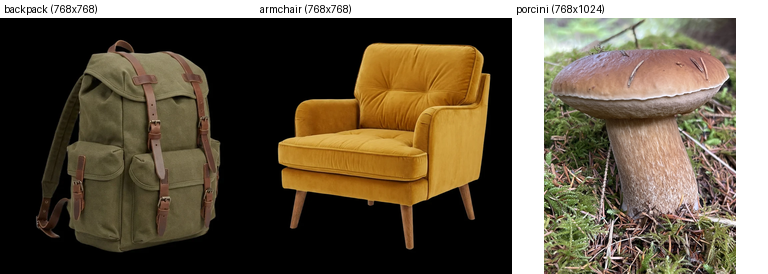

In [ ]:
run_stage('prepare')
show_image('inputs.png', 'Sample inputs: two Idol SDK demo images and one CC0 iNaturalist photograph')

<details>
<summary><strong>Check your reasoning</strong></summary>

BiRefNet: an image with no real alpha channel gets a predicted mask (`background_removal` says so). An RGBA image with transparent pixels would skip it and use its own alpha. The photograph is the hardest case: moss, needles and leaves around the stem are the kind of clutter a mask can include or bite into, which Section 6's mask column lets you check. The refusal probes show the contract is enforced before the GPU is touched.
</details>

## 5. Generate the splats [Concept]

Idol is loaded from the verified snapshots with both encoders replaced, then each sample runs with its upstream preset: 50 flow-matching steps, guidance 3.0, 262,144 Gaussians. `OPTIMIZE` turns on `torch.compile` and batched guidance: faster after a slow first image, but the compile step is the riskiest part on a T4, so it is off by default.

**Predict before running.** Idol's card quotes 7.2 GB of VRAM and under a minute per image on an L4. Will a T4 running eagerly be faster or slower, and by roughly how much?

In [ ]:
OPTIMIZE = False  # @param {type:"boolean"}
run_stage('generate', *(['--optimize'] if OPTIMIZE else []))
generation = load_record('generation.json')
for sample in generation['samples']:
    print({k: sample[k] for k in ('id', 'gaussians', 'seconds', 'camera', 'mask_replica_matches_sdk', 'ply_bytes')})

Running stage 'generate' in the isolated environment; log: /content/outputs/idol_3d/b396c789b1a0/logs/generate.log


Loading weights:   0%|          | 0/615 [00:00<?, ?it/s]


Loading weights:   3%|▎         | 16/615 [00:00<00:07, 85.10it/s]


Loading weights:   4%|▍         | 25/615 [00:00<00:09, 61.54it/s]


Loading weights:   6%|▌         | 35/615 [00:00<00:10, 55.20it/s]


Loading weights:   7%|▋         | 41/615 [00:00<00:12, 44.40it/s]


... (63 outputs left out)

{'id': 'armchair', 'gaussians': 262144, 'camera': {'yaw': 0.8681, 'pitch': 0.0317, 'radius': 4.4348, 'fov': 25.466}, 'seconds': 252.15, 'mask_replica_matches_sdk': True, 'ply': 'outputs/armchair/armchair.ply', 'ply_bytes': 17826208}


{'id': 'porcini', 'gaussians': 262144, 'camera': {'yaw': 1.8314, 'pitch': 0.2978, 'radius': 2.4741, 'fov': 45.5814}, 'seconds': 251.83, 'mask_replica_matches_sdk': True, 'ply': 'outputs/porcini/porcini.ply', 'ply_bytes': 17826208}


{'stage': 'generate', 'status': 'ok', 'seconds': 821.1}


{'id': 'backpack', 'gaussians': 262144, 'seconds': 233.48, 'camera': {'yaw': 2.2321, 'pitch': 0.074, 'radius': 3.1206, 'fov': 29.4339}, 'mask_replica_matches_sdk': True, 'ply_bytes': 17826208}
{'id': 'armchair', 'gaussians': 262144, 'seconds': 252.15, 'camera': {'yaw': 0.8681, 'pitch': 0.0317, 'radius': 4.4348, 'fov': 25.466}, 'mask_replica_matches_sdk': True, 'ply_bytes': 17826208}
{'id': 'porcini', 'gaussians': 262144, 'seconds': 251.83, 'camera': {'yaw': 1.8314, 'pitch': 0.2978, 'radius': 2.4741, 'fov': 45.5814}, 'mask_replica_matches_sdk': True, 'ply_bytes': 17826208}


<details>
<summary><strong>Check your reasoning</strong></summary>

Slower. A T4 has roughly half an L4's fp16 throughput, and eager mode gives up the card's ~1.7× speed-up from compilation and batched guidance, so several times the L4 figure is a reasonable expectation. The measured `seconds` below replace that estimate for this runtime.
</details>

**What to notice.** Each sample reports 262,144 Gaussians, a predicted camera, and `mask_replica_matches_sdk: True`, meaning the mask this package rebuilt comes from exactly the image Idol saw. The `seconds` are this runtime's measurement; compare them with your prediction.

## 6. Check and preview each splat [Evaluation practice]

There is no ground-truth 3D for these images, so the checks are the ones that need none. **Structure:** the Gaussians are finite, their centres within ±0.55 of the origin (Idol's [-0.5, 0.5]³ box plus a 0.05 margin for the decoder's offsets), with unit rotations and opacities in [0, 1]. **File:** the `.ply` reads back with the same count, the standard 3DGS fields and the same positions to within 10⁻⁵. If a structure or file check fails, or the rebuilt mask does not match the SDK's input, the stage stops after writing its record. **Input view:** the splat is rendered from the camera Idol predicted, and its silhouette is compared with the object mask (IoU). Idol's SDK documents neither the reference direction of its yaw nor how its field of view maps to the 1024 px input, so the renderer reads the camera with one fixed calibration (field of view × 0.725, yaw − 5°). It was fitted once, by leave-one-out on these three samples generated on a Colab T4 (fitted on two, scored on the third), and is applied unchanged to every splat; it is never re-fitted to make a sample score well. Four uncalibrated readings are recorded as diagnostics.

**Predict before running.** If the camera and the renderer agree with Idol's, should the silhouette IoU at the input view be near 0.5, near 0.9, or near 1.0? Why not exactly 1.0?

Running stage 'render' in the isolated environment; log: /content/outputs/idol_3d/b396c789b1a0/logs/render.log


{'id': 'backpack', 'verdict': 'well-formed', 'gaussians': 262144, 'ply_verified': True, 'silhouette_iou': 0.7755, 'uncalibrated_diagnostic': {'toward_camera': 0.5202, 'toward_camera_mirrored': 0.4654, 'view_direction': 0.439, 'view_direction_mirrored': 0.4606}}


{'id': 'armchair', 'verdict': 'well-formed', 'gaussians': 262144, 'ply_verified': True, 'silhouette_iou': 0.7586, 'uncalibrated_diagnostic': {'toward_camera': 0.4503, 'toward_camera_mirrored': 0.4332, 'view_direction': 0.4416, 'view_direction_mirrored': 0.4417}}


{'id': 'porcini', 'verdict': 'well-formed', 'gaussians': 262144, 'ply_verified': True, 'silhouette_iou': 0.9567, 'uncalibrated_diagnostic': {'toward_camera': 0.5121, 'toward_camera_mirrored': 0.3744, 'view_direction': 0.462, 'view_direction_mirrored': 0.4249}}


{'verdict': "passed: every splat well-formed, every .ply read back, every mask replica equal to the SDK's input", 'camera_calibration': {'fov_scale': 0.725, 'yaw_offset_deg': -5.0}, 'previews': 'outputs/previews.png', 'record': 'outputs/evaluation.json'}


{'stage': 'render', 'status': 'ok', 'seconds': 62.5}


Model input, mask, render from the predicted camera, and three turned views -> /content/outputs/idol_3d/b396c789b1a0/outputs/previews.png


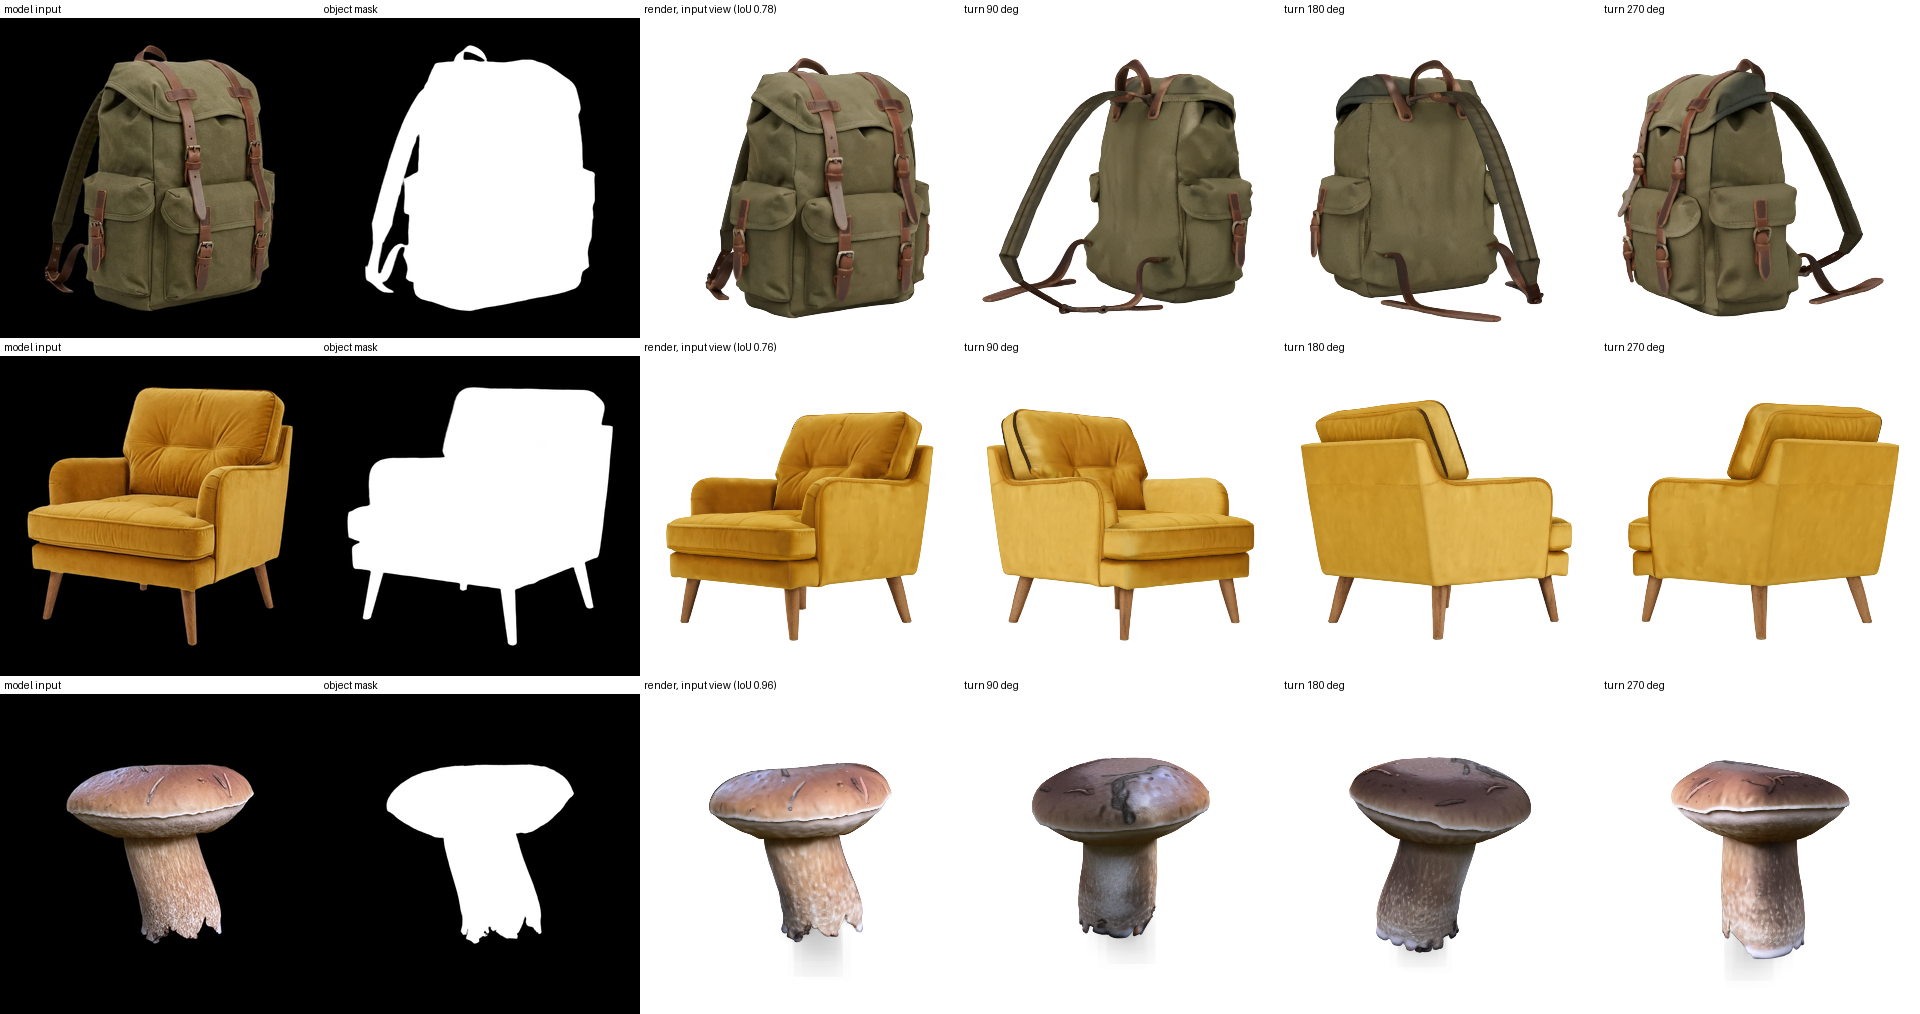

{'id': 'backpack', 'structure': 'well-formed', 'ply_verified': True, 'silhouette_iou': 0.7755, 'uncalibrated_diagnostic': {'toward_camera': 0.5202, 'toward_camera_mirrored': 0.4654, 'view_direction': 0.439, 'view_direction_mirrored': 0.4606}}
{'id': 'armchair', 'structure': 'well-formed', 'ply_verified': True, 'silhouette_iou': 0.7586, 'uncalibrated_diagnostic': {'toward_camera': 0.4503, 'toward_camera_mirrored': 0.4332, 'view_direction': 0.4416, 'view_direction_mirrored': 0.4417}}
{'id': 'porcini', 'structure': 'well-formed', 'ply_verified': True, 'silhouette_iou': 0.9567, 'uncalibrated_diagnostic': {'toward_camera': 0.5121, 'toward_camera_mirrored': 0.3744, 'view_direction': 0.462, 'view_direction_mirrored': 0.4249}}
{'camera_calibration': {'fov_scale': 0.725, 'yaw_offset_deg': -5.0, 'pitch_offset_deg': 0.0, 'convention': 'toward_camera', 'fitted': '2026-11-12, leave-one-out on three Colab T4 splats (backpack, armchair, porcini), tools/fit_camera_calibration.py; see the module docstr

In [ ]:
run_stage('render')
show_image('previews.png', 'Model input, mask, render from the predicted camera, and three turned views')
evaluation = load_record('evaluation.json')
for sample in evaluation['samples']:
    print({'id': sample['id'], 'structure': sample['structure']['verdict'], 'ply_verified': sample['ply_roundtrip']['verified'], 'silhouette_iou': sample['silhouette_iou'], 'uncalibrated_diagnostic': sample['silhouette_iou_uncalibrated_diagnostic']})
print({'camera_calibration': evaluation['camera_calibration']})

<details>
<summary><strong>Check your reasoning</strong></summary>

High, but not 1.0. The previews use an approximate NumPy renderer (footprints cut at 3σ and 24 px, colour from the degree-0 harmonic only), the mask was eroded by 1 px, and Idol predicts its camera rather than being told it, and one fixed calibration cannot suit every object (the best yaw differs by up to 40° between these three). Scored on the sample it was not fitted to, it gave 0.78 (backpack), 0.68 (armchair) and 0.87 (porcini); far below that, look at the preview row first: a misplaced or rotated render points to the camera reading, a ragged or broken shape to the splat. A high IoU says the visible side lines up. It says nothing about the back of the object.
</details>

## 7. Outputs [Engineering]

Each sample's folder under `outputs/` holds the `.ply`, the model input, its mask, the predicted camera and the input-view render; `generation.json` records the settings, timings, digests and snapshots; `evaluation.json` records every check. Open a `.ply` in any Gaussian-splat viewer for a faithful view.

In [ ]:
for path in sorted((ROOT / 'outputs').rglob('*')):
    if path.is_file():
        print(path.relative_to(ROOT), path.stat().st_size, 'bytes')

outputs/armchair/armchair.ply 17826208 bytes
outputs/armchair/armchair_camera.json 122 bytes
outputs/armchair/armchair_input.png 475138 bytes
outputs/armchair/armchair_mask.png 23840 bytes
outputs/armchair/armchair_render_input_view.png 53006 bytes
outputs/backpack/backpack.ply 17826208 bytes
outputs/backpack/backpack_camera.json 124 bytes
outputs/backpack/backpack_input.png 606178 bytes
outputs/backpack/backpack_mask.png 30596 bytes
outputs/backpack/backpack_render_input_view.png 70240 bytes
outputs/evaluation.json 5448 bytes
outputs/generation.json 3864 bytes
outputs/inputs.png 227829 bytes
outputs/porcini/porcini.ply 17826208 bytes
outputs/porcini/porcini_camera.json 121 bytes
outputs/porcini/porcini_input.png 360564 bytes
outputs/porcini/porcini_mask.png 17231 bytes
outputs/porcini/porcini_render_input_view.png 38876 bytes
outputs/previews.png 862227 bytes


## 7b. Optional activity: change one thing [Concept]

Off by default. **Predict → Change one thing → Run → Observe → Explain.** Pick one change for the first sample (the backpack): fewer flow-matching steps (`ACTIVITY_STEPS`, e.g. 25) or fewer Gaussians (`ACTIVITY_GAUSSIANS`, e.g. 32768). Before you tick `RUN_ACTIVITY`, write down what you expect to happen to the time, the `.ply` size and the silhouette IoU. The stage regenerates the backpack with your change, scores it with the same camera reading as the default run, and prints (default, changed) pairs.

In [ ]:
RUN_ACTIVITY = False  # @param {type:"boolean"}
ACTIVITY_STEPS = 25  # @param {type:"integer"}
ACTIVITY_GAUSSIANS = 262144  # @param ["32768", "65536", "131072", "262144", "524288"] {type:"raw"}
if RUN_ACTIVITY:
    run_stage('activity', '--steps', ACTIVITY_STEPS, '--num-gaussians', ACTIVITY_GAUSSIANS)
    show_image('activity_backpack/activity.png', 'Your change, scored the same way as the default')
else:
    print('Skipped: tick RUN_ACTIVITY to try one change on the backpack.')

Skipped: tick RUN_ACTIVITY to try one change on the backpack.


<details>
<summary><strong>Check your reasoning</strong></summary>

Fewer steps cut the denoiser's time almost proportionally (each step is two transformer passes) but leave the decoders' time unchanged; the shape usually survives and fine detail goes first, which a silhouette barely registers. Fewer Gaussians shrink the `.ply` in proportion and speed up the decoders, not the denoiser; the silhouette can stay close because each Gaussian grows to cover the same surface. If the IoU moves by a few hundredths, remember it is one image and one seed.
</details>

## What did not work

- **Loading the VAE from FLUX.2-dev**, as Idol's own configuration does: its non-commercial licence rules it out for this fleet. The FLUX.2 [klein] 4B copy replaced it after a bit-for-bit comparison of all 251 tensors (in bf16, the precision Idol uses).
- **`gsplat`, the usual Gaussian-splat rasterizer**: it has no binary wheel that a hash-locked, binary-only install can use, so the previews use the small NumPy renderer in `render.py` instead.
- **Reading Idol's camera as documented**: taking the SDK's yaw and field of view at face value rendered the backpack front-on and at half size (silhouette IoU 0.33). Searching yaw, pitch, mirroring and field-of-view scale on two reduced 12-step CPU splats found one reading (field of view × 0.6, yaw + 25°) that scored 0.88 on them and 0.48–0.73 on the first full-setting T4 splats: a calibration scored on the splats it was fitted to overstates itself. It was re-fitted by leave-one-out on the three T4 splats (field of view × 0.725, yaw − 5°), now fixed in `render.py`; picking the best reading per sample was dropped because it lets the metric choose its own conditions.
- **Installing the Idol SDK from GitHub**: it is not on PyPI, and a source build would need tools outside the lock, so the notebook carries the SDK's files verbatim instead.

## Interpretation and conclusion [Evaluation practice]

**What this run shows.** Idol ran from digest-verified local snapshots: DINOv3 is the same gated model Idol names, and the VAE is the Apache-2.0 FLUX.2 [klein] copy in place of FLUX.2-dev. It produced well-formed splats whose `.ply` files read back with the same count, fields and positions. The silhouette IoU says how well the visible side lines up with the input, through an approximate renderer [6].

**What it does not show.** That the unseen sides are right: there is no reference for them here. That the klein VAE equals the dev VAE: Section 8 tests that and needs FLUX.2-dev access. That three images represent anything beyond themselves: two come from the model's own demo and may resemble its undisclosed training data, so this is tutorial evidence, not a performance estimate.

**Write your conclusion** in three sentences: what was generated, which checks passed with which numbers, and the one limit you consider most important.

## 8. Optional: is the klein VAE the FLUX.2-dev VAE? [Evaluation practice]

Off by default. With `RUN_VAE_CHECK` ticked and an `HF_TOKEN` whose account has accepted the FLUX.2-dev terms, the `vae_check` stage downloads the dev VAE (336 MB) for this check only, compares every tensor cast to bf16 with the klein VAE bit for bit, and runs Idol's own VAE encoding with each on the same image beside a dev-vs-dev rerun that measures this GPU's noise floor. FLUX.2-dev is never used for generation.

In [ ]:
RUN_VAE_CHECK = False  # @param {type:"boolean"}
if RUN_VAE_CHECK:
    run_stage('vae_check')
    print(load_record('vae_check.json')['verdict'])
else:
    print('Skipped: tick RUN_VAE_CHECK to run the klein-vs-dev VAE check (needs FLUX.2-dev access).')

Skipped: tick RUN_VAE_CHECK to run the klein-vs-dev VAE check (needs FLUX.2-dev access).


## 9. Optional: Bring Your Own Data [Evaluation practice]

Off by default. Tick `USE_BYOD`, choose `BYOD_MODE` (`'real'` for photographs, `'synthetic'` for renders and generated images), and either set `BYOD_PATH` to an image, folder or zip in this runtime or leave it empty for an upload dialog. Up to four images are used. A refused image stops with one message naming the file and the rule.

In [ ]:
USE_BYOD = False  # @param {type:"boolean"}
BYOD_MODE = 'real'  # @param ["real", "synthetic"]
BYOD_PATH = ''  # @param {type:"string"}
if USE_BYOD:
    if not BYOD_PATH:
        from google.colab import files
        upload_dir = ROOT / 'byod_upload'
        shutil.rmtree(upload_dir, ignore_errors=True)  # a fresh upload replaces the last one
        upload_dir.mkdir()
        for name, data in files.upload().items():
            (upload_dir / name).write_bytes(data)
        BYOD_PATH = str(upload_dir)
    try:
        run_stage('byod', '--byod-path', BYOD_PATH, '--byod-mode', BYOD_MODE)
    except RuntimeError as failure:
        if not str(failure).split('): ', 1)[-1].startswith('InputRefused:'):
            raise  # a genuine failure, not a refused input
        print('BYOD refused your input:', str(failure).split(': ', 1)[-1])
        print('Fix the input named above, then run this cell again; the default results above are unchanged.')
    else:
        show_image('idol_3d_byod/previews.png', 'Your images')
else:
    print('Skipped: tick USE_BYOD to run your own images.')

Skipped: tick USE_BYOD to run your own images.


## Troubleshooting

- **`No HF_TOKEN secret is readable`** — add the secret, switch on notebook access, rerun the Token cell, then the cells after it.
- **`403` or `gated` while staging DINOv3** — the token's account has not been approved for DINOv3 yet; approval is manual.
- **`has no recorded size/SHA-256`** — the DINOv3 manifest is not pinned yet; the maintainer runs `tools/pin_snapshot.py dinov3-vith16plus` and regenerates the notebook.
- **`No GPU is attached` (Section 1) or `needs a CUDA GPU`** — switch the runtime to a T4 GPU and Run all again.
- **A GPU is attached but `needs a CUDA GPU` still appears** — the isolated environment's torch is the CUDA 13 build; a runtime whose NVIDIA driver is older cannot run it. Start a fresh Colab runtime (Colab's current images carry a newer driver) and report the driver version (`nvidia-smi`) if it persists.
- **`Not enough free disk`** — start a fresh runtime; the weights (about 6.6 GB) and the environment (about 9 GB) need room.
- **`differs from the manifest this notebook carries`** — the weights folder came from another notebook revision: delete the folder named in the message, or start a fresh runtime.
- **Out of GPU memory** — restart the runtime (*Runtime → Restart session*: the isolated environment and the weights on disk are kept and reused) and keep `OPTIMIZE = False`.

## References

[1] Sperid Labs. 2026. Idol: a single image to a 3D Gaussian splat. Model card and SDK. https://huggingface.co/speridlabs/idol ; https://github.com/speridlabs/idol-sdk

[2] Bernhard Kerbl, Georgios Kopanas, Thomas Leimkühler, and George Drettakis. 2023. 3D Gaussian Splatting for Real-Time Radiance Field Rendering. ACM Trans. Graph. 42, 4, Article 139. https://doi.org/10.1145/3592433

[3] Yaron Lipman, Ricky T. Q. Chen, Heli Ben-Hamu, Maximilian Nickel, and Matt Le. 2023. Flow Matching for Generative Modeling. In ICLR 2023. https://arxiv.org/abs/2210.02747

[4] Oriane Siméoni et al. 2025. DINOv3. arXiv:2508.10104. https://arxiv.org/abs/2508.10104

[5] Peng Zheng et al. 2024. Bilateral Reference for High-Resolution Dichotomous Image Segmentation. CAAI Artificial Intelligence Research 3. https://doi.org/10.26599/AIR.2024.9150038

[6] Matthias Zwicker, Hanspeter Pfister, Jeroen van Baar, and Markus Gross. 2002. EWA Splatting. IEEE Trans. Vis. Comput. Graph. 8, 3, 223–238. https://doi.org/10.1109/TVCG.2002.1021576

[7] Black Forest Labs. 2026. FLUX.2 [klein] 4B. https://huggingface.co/black-forest-labs/FLUX.2-klein-4B